# House Prices — Quy trình hoàn chỉnh: EDA → Tiền xử lý → Feature Selection → Mô hình

Notebook tổng hợp từ 4 file: `phase1_eda.py`, `giaidoan2.ipynb`, `preprocessing_house_prices.ipynb`, `Lab04_Feature_Selection.ipynb`.

| Giai đoạn | Nội dung | Nguồn |
|---|---|---|
| 1 | Khám phá dữ liệu (EDA): kích thước, loại đặc trưng, dữ liệu thiếu, phân phối `SalePrice`, tương quan | `phase1_eda.py` |
| 2 | Tiền xử lý: 2.1 Dữ liệu thiếu · 2.2 Outlier · 2.3 Categorical · 2.4 Numerical | `giaidoan2.ipynb`, `preprocessing_house_prices.ipynb` |
| 3–4 | Feature Selection (Filter / Wrapper / Embedded), thí nghiệm tăng dần K, xây dựng và đánh giá SVR · XGBoost · Random Forest | `Lab04_Feature_Selection.ipynb` |

**Cách chạy:** đặt `train.csv`, `test.csv` cùng thư mục với notebook (hoặc sửa `DATA_DIR` ở ô bên dưới), chọn *Restart Kernel → Run All*. Mỗi giai đoạn đọc dữ liệu thô và tự định nghĩa mọi biến nó cần; toàn bộ kết quả xuất ra thư mục `outputs/` (mỗi giai đoạn một thư mục con). Giai đoạn 3–4 mất khoảng 25–30 phút trên máy 1 CPU.

## 0. Cấu hình chung

In [1]:
from pathlib import Path

DATA_DIR = Path('/mnt/user-data/uploads') if (Path('/mnt/user-data/uploads') / 'train.csv').exists() else Path('.')
BASE_OUT = Path('outputs'); BASE_OUT.mkdir(exist_ok=True)
print('Dữ liệu:', DATA_DIR.resolve(), '| Thư mục xuất:', BASE_OUT.resolve())

Dữ liệu: /mnt/user-data/uploads | Thư mục xuất: /home/claude/combined/outputs


# GIAI ĐOẠN 1 — Chọn dataset và khám phá dữ liệu (EDA)
Dataset: House Prices — Advanced Regression Techniques (Ames, Iowa). Target: `SalePrice`.

Lưu ý khi đọc dữ liệu: giá trị `"NA"` trong file là một mức hợp lệ (ví dụ "không có hầm"), nên giai đoạn này đọc với `keep_default_na=False` rồi mới đếm riêng "NA có nghĩa" và "thiếu thật". Phần xuất báo cáo Word ở cuối `phase1_eda.py` không đưa vào notebook; mọi bảng và biểu đồ vẫn được tạo và lưu vào `outputs/phase1_eda/`.

## 1.0 Cấu hình và import

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ------------------------------------------------------------------
# 0. CẤU HÌNH
# ------------------------------------------------------------------
OUT_DIR = BASE_OUT / 'phase1_eda'   # nơi lưu bảng + hình
TARGET = "SalePrice"
SHOW_PLOTS = True         # hiện biểu đồ ngay trong notebook
os.makedirs(OUT_DIR, exist_ok=True)
FIGS = {}                 # tên file -> đường dẫn, dùng khi dựng báo cáo Word

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110


def save_show(fig, name):
    fig.tight_layout()
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIGS[name] = path
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

## 1.1 Đọc dữ liệu

In [3]:
# Lưu ý: giá trị "NA" trong file là một mức hợp lệ (vd: "không có hầm"),
# nên phải tắt chuyển đổi NA -> NaN tự động khi đọc, rồi xử lý riêng.
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), keep_default_na=False, na_values=[""])
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"), keep_default_na=False, na_values=[""])

# Với cột số, "NA" (chuỗi) thực sự là dữ liệu thiếu -> chuyển lại thành NaN
for df in (train, test):
    for col in ["LotFrontage", "MasVnrArea", "GarageYrBlt"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].replace("NA", np.nan), errors="coerce")

## 1.2 Biến mục tiêu và kích thước dữ liệu

In [4]:
print("=" * 70)
print(f"Biến mục tiêu (target): {TARGET}")
print(f"Train: {train.shape[0]} hàng x {train.shape[1]} cột")
print(f"Test : {test.shape[0]} hàng x {test.shape[1]} cột (không có {TARGET})")
print(f"Cột có trong train nhưng không có trong test: {set(train.columns) - set(test.columns)}")
print(f"Số dòng trùng lặp (train): {train.duplicated().sum()}")
print(f"Id trùng lặp (train): {train['Id'].duplicated().sum()}")

Biến mục tiêu (target): SalePrice
Train: 1460 hàng x 81 cột
Test : 1459 hàng x 80 cột (không có SalePrice)
Cột có trong train nhưng không có trong test: {'SalePrice'}
Số dòng trùng lặp (train): 0
Id trùng lặp (train): 0


## 1.3 Phân loại đặc trưng (Numerical / Categorical / Ordinal)

In [5]:
# --- Ordinal: có thứ tự rõ ràng (theo data_description.txt) ---
ORDINAL_ORDERS = {
    "ExterQual":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual":     ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond":     ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure": ["NA", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "HeatingQC":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual":  ["Po", "Fa", "TA", "Gd", "Ex"],
    "FireplaceQu":  ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageFinish": ["NA", "Unf", "RFn", "Fin"],
    "GarageQual":   ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond":   ["NA", "Po", "Fa", "TA", "Gd", "Ex"],
    "PoolQC":       ["NA", "Fa", "TA", "Gd", "Ex"],
    "Fence":        ["NA", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Functional":   ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "LotShape":     ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope":    ["Sev", "Mod", "Gtl"],
    "Utilities":    ["ELO", "NoSeWa", "NoSewr", "AllPub"],
    "PavedDrive":   ["N", "P", "Y"],
    "CentralAir":   ["N", "Y"],
}
# Ordinal đã được mã hoá sẵn bằng số (1-10)
ORDINAL_NUMERIC = ["OverallQual", "OverallCond"]
ORDINAL_COLS = list(ORDINAL_ORDERS.keys()) + ORDINAL_NUMERIC

# --- Cột số nhưng bản chất là categorical (nominal) ---
NUMERIC_BUT_CATEGORICAL = ["MSSubClass"]
# Tháng bán: có tính chu kỳ, thường coi là categorical
NUMERIC_BUT_CATEGORICAL += ["MoSold"]

ID_COLS = ["Id"]

features = [c for c in train.columns if c not in ID_COLS + [TARGET]]

ordinal_features = [c for c in features if c in ORDINAL_COLS]
categorical_features = [
    c for c in features
    if c not in ordinal_features
    and (not pd.api.types.is_numeric_dtype(train[c]) or c in NUMERIC_BUT_CATEGORICAL)
]
numerical_features = [
    c for c in features
    if c not in ordinal_features + categorical_features
]
# Chia nhỏ numerical thành rời rạc / liên tục (để tham khảo)
discrete_num = [c for c in numerical_features if train[c].nunique() <= 15]
continuous_num = [c for c in numerical_features if c not in discrete_num]

print("\n" + "=" * 70)
print(f"Numerical   : {len(numerical_features)} (liên tục: {len(continuous_num)}, rời rạc: {len(discrete_num)})")
print(f"Categorical : {len(categorical_features)}")
print(f"Ordinal     : {len(ordinal_features)}")
print(f"Tổng        : {len(numerical_features) + len(categorical_features) + len(ordinal_features)} / {len(features)}")


Numerical   : 32 (liên tục: 21, rời rạc: 11)
Categorical : 24
Ordinal     : 23
Tổng        : 79 / 79


## 1.4 Bảng mô tả dữ liệu

In [6]:
def feature_type(col):
    if col == TARGET:
        return "Target"
    if col in ID_COLS:
        return "ID"
    if col in ordinal_features:
        return "Ordinal"
    if col in categorical_features:
        return "Categorical"
    return "Numerical"


desc_rows = []
for col in train.columns:
    s = train[col]
    row = {
        "Feature": col,
        "Type": feature_type(col),
        "Dtype": str(s.dtype),
        "Non-null": int(s.notna().sum()),
        "Missing": int(s.isna().sum()),
        "Unique": int(s.nunique()),
    }
    if pd.api.types.is_numeric_dtype(s):
        row.update({
            "Mean": round(s.mean(), 2), "Std": round(s.std(), 2),
            "Min": s.min(), "25%": s.quantile(.25), "Median": s.median(),
            "75%": s.quantile(.75), "Max": s.max(),
            "Skew": round(s.skew(), 2),
        })
    else:
        top = s.value_counts()
        row.update({"Top value": top.index[0], "Top freq (%)": round(top.iloc[0] / len(s) * 100, 1)})
    desc_rows.append(row)

desc_table = pd.DataFrame(desc_rows)
desc_table.to_csv(os.path.join(OUT_DIR, "data_description_table.csv"), index=False, encoding="utf-8-sig")
print("\n=== BẢNG MÔ TẢ DỮ LIỆU ===")
print(desc_table.to_string(index=False))

# Bảng tổng hợp theo loại đặc trưng
type_summary = pd.DataFrame({
    "Loại": ["Numerical", "Categorical", "Ordinal"],
    "Số lượng": [len(numerical_features), len(categorical_features), len(ordinal_features)],
    "Danh sách": [", ".join(numerical_features), ", ".join(categorical_features), ", ".join(ordinal_features)],
})
type_summary.to_csv(os.path.join(OUT_DIR, "feature_type_summary.csv"), index=False, encoding="utf-8-sig")
print("\n=== PHÂN LOẠI ĐẶC TRƯNG ===")
for _, r in type_summary.iterrows():
    print(f"\n[{r['Loại']}] ({r['Số lượng']}):\n  {r['Danh sách']}")


=== BẢNG MÔ TẢ DỮ LIỆU ===
      Feature        Type   Dtype  Non-null  Missing  Unique      Mean      Std     Min       25%   Median       75%      Max  Skew Top value  Top freq (%)
           Id          ID   int64      1460        0    1460    730.50   421.61     1.0    365.75    730.5   1095.25   1460.0  0.00       NaN           NaN
   MSSubClass Categorical   int64      1460        0      15     56.90    42.30    20.0     20.00     50.0     70.00    190.0  1.41       NaN           NaN
     MSZoning Categorical     str      1460        0       5       NaN      NaN     NaN       NaN      NaN       NaN      NaN   NaN        RL          78.8
  LotFrontage   Numerical float64      1201      259     110     70.05    24.28    21.0     59.00     69.0     80.00    313.0  2.16       NaN           NaN
      LotArea   Numerical   int64      1460        0    1073  10516.83  9981.26  1300.0   7553.50   9478.5  11601.50 215245.0 12.21       NaN           NaN
       Street Categorical     str   

## 1.5 Thống kê dữ liệu thiếu


=== BẢNG DỮ LIỆU THIẾU (TRAIN) ===
              Missing_count  Missing_pct           Ý nghĩa của NA    Dtype
Feature                                                                   
PoolQC                 1453        99.52          Không có hồ bơi      str
MiscFeature            1406        96.30   Không có tiện ích khác      str
Alley                  1369        93.77      Không có lối đi phụ      str
Fence                  1179        80.75        Không có hàng rào      str
FireplaceQu             690        47.26         Không có lò sưởi      str
LotFrontage             259        17.74  Thiếu thật - cần impute  float64
GarageCond               81         5.55            Không có gara      str
GarageType               81         5.55            Không có gara      str
GarageYrBlt              81         5.55  Thiếu thật - cần impute  float64
GarageFinish             81         5.55            Không có gara      str
GarageQual               81         5.55            Không có gar

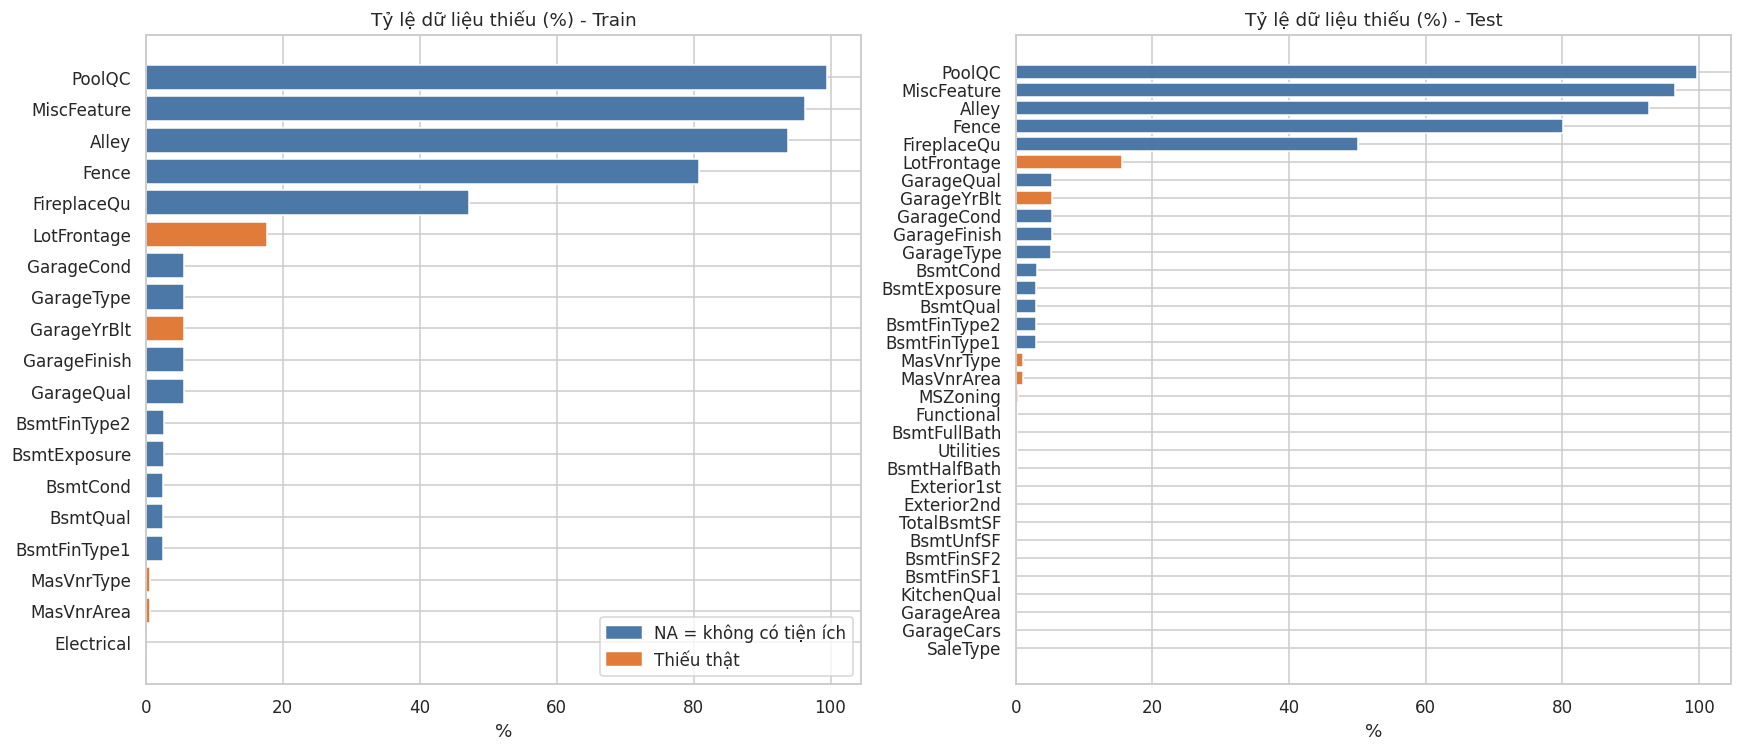

In [7]:
# Cột nào mà "NA" nghĩa là "không có tiện ích" (không phải thiếu thật)
NA_MEANS_NONE = {
    "Alley": "Không có lối đi phụ", "BsmtQual": "Không có hầm", "BsmtCond": "Không có hầm",
    "BsmtExposure": "Không có hầm", "BsmtFinType1": "Không có hầm", "BsmtFinType2": "Không có hầm",
    "FireplaceQu": "Không có lò sưởi", "GarageType": "Không có gara", "GarageFinish": "Không có gara",
    "GarageQual": "Không có gara", "GarageCond": "Không có gara", "PoolQC": "Không có hồ bơi",
    "Fence": "Không có hàng rào", "MiscFeature": "Không có tiện ích khác",
}


def count_missing(df, name):
    """Đếm thiếu = NaN thật + chuỗi 'NA' (theo ý nghĩa mô tả)."""
    na_str = (df == "NA").sum()
    nan = df.isna().sum()
    total = na_str + nan
    out = pd.DataFrame({
        "Missing_count": total,
        "Missing_pct": (total / len(df) * 100).round(2),
    })
    out = out[out["Missing_count"] > 0].sort_values("Missing_count", ascending=False)
    out["Ý nghĩa của NA"] = [NA_MEANS_NONE.get(c, "Thiếu thật - cần impute") for c in out.index]
    out["Dtype"] = df.dtypes[out.index].astype(str)
    out.index.name = "Feature"
    return out


missing_train = count_missing(train, "train")
missing_test = count_missing(test, "test")
missing_train.to_csv(os.path.join(OUT_DIR, "missing_train.csv"), encoding="utf-8-sig")
missing_test.to_csv(os.path.join(OUT_DIR, "missing_test.csv"), encoding="utf-8-sig")

print("\n=== BẢNG DỮ LIỆU THIẾU (TRAIN) ===")
print(missing_train.to_string())
print("\n=== BẢNG DỮ LIỆU THIẾU (TEST) ===")
print(missing_test.to_string())

# Biểu đồ tỷ lệ thiếu
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, miss, title in zip(axes, [missing_train, missing_test], ["Train", "Test"]):
    colors = ["#e07b39" if "Thiếu thật" in m else "#4c78a8" for m in miss["Ý nghĩa của NA"]]
    ax.barh(miss.index[::-1], miss["Missing_pct"][::-1], color=colors[::-1])
    ax.set_title(f"Tỷ lệ dữ liệu thiếu (%) - {title}")
    ax.set_xlabel("%")
axes[0].legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color="#4c78a8"),
    plt.Rectangle((0, 0), 1, 1, color="#e07b39"),
], labels=["NA = không có tiện ích", "Thiếu thật"], loc="lower right")
save_show(fig, "missing_values.png")

## 1.6 Phân phối của SalePrice


=== THỐNG KÊ SalePrice ===
count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
Skewness : 1.883
Kurtosis : 6.536
Skewness sau log1p : 0.121
Kurtosis sau log1p : 0.810
Shapiro-Wilk p (gốc)  : 3.206e-33
Shapiro-Wilk p (log1p): 1.149e-07
Số outlier theo IQR: 61 (4.18%)


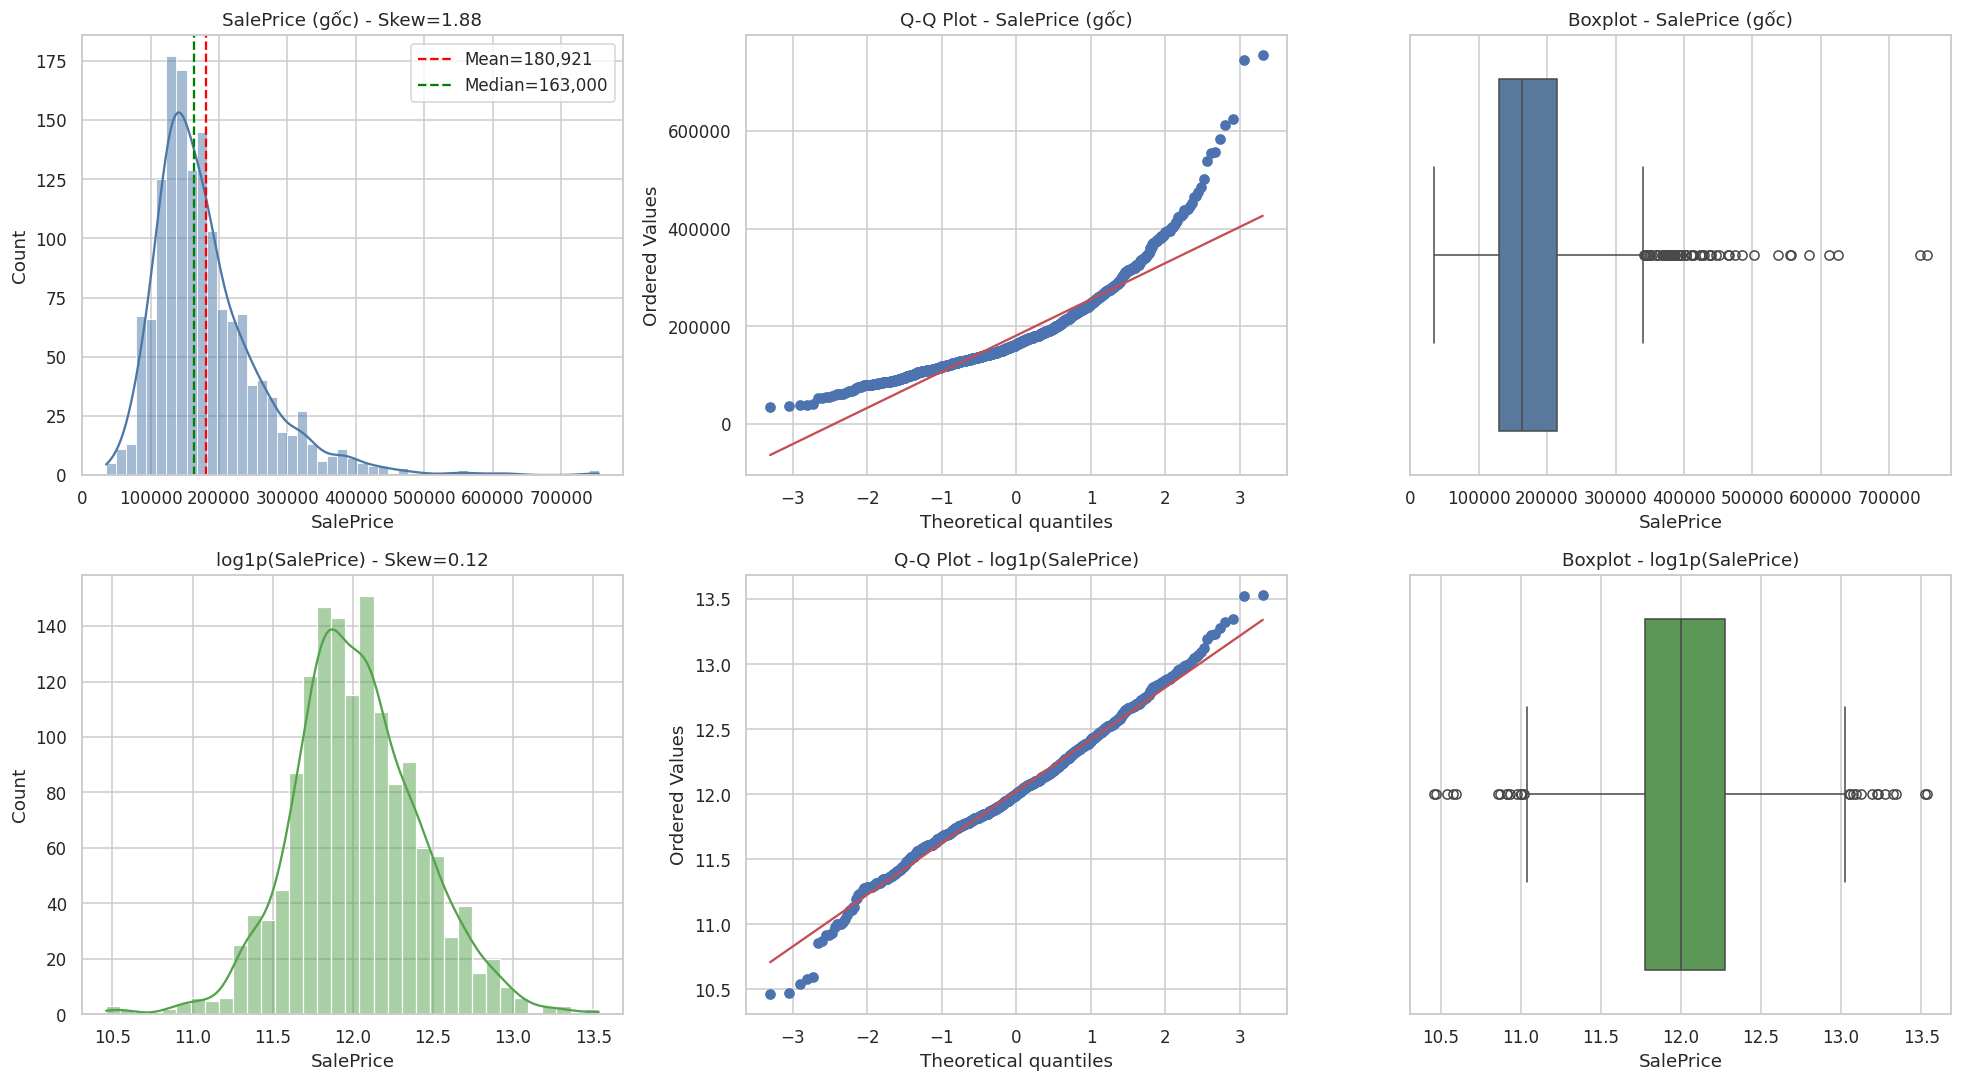

In [8]:
y = train[TARGET]
print("\n=== THỐNG KÊ SalePrice ===")
print(y.describe().round(2))
print(f"Skewness : {y.skew():.3f}")
print(f"Kurtosis : {y.kurt():.3f}")
log_y = np.log1p(y)
print(f"Skewness sau log1p : {log_y.skew():.3f}")
print(f"Kurtosis sau log1p : {log_y.kurt():.3f}")
print(f"Shapiro-Wilk p (gốc)  : {stats.shapiro(y)[1]:.3e}")
print(f"Shapiro-Wilk p (log1p): {stats.shapiro(log_y)[1]:.3e}")

# Phát hiện outlier bằng IQR
q1, q3 = y.quantile([.25, .75])
iqr = q3 - q1
outliers = y[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]
print(f"Số outlier theo IQR: {len(outliers)} ({len(outliers) / len(y) * 100:.2f}%)")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Hàng 1: SalePrice gốc
sns.histplot(y, kde=True, ax=axes[0, 0], color="#4c78a8")
axes[0, 0].axvline(y.mean(), color="red", ls="--", label=f"Mean={y.mean():,.0f}")
axes[0, 0].axvline(y.median(), color="green", ls="--", label=f"Median={y.median():,.0f}")
axes[0, 0].set_title(f"SalePrice (gốc) - Skew={y.skew():.2f}")
axes[0, 0].legend()

stats.probplot(y, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot - SalePrice (gốc)")

sns.boxplot(x=y, ax=axes[0, 2], color="#4c78a8")
axes[0, 2].set_title("Boxplot - SalePrice (gốc)")

# Hàng 2: sau log1p
sns.histplot(log_y, kde=True, ax=axes[1, 0], color="#54a24b")
axes[1, 0].set_title(f"log1p(SalePrice) - Skew={log_y.skew():.2f}")

stats.probplot(log_y, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot - log1p(SalePrice)")

sns.boxplot(x=log_y, ax=axes[1, 2], color="#54a24b")
axes[1, 2].set_title("Boxplot - log1p(SalePrice)")

save_show(fig, "saleprice_distribution.png")

## 1.7 Heatmap tương quan

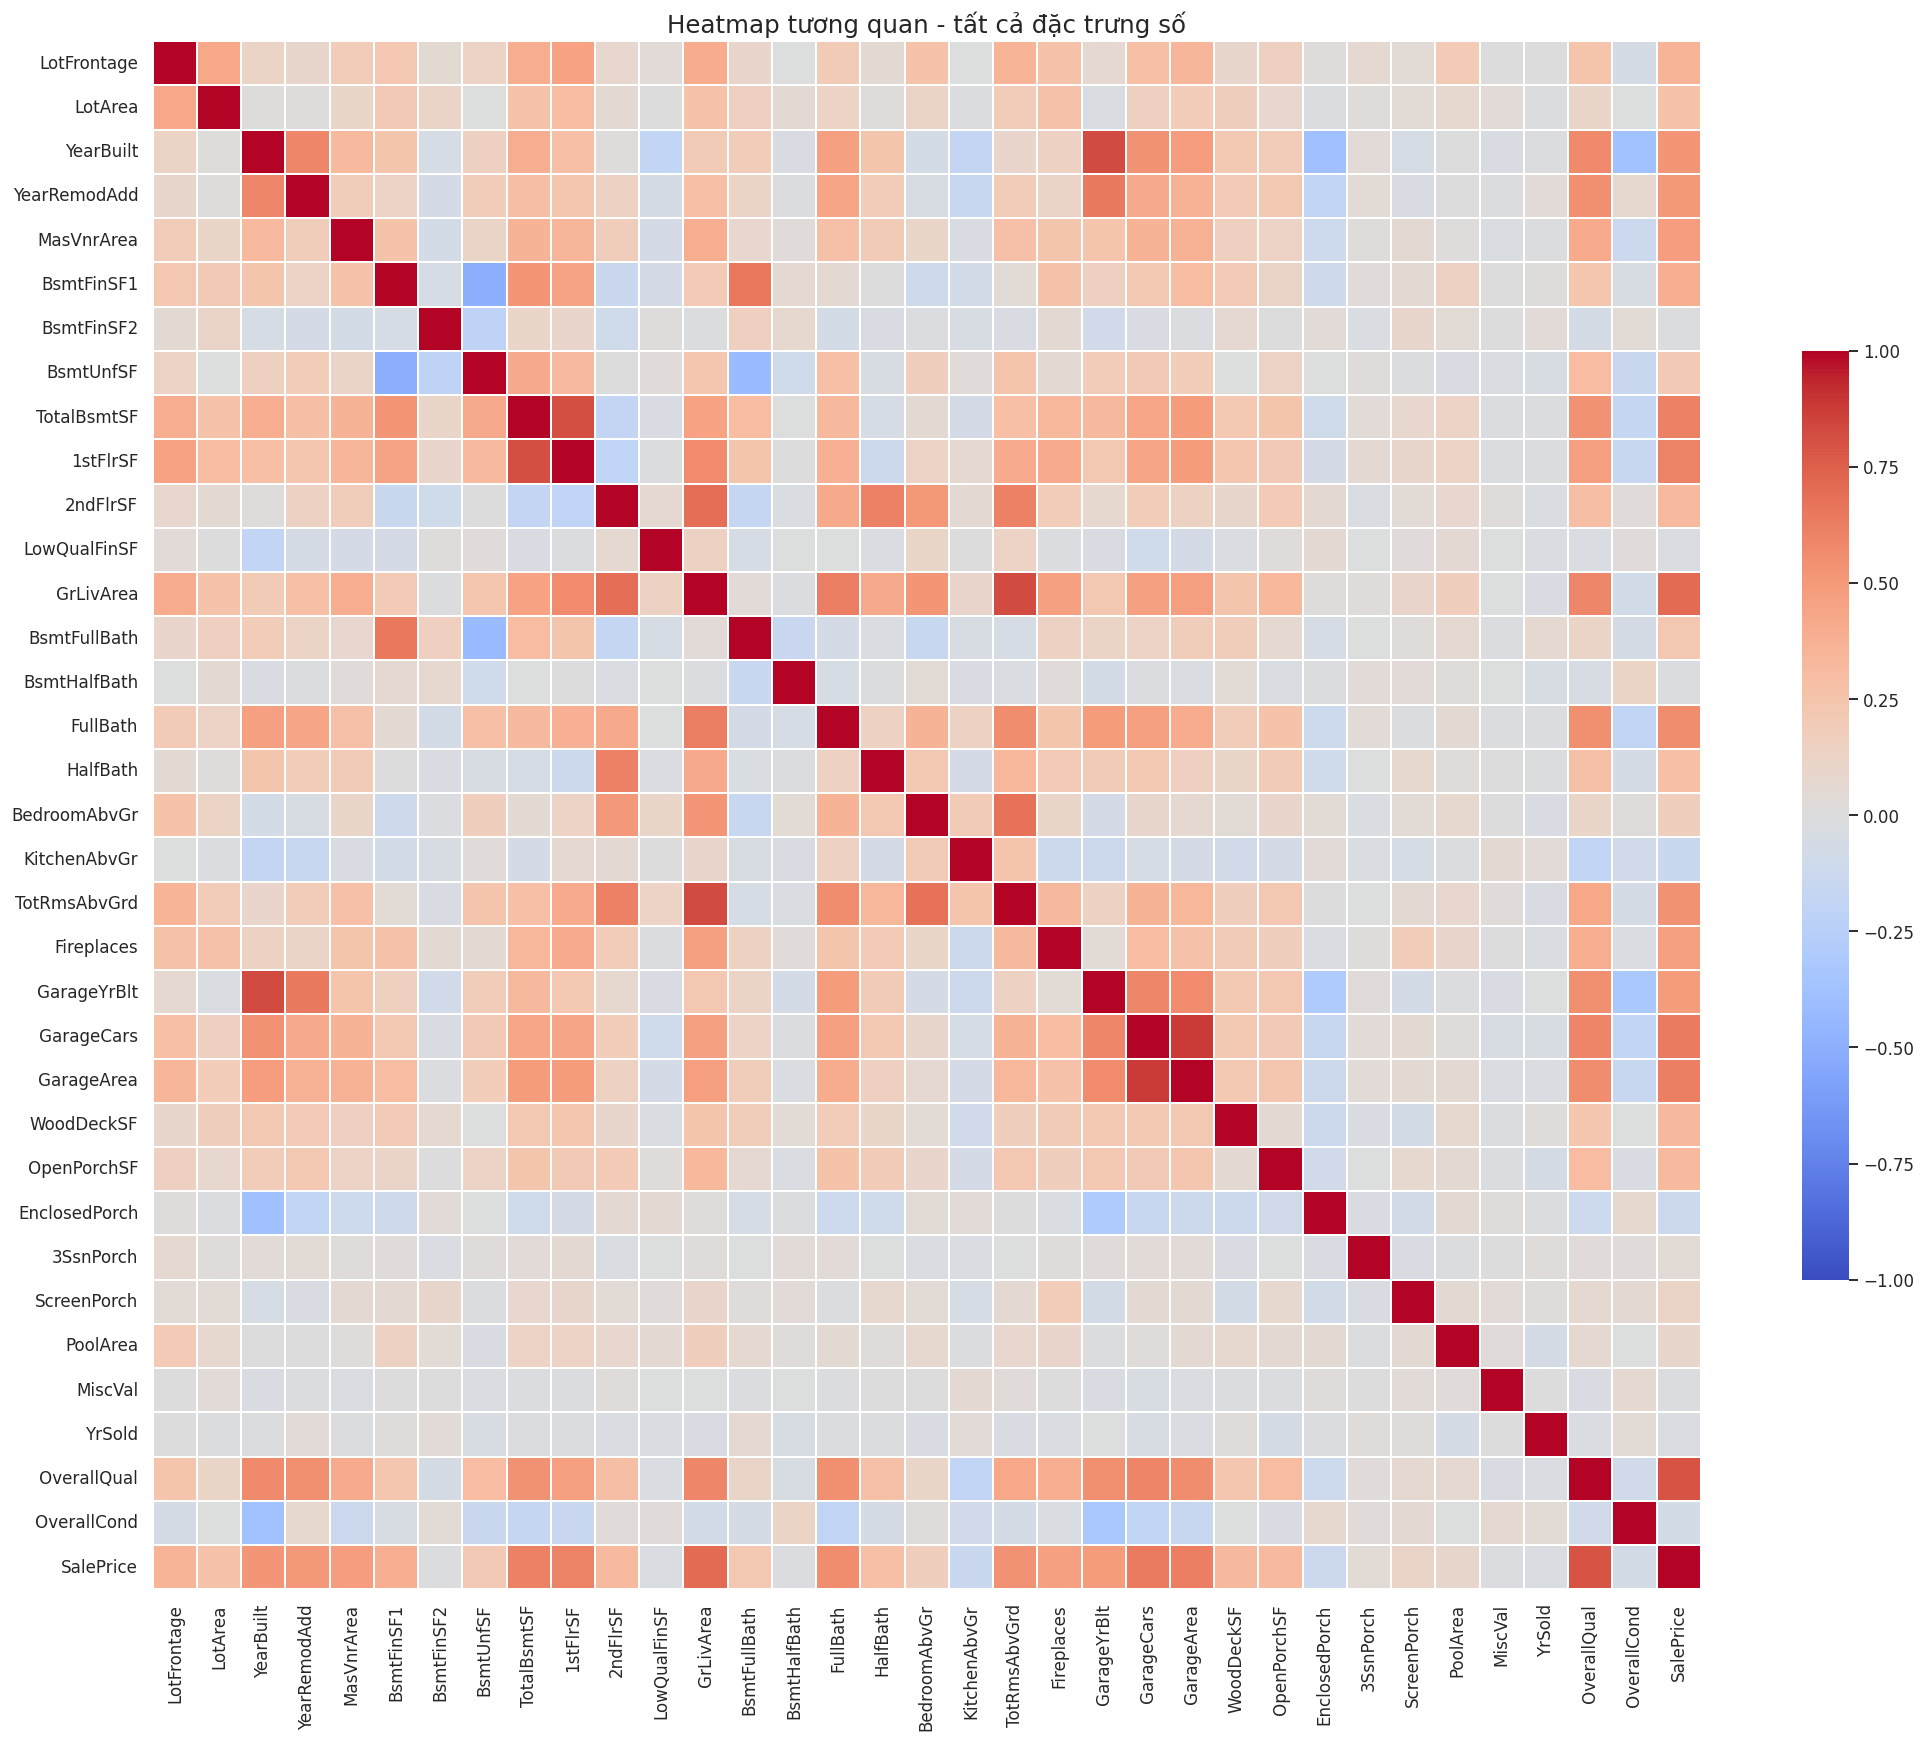

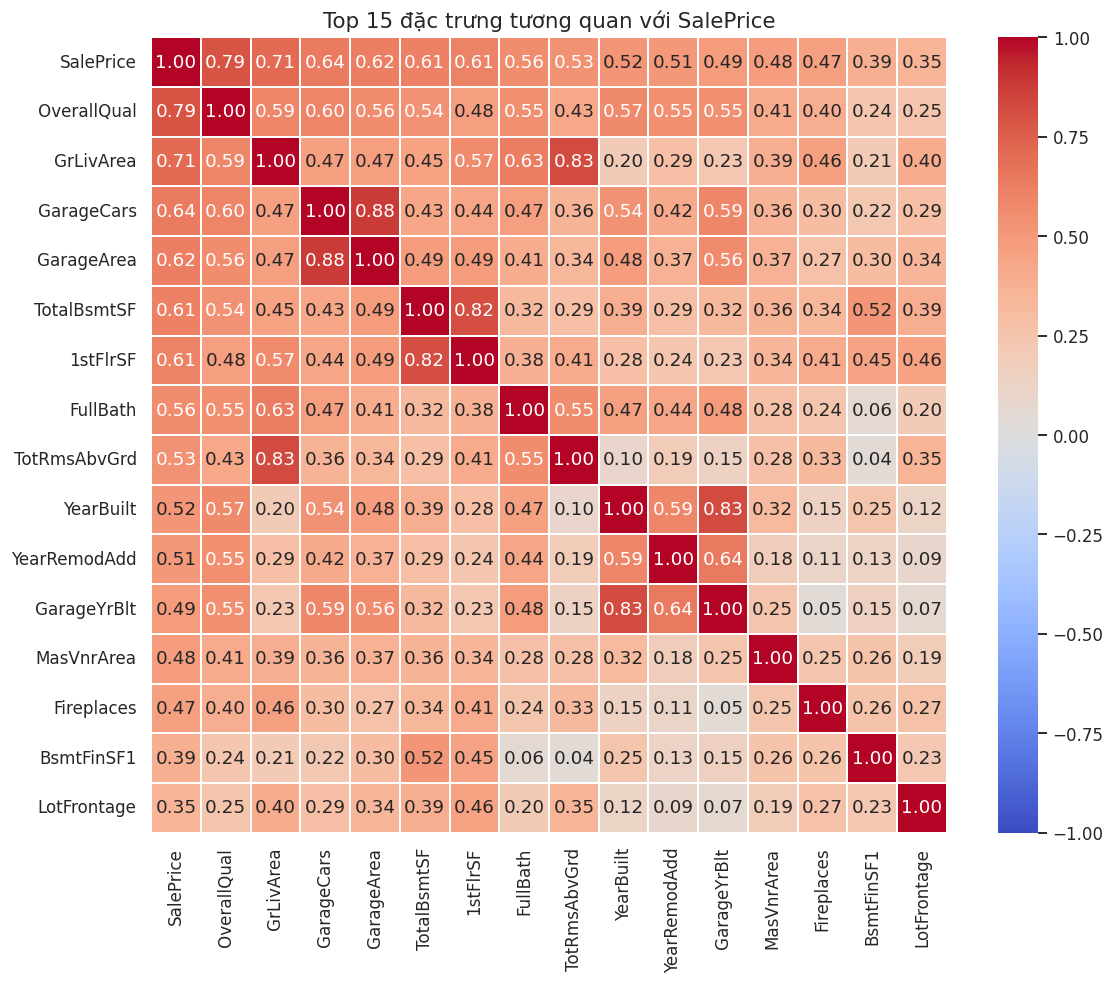


=== TƯƠNG QUAN VỚI SalePrice (Pearson) ===
OverallQual      0.791
GrLivArea        0.709
GarageCars       0.640
GarageArea       0.623
TotalBsmtSF      0.614
1stFlrSF         0.606
FullBath         0.561
TotRmsAbvGrd     0.534
YearBuilt        0.523
YearRemodAdd     0.507
GarageYrBlt      0.486
MasVnrArea       0.477
Fireplaces       0.467
BsmtFinSF1       0.386
LotFrontage      0.352
WoodDeckSF       0.324
2ndFlrSF         0.319
OpenPorchSF      0.316
HalfBath         0.284
LotArea          0.264
BsmtFullBath     0.227
BsmtUnfSF        0.214
BedroomAbvGr     0.168
ScreenPorch      0.111
PoolArea         0.092
3SsnPorch        0.045
BsmtFinSF2      -0.011
BsmtHalfBath    -0.017
MiscVal         -0.021
LowQualFinSF    -0.026
YrSold          -0.029
OverallCond     -0.078
EnclosedPorch   -0.129
KitchenAbvGr    -0.136


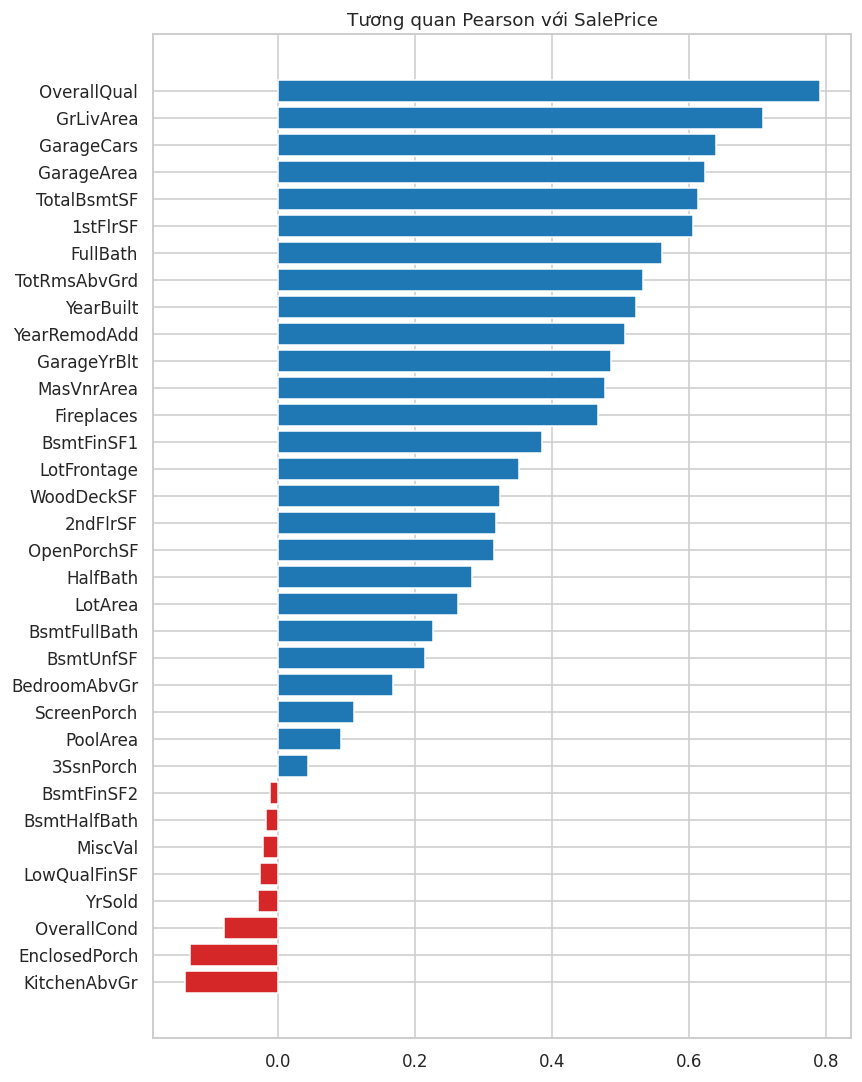


=== CÁC CẶP ĐẶC TRƯNG TƯƠNG QUAN CAO (|r| > 0.8) -> nguy cơ đa cộng tuyến ===
  Feature_1    Feature_2     Corr
 GarageCars   GarageArea 0.882475
  YearBuilt  GarageYrBlt 0.825667
  GrLivArea TotRmsAbvGrd 0.825489
TotalBsmtSF     1stFlrSF 0.819530


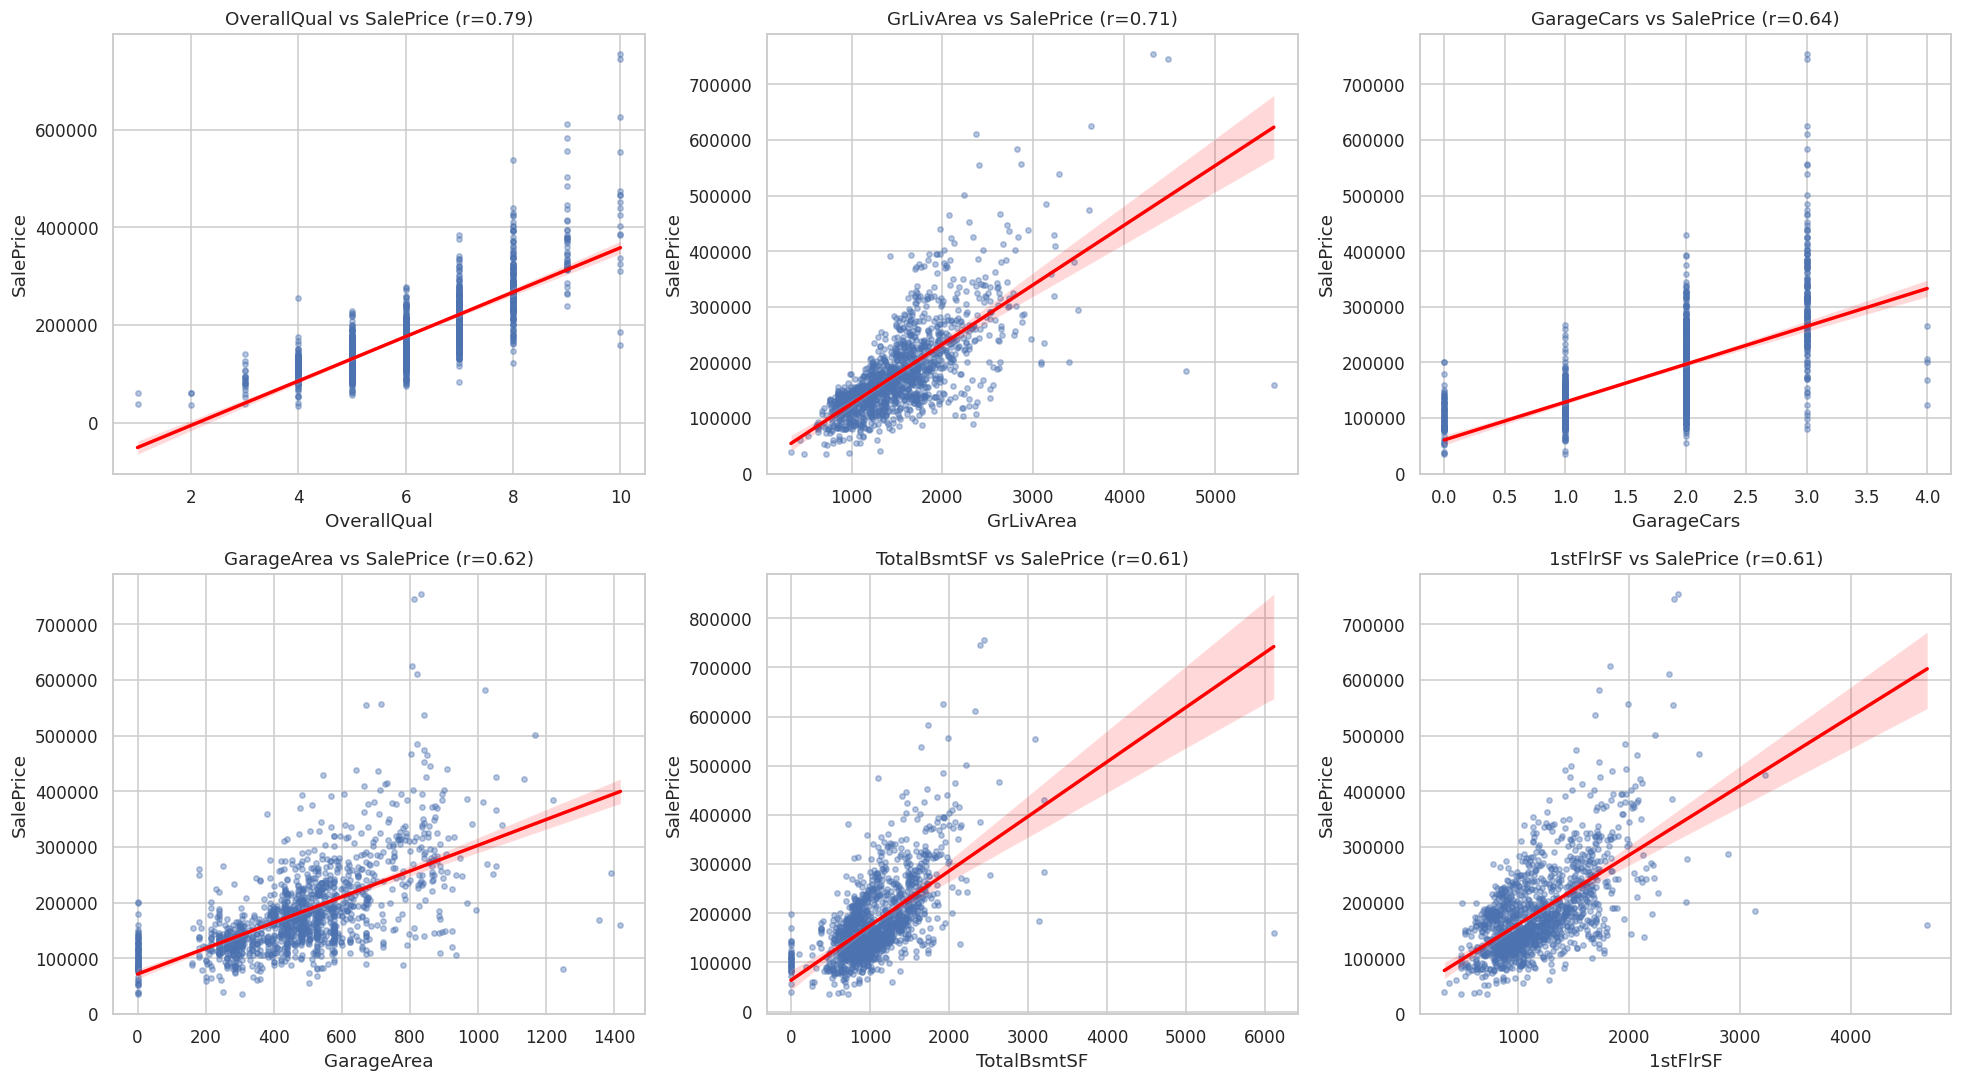

In [9]:
# Dùng các cột số + ordinal số (OverallQual/Cond) + target
corr_cols = numerical_features + ORDINAL_NUMERIC + [TARGET]
corr_cols = [c for c in corr_cols if pd.api.types.is_numeric_dtype(train[c])]
corr = train[corr_cols].corr(numeric_only=True)

# 7a. Heatmap đầy đủ
fig, ax = plt.subplots(figsize=(20, 16))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.2, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Heatmap tương quan - tất cả đặc trưng số", fontsize=16)
save_show(fig, "corr_heatmap_full.png")

# 7b. Top 15 đặc trưng tương quan mạnh nhất với SalePrice
top_n = 15
top_cols = corr[TARGET].abs().sort_values(ascending=False).head(top_n + 1).index
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(train[top_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, ax=ax)
ax.set_title(f"Top {top_n} đặc trưng tương quan với {TARGET}", fontsize=14)
save_show(fig, "corr_heatmap_top.png")

# 7c. Bar chart tương quan với SalePrice
corr_target = corr[TARGET].drop(TARGET).sort_values()
print("\n=== TƯƠNG QUAN VỚI SalePrice (Pearson) ===")
print(corr_target.sort_values(ascending=False).round(3).to_string())
corr_target.sort_values(ascending=False).to_csv(os.path.join(OUT_DIR, "corr_with_target.csv"),
                                               header=["corr"], encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 10))
colors = ["#d62728" if v < 0 else "#1f77b4" for v in corr_target]
ax.barh(corr_target.index, corr_target.values, color=colors)
ax.set_title(f"Tương quan Pearson với {TARGET}")
save_show(fig, "corr_with_target_bar.png")

# 7d. Cặp đặc trưng đa cộng tuyến (|r| > 0.8)
feat_corr = corr.drop(index=TARGET, columns=TARGET)
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
         .stack().reset_index())
pairs.columns = ["Feature_1", "Feature_2", "Corr"]
high_pairs = pairs[pairs["Corr"].abs() > 0.8].sort_values("Corr", key=abs, ascending=False)
print("\n=== CÁC CẶP ĐẶC TRƯNG TƯƠNG QUAN CAO (|r| > 0.8) -> nguy cơ đa cộng tuyến ===")
print(high_pairs.to_string(index=False))

# 7e. Scatter plot các đặc trưng quan trọng nhất vs SalePrice
top_scatter = [c for c in corr[TARGET].abs().sort_values(ascending=False).index if c != TARGET][:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.ravel(), top_scatter):
    sns.regplot(x=train[c], y=train[TARGET], ax=ax,
                scatter_kws={"alpha": 0.4, "s": 12}, line_kws={"color": "red"})
    ax.set_title(f"{c} vs {TARGET} (r={corr.loc[c, TARGET]:.2f})")
save_show(fig, "scatter_top_features.png")

## 1.8 Phân phối đặc trưng và SalePrice theo nhóm


=== SKEWNESS CÁC ĐẶC TRƯNG SỐ LIÊN TỤC (|skew|>0.75 nên cân nhắc biến đổi) ===
MiscVal          24.48
LotArea          12.21
3SsnPorch        10.30
LowQualFinSF      9.01
BsmtFinSF2        4.26
ScreenPorch       4.12
EnclosedPorch     3.09
MasVnrArea        2.67
OpenPorchSF       2.36
LotFrontage       2.16
BsmtFinSF1        1.69
WoodDeckSF        1.54
TotalBsmtSF       1.52
1stFlrSF          1.38
GrLivArea         1.37
BsmtUnfSF         0.92
2ndFlrSF          0.81
GarageArea        0.18
YearRemodAdd     -0.50
YearBuilt        -0.61
GarageYrBlt      -0.65


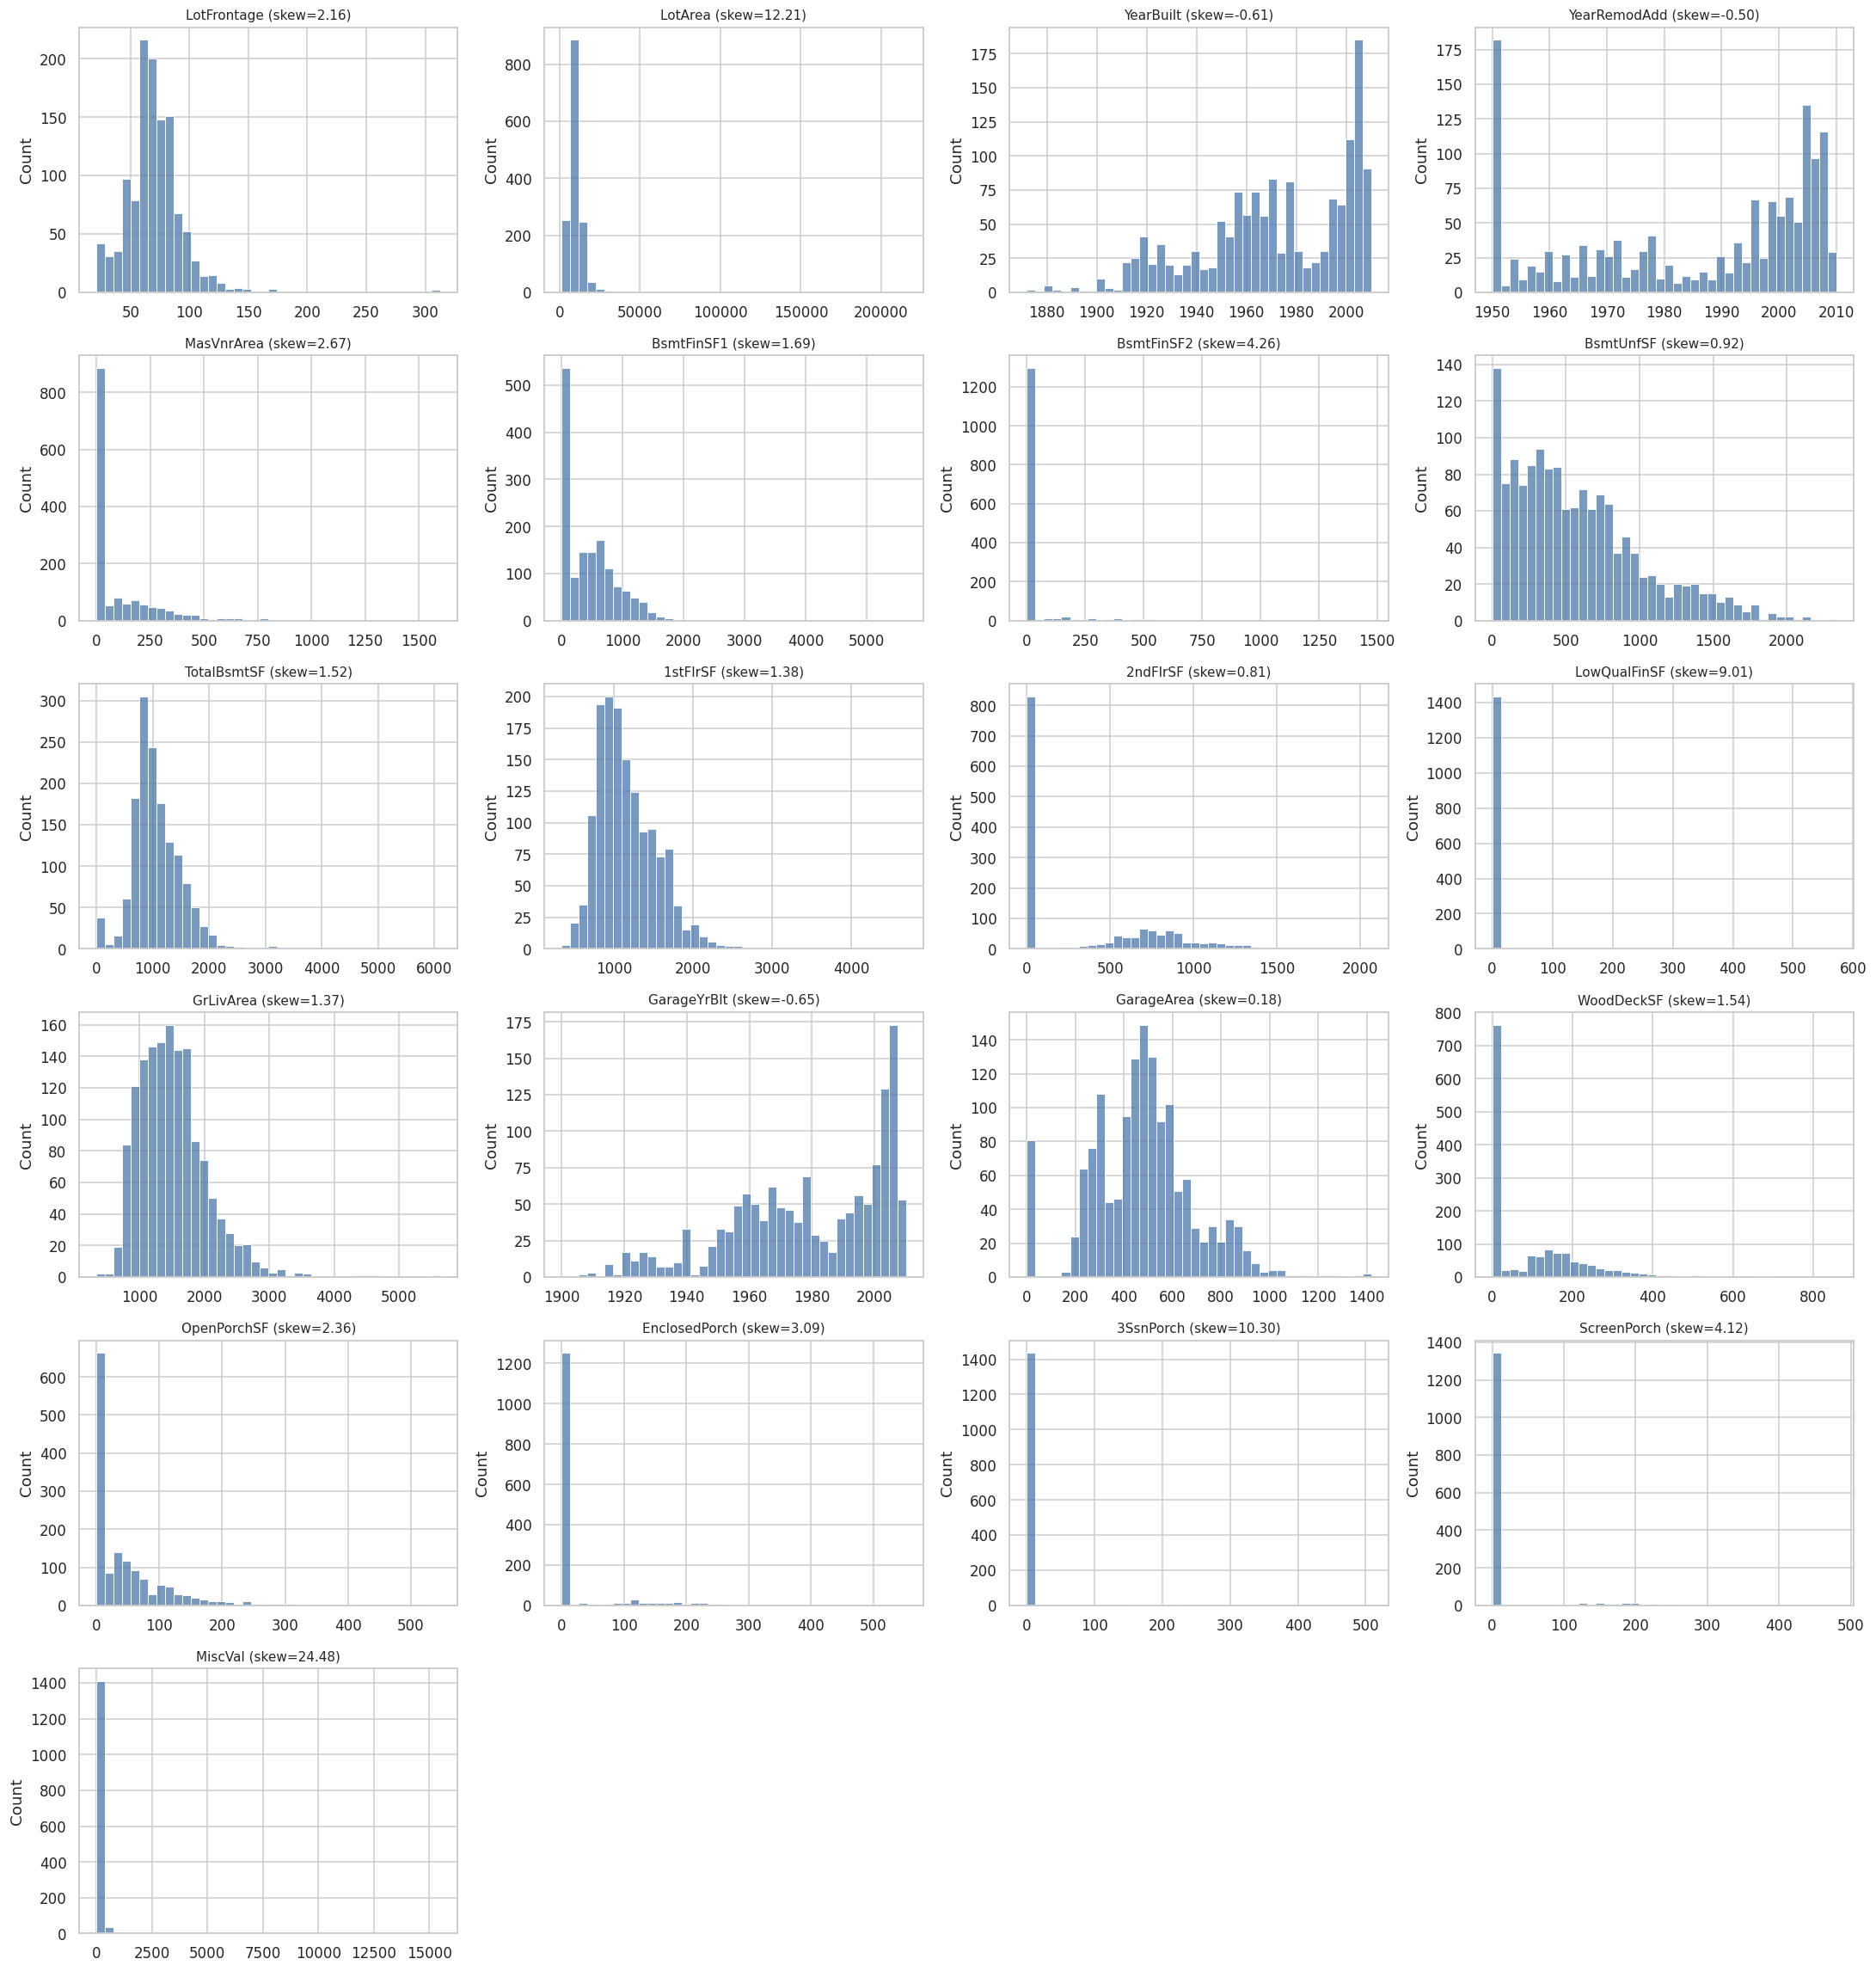

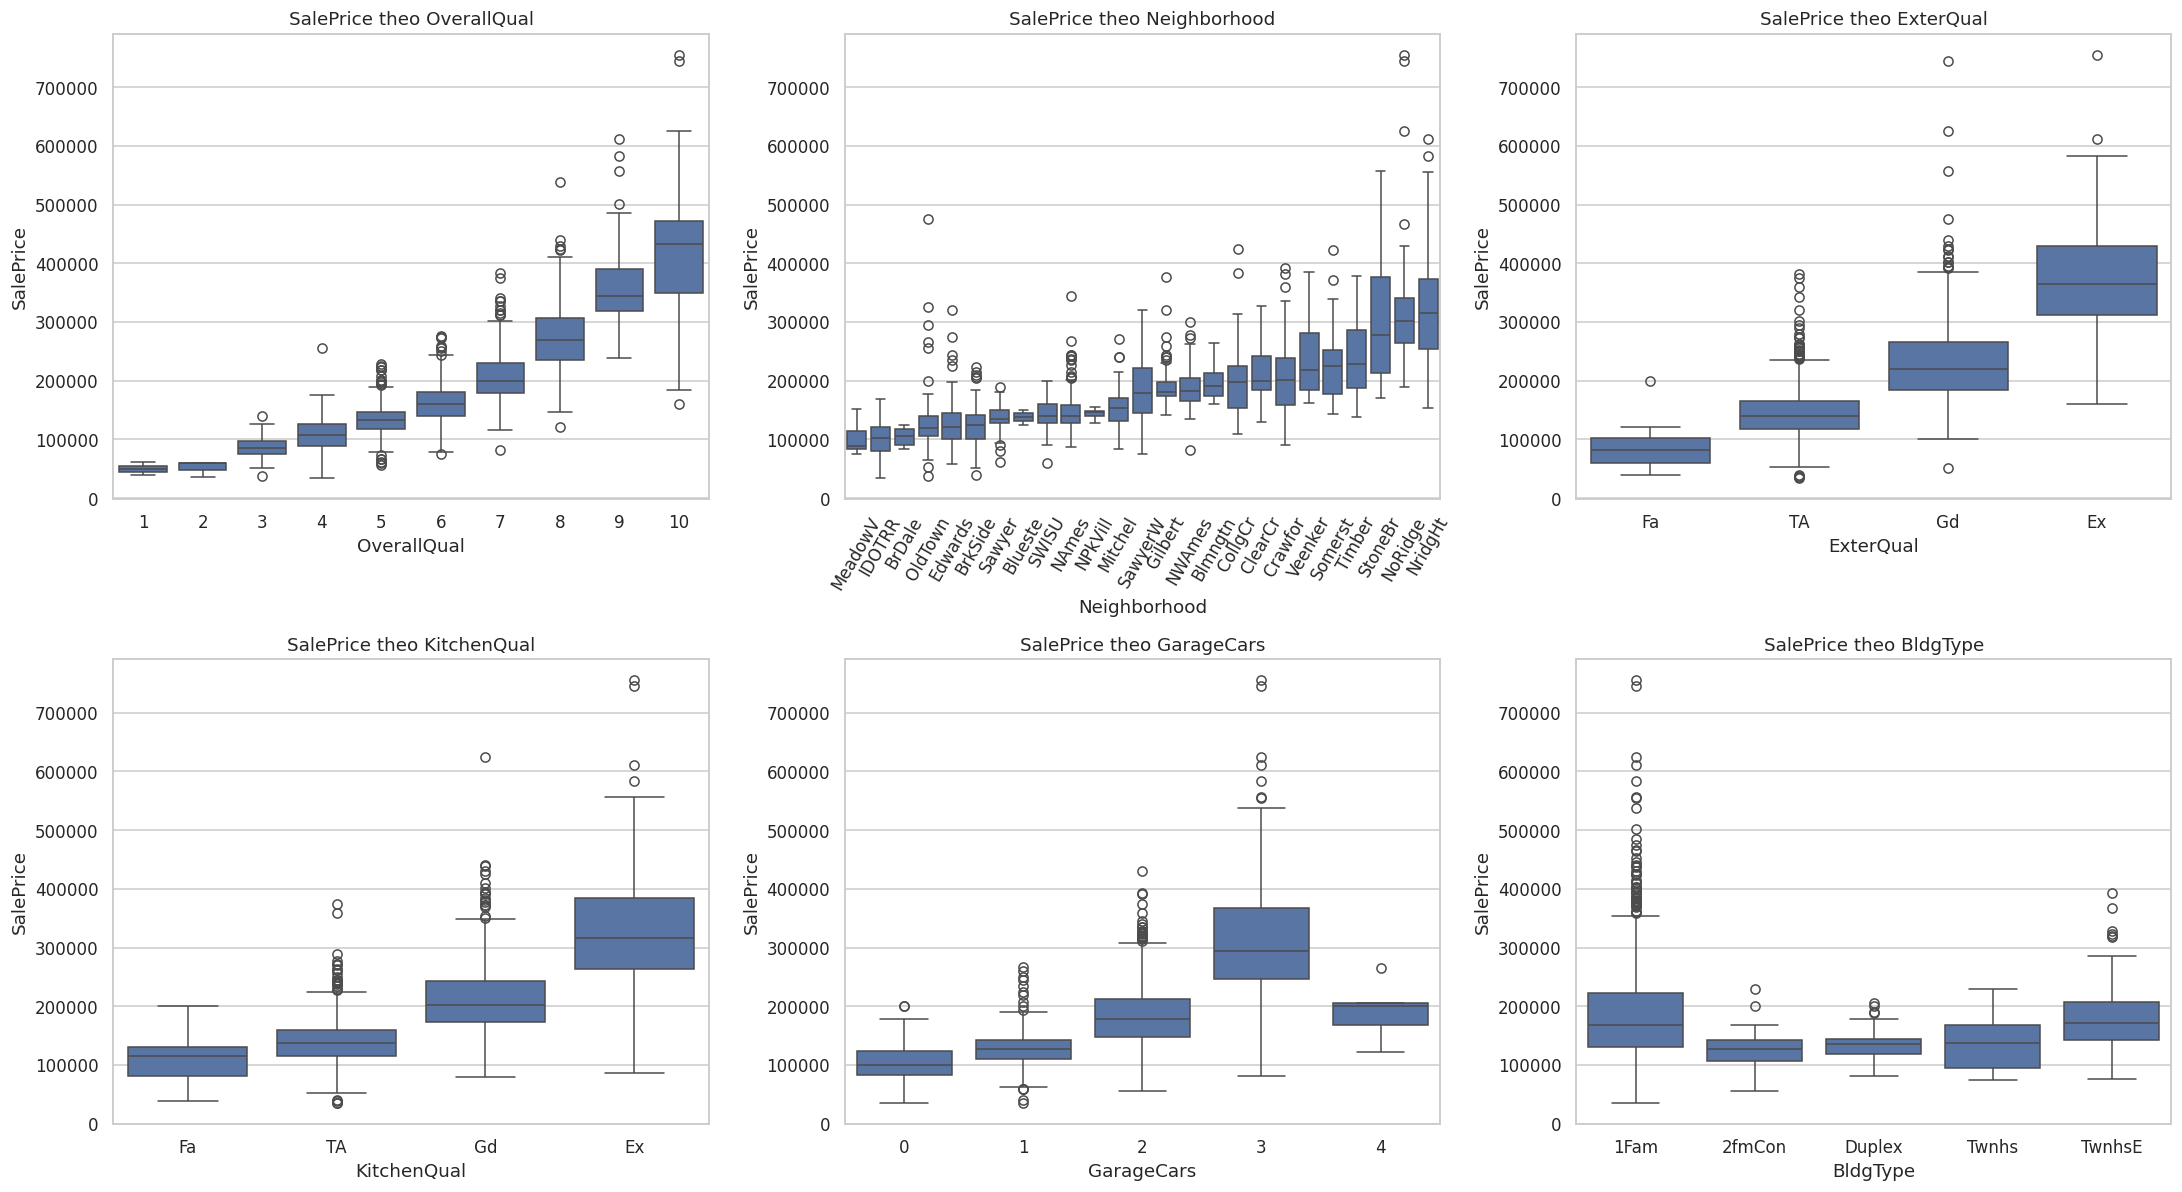

In [10]:
# 8a. Skewness của các đặc trưng số liên tục
skew_df = train[continuous_num].skew().sort_values(ascending=False).round(2)
print("\n=== SKEWNESS CÁC ĐẶC TRƯNG SỐ LIÊN TỤC (|skew|>0.75 nên cân nhắc biến đổi) ===")
print(skew_df.to_string())

# 8b. Histogram các biến số liên tục
n = len(continuous_num)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.5 * nrows))
for ax, c in zip(axes.ravel(), continuous_num):
    sns.histplot(train[c].dropna(), bins=40, ax=ax, color="#4c78a8")
    ax.set_title(f"{c} (skew={train[c].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
for ax in axes.ravel()[n:]:
    ax.axis("off")
save_show(fig, "numeric_histograms.png")

# 8c. Boxplot SalePrice theo các biến phân loại/thứ bậc quan trọng
box_cols = ["OverallQual", "Neighborhood", "ExterQual", "KitchenQual", "GarageCars", "BldgType"]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, c in zip(axes.ravel(), box_cols):
    if c in ORDINAL_ORDERS:
        order = [o for o in ORDINAL_ORDERS[c] if o in train[c].unique()]
    elif c == "Neighborhood":
        order = train.groupby(c)[TARGET].median().sort_values().index
    else:
        order = sorted(train[c].unique())
    sns.boxplot(data=train, x=c, y=TARGET, order=order, ax=ax)
    ax.set_title(f"{TARGET} theo {c}")
    if c == "Neighborhood":
        ax.tick_params(axis="x", rotation=60)
save_show(fig, "saleprice_by_category.png")

## 1.9 So sánh train và test

In [11]:
print("\n=== SO SÁNH PHÂN PHỐI TRAIN vs TEST (một vài cột chính) ===")
for c in ["GrLivArea", "LotArea", "YearBuilt", "OverallQual"]:
    print(f"{c:12s} | train mean={train[c].mean():10.2f} | test mean={test[c].mean():10.2f}")


=== SO SÁNH PHÂN PHỐI TRAIN vs TEST (một vài cột chính) ===
GrLivArea    | train mean=   1515.46 | test mean=   1486.05
LotArea      | train mean=  10516.83 | test mean=   9819.16
YearBuilt    | train mean=   1971.27 | test mean=   1971.36
OverallQual  | train mean=      6.10 | test mean=      6.08


# GIAI ĐOẠN 2 — Tiền xử lý dữ liệu
2.1 Dữ liệu thiếu · 2.2 Outlier · 2.3 Categorical · 2.4 Numerical. Sản phẩm: `train_processed.csv`, `test_processed.csv` (bản đã scale) và bản chỉ encoding, chưa scale (cho mô hình cây), lưu trong `outputs/phase2_preprocessing/`.

## 2.1 Missing Data (dữ liệu thiếu)

### 2.1.1 Import thư viện và đọc dữ liệu

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đọc dữ liệu train gốc
OUT_DIR = BASE_OUT / 'phase2_preprocessing'; OUT_DIR.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(DATA_DIR / 'train.csv')
print(f"Kích thước tập dữ liệu ban đầu: {train.shape}")

Kích thước tập dữ liệu ban đầu: (1460, 81)


### 2.1.2 Phân tích dữ liệu thiếu và Missingness Correlation Heatmap

=== CÁC CỘT BỊ THIẾU DỮ LIỆU ===
              Missing_Count  Missing_Percent (%)
PoolQC                 1453            99.520548
MiscFeature            1406            96.301370
Alley                  1369            93.767123
Fence                  1179            80.753425
MasVnrType              872            59.726027
FireplaceQu             690            47.260274
LotFrontage             259            17.739726
GarageType               81             5.547945
GarageYrBlt              81             5.547945
GarageFinish             81             5.547945
GarageQual               81             5.547945
GarageCond               81             5.547945
BsmtExposure             38             2.602740
BsmtFinType2             38             2.602740
BsmtQual                 37             2.534247
BsmtCond                 37             2.534247
BsmtFinType1             37             2.534247
MasVnrArea                8             0.547945
Electrical                1         

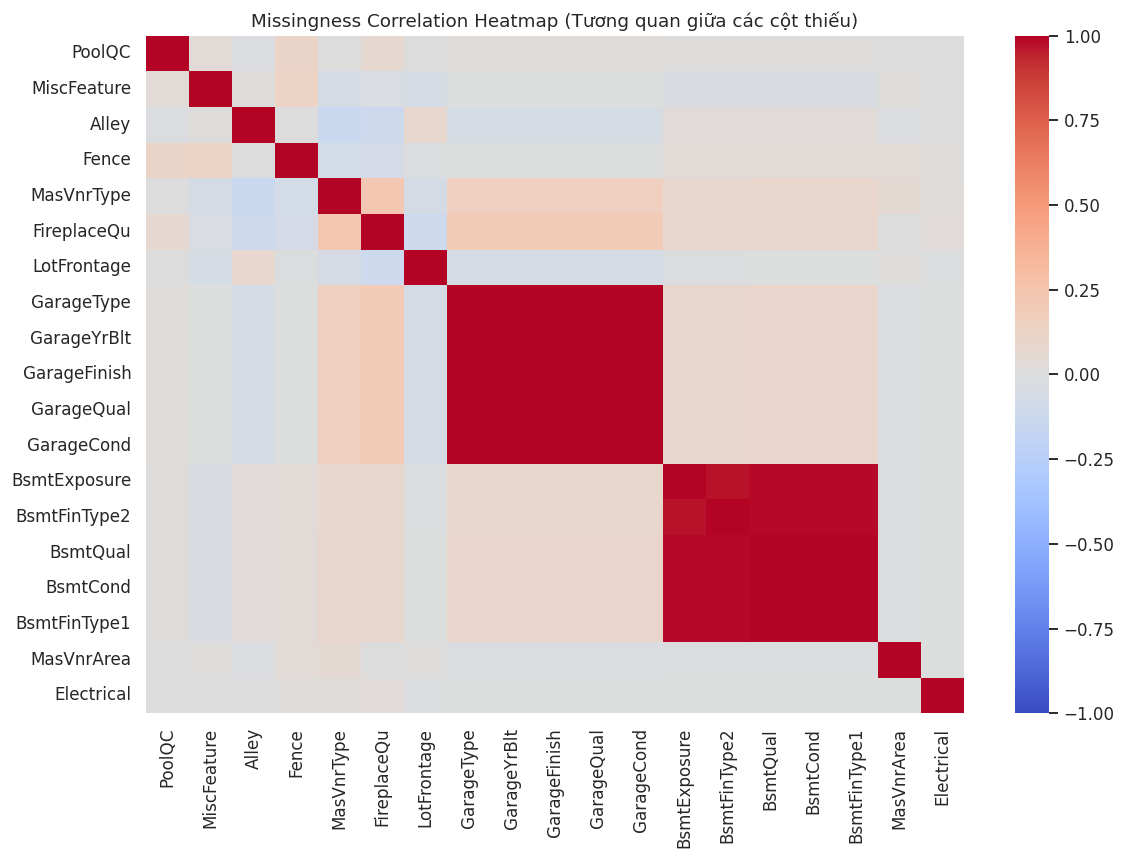

In [13]:
# 1. Tính toán số lượng và tỷ lệ missing values
missing_sum = train.isnull().sum()
missing_percent = (missing_sum / len(train)) * 100

missing_df = pd.DataFrame({
    'Missing_Count': missing_sum,
    'Missing_Percent (%)': missing_percent
}).query('Missing_Count > 0').sort_values(by='Missing_Percent (%)', ascending=False)

print("=== CÁC CỘT BỊ THIẾU DỮ LIỆU ===")
print(missing_df)

# 2. Tạo Missingness Matrix (1: Missing, 0: Not Missing)
missing_cols = missing_df.index.tolist()
missing_matrix = train[missing_cols].isnull().astype(int)

# 3. Vẽ Missingness Correlation Heatmap để chứng minh cơ chế MAR/MNAR
plt.figure(figsize=(12, 8))
sns.heatmap(missing_matrix.corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Missingness Correlation Heatmap (Tương quan giữa các cột thiếu)", fontsize=12)
plt.show()

### 2.1.3 Thực hiện Imputation (phân tích theo nhóm cơ chế thiếu)

In [14]:
train_clean = train.copy()

# ----------------------------------------------------
# NHÓM 1: Constant Imputation ('None' cho Categorical - MNAR)
# Ngôi nhà không có hạng mục/tính năng này
# ----------------------------------------------------
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType'
]
for col in none_cols:
    if col in train_clean.columns:
        train_clean[col] = train_clean[col].fillna('None')

# ----------------------------------------------------
# NHÓM 2: Constant Imputation (0 cho Numerical - MNAR)
# Ngôi nhà không có hạng mục/tính năng này (diện tích/số lượng = 0)
# ----------------------------------------------------
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea'
]
for col in zero_cols:
    if col in train_clean.columns:
        train_clean[col] = train_clean[col].fillna(0)

# ----------------------------------------------------
# NHÓM 3: Group-based Imputation (Median LotFrontage theo Neighborhood)
# Tỷ lệ mặt tiền nhà phụ thuộc vào quy hoạch của từng khu vực
# ----------------------------------------------------
if 'LotFrontage' in train_clean.columns:
    train_clean['LotFrontage'] = train_clean.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

# ----------------------------------------------------
# NHÓM 4: Mode Imputation (Giá trị xuất hiện nhiều nhất cho biến hạ tầng/dịch vụ)
# ----------------------------------------------------
mode_cols = ['MSZoning', 'Utilities', 'Exterior1st', 'Exterior2nd', 'Electrical', 'KitchenQual', 'Functional', 'SaleType']
for col in mode_cols:
    if col in train_clean.columns:
        train_clean[col] = train_clean[col].fillna(train_clean[col].mode()[0])

### 2.1.4 Kiểm tra lại kết quả và xuất file

In [15]:
# 1. Kiểm tra xem còn vị trí nào bị thiếu hay không
remaining_missing = train_clean.isnull().sum().sum()
print(f"---> Tổng số giá trị missing còn lại sau xử lý: {remaining_missing}")


train_clean.to_csv(OUT_DIR / 'train_no_missing.csv', index=False)
print("---> Đã xuất thành công file 'train_no_missing.csv'!")

---> Tổng số giá trị missing còn lại sau xử lý: 0
---> Đã xuất thành công file 'train_no_missing.csv'!


## Tiền xử lý dữ liệu House Prices (Ames Housing)
**Nội dung:** 2.2 Outlier Detection · 2.3 Categorical Data · 2.4 Numerical Data  
**Sản phẩm:** dataset đã tiền xử lý (`train_processed.csv`, `test_processed.csv`) sẵn sàng đưa vào mô hình.

Nguyên tắc xuyên suốt: **mọi tham số (ngưỡng cắt outlier, bộ mã hóa, scaler) chỉ được học (fit) trên tập train**, sau đó áp dụng (transform) cho tập test để tránh rò rỉ dữ liệu.

In [16]:
import json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import RepeatedKFold, KFold, cross_val_score
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

OUT_DIR = BASE_OUT / 'phase2_preprocessing'; FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'SalePrice'
R = {}   # lưu kết quả chính để dùng cho báo cáo Word

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=130, bbox_inches='tight'); plt.show()

### 2.1.5 Imputation theo nguyên tắc fit-on-train (đầu vào cho 2.2–2.4)
Outlier, encoding và scaling đều không chạy được khi còn `NaN`, nên bước này xử lý tối thiểu:
- Với các cột mà `NaN` nghĩa là **"không có"** (không có hầm, gara, hồ bơi, hàng rào...) → điền `"None"`.
- `LotFrontage` → median theo `Neighborhood`; `GarageYrBlt` → `YearBuilt`; các cột diện tích/số lượng của hầm/gara → 0.
- Còn lại → median (số) / mode (chữ) **của tập train**.

In [17]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
print('train:', train.shape, '| test:', test.shape)
R['shape_raw'] = {'train': list(train.shape), 'test': list(test.shape)}
R['missing_raw'] = int(train.isna().sum().sum()), int(test.isna().sum().sum())

none_cols = ['Alley','MasVnrType','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2',
             'FireplaceQu','GarageType','GarageFinish','GarageQual','GarageCond','PoolQC','Fence','MiscFeature']
zero_cols = ['MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath',
             'GarageCars','GarageArea']

lot_med = train.groupby('Neighborhood')['LotFrontage'].median()
def fill_missing(df, ref):
    df = df.copy()
    for c in none_cols: df[c] = df[c].fillna('None')
    for c in zero_cols: df[c] = df[c].fillna(0)
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lot_med)).fillna(ref['LotFrontage'].median())
    # GarageYrBlt: thiếu hoặc sai (vd. năm 2207 trong test) -> lấy YearBuilt
    bad = df['GarageYrBlt'].isna() | (df['GarageYrBlt'] > 2010)
    df.loc[bad, 'GarageYrBlt'] = df.loc[bad, 'YearBuilt']
    for c in df.columns:
        if c == TARGET or df[c].notna().all(): continue
        df[c] = df[c].fillna(ref[c].median() if pd.api.types.is_numeric_dtype(ref[c]) else ref[c].mode()[0])
    return df

train = fill_missing(train, train); test = fill_missing(test, train)
print('Còn NaN -> train:', train.drop(columns=TARGET).isna().sum().sum(), '| test:', test.isna().sum().sum())

train: (1460, 81) | test: (1459, 80)
Còn NaN -> train: 0 | test: 0


---
## 2.2 Outlier Detection
### 2.2.1 Chọn nhóm biến để kiểm tra
Chỉ kiểm tra outlier trên **biến liên tục** (diện tích, độ dài). Không áp dụng cho:
- biến định danh mã số (`MSSubClass`), biến thứ hạng 1–10 (`OverallQual`, `OverallCond`), biến đếm nhỏ, biến năm;
- `Id` và `SalePrice` (SalePrice được phân tích riêng như biến mục tiêu).

In [18]:
cont_cols = ['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF',
             '1stFlrSF','2ndFlrSF','LowQualFinSF','GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF',
             'EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal']
print(len(cont_cols), 'biến liên tục được kiểm tra')

19 biến liên tục được kiểm tra


### 2.2.2 Phương pháp IQR và Z-score
- **IQR:** `Q1 − 1.5·IQR` đến `Q3 + 1.5·IQR`; điểm nằm ngoài là outlier.
- **Z-score:** `z = (x − mean)/std`; điểm có `|z| > 3` là outlier.

Hai lưu ý quan trọng: (1) với biến có >75% giá trị bằng 0 (hiên, hồ bơi, MiscVal...) thì `IQR = 0`, mọi giá trị khác 0 đều bị gắn nhãn outlier — đó là *"zero-inflated"* chứ không phải lỗi; (2) Z-score dùng mean/std vốn đã bị outlier kéo lệch nên có thể bỏ sót.

In [19]:
rows = []
for c in cont_cols:
    x = train[c]; q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (x - x.mean()) / x.std()
    rows.append(dict(feature=c, Q1=q1, Q3=q3, IQR=iqr, lower=lo, upper=hi,
                     n_IQR=int(((x < lo) | (x > hi)).sum()), n_Z=int((z.abs() > 3).sum()),
                     zero_ratio=round((x == 0).mean(), 3), skew=round(x.skew(), 2)))
out_tab = pd.DataFrame(rows).set_index('feature')
out_tab['pct_IQR'] = (out_tab.n_IQR / len(train) * 100).round(2)
out_tab['pct_Z'] = (out_tab.n_Z / len(train) * 100).round(2)
R['outlier_table'] = out_tab.reset_index().to_dict('records')
out_tab[['Q1','Q3','IQR','lower','upper','n_IQR','pct_IQR','n_Z','pct_Z','zero_ratio','skew']]

,Q1,Q3,IQR,lower,upper,n_IQR,pct_IQR,n_Z,pct_Z,zero_ratio,skew
feature,,,,,,,,,,,
LotFrontage,60.00,80.00,20.00,30.000,110.000,93,6.37,15,1.03,0.000,2.21
LotArea,7553.50,11601.50,4048.00,1481.500,17673.500,69,4.73,13,0.89,0.000,12.21
MasVnrArea,0.00,164.25,164.25,-246.375,410.625,98,6.71,32,2.19,0.595,2.68
BsmtFinSF1,0.00,712.25,712.25,-1068.375,1780.625,7,0.48,6,0.41,0.320,1.69
BsmtFinSF2,0.00,0.00,0.00,0.000,0.000,167,11.44,50,3.42,0.886,4.26
BsmtUnfSF,223.00,808.00,585.00,-654.500,1685.500,29,1.99,11,0.75,0.081,0.92
TotalBsmtSF,795.75,1298.25,502.50,42.000,2052.000,61,4.18,10,0.68,0.025,1.52
1stFlrSF,882.00,1391.25,509.25,118.125,2155.125,20,1.37,12,0.82,0.000,1.38
2ndFlrSF,0.00,728.00,728.00,-1092.000,1820.000,2,0.14,4,0.27,0.568,0.81


Biến lõi: ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF']
Zero-inflated (IQR = 0): ['BsmtFinSF2', 'LowQualFinSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


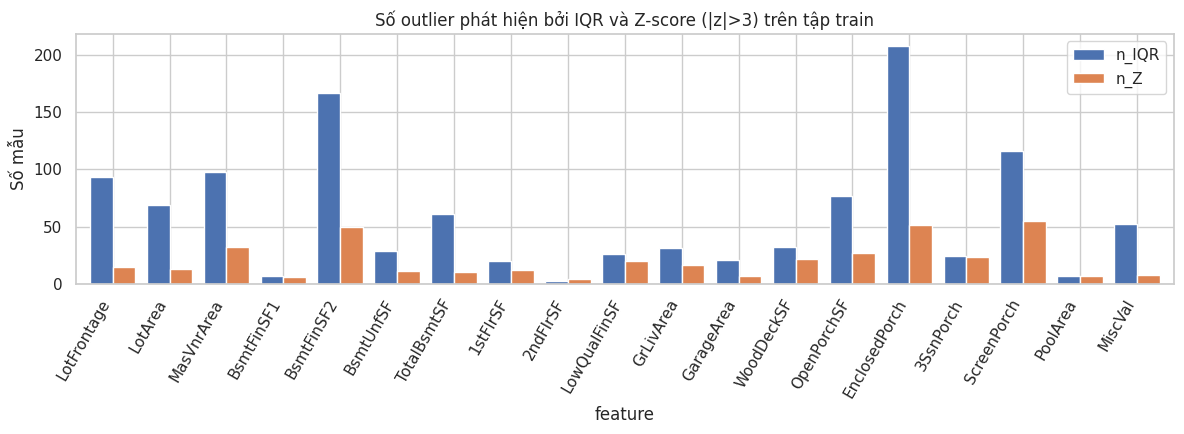

In [20]:
# Biến "lõi": IQR > 0 -> IQR/Z-score có ý nghĩa; biến zero-inflated (IQR = 0) xử lý riêng
core_cols = out_tab.index[out_tab.IQR > 0].tolist()
zero_infl = out_tab.index[out_tab.IQR == 0].tolist()
print('Biến lõi:', core_cols)
print('Zero-inflated (IQR = 0):', zero_infl)
R['core_cols'], R['zero_infl'] = core_cols, zero_infl

ax = out_tab[['n_IQR', 'n_Z']].plot(kind='bar', figsize=(12, 4.5), width=.8)
ax.set_title('Số outlier phát hiện bởi IQR và Z-score (|z|>3) trên tập train'); ax.set_ylabel('Số mẫu')
plt.xticks(rotation=60, ha='right'); savefig('fig01_iqr_vs_zscore.png')

### 2.2.3 Boxplot

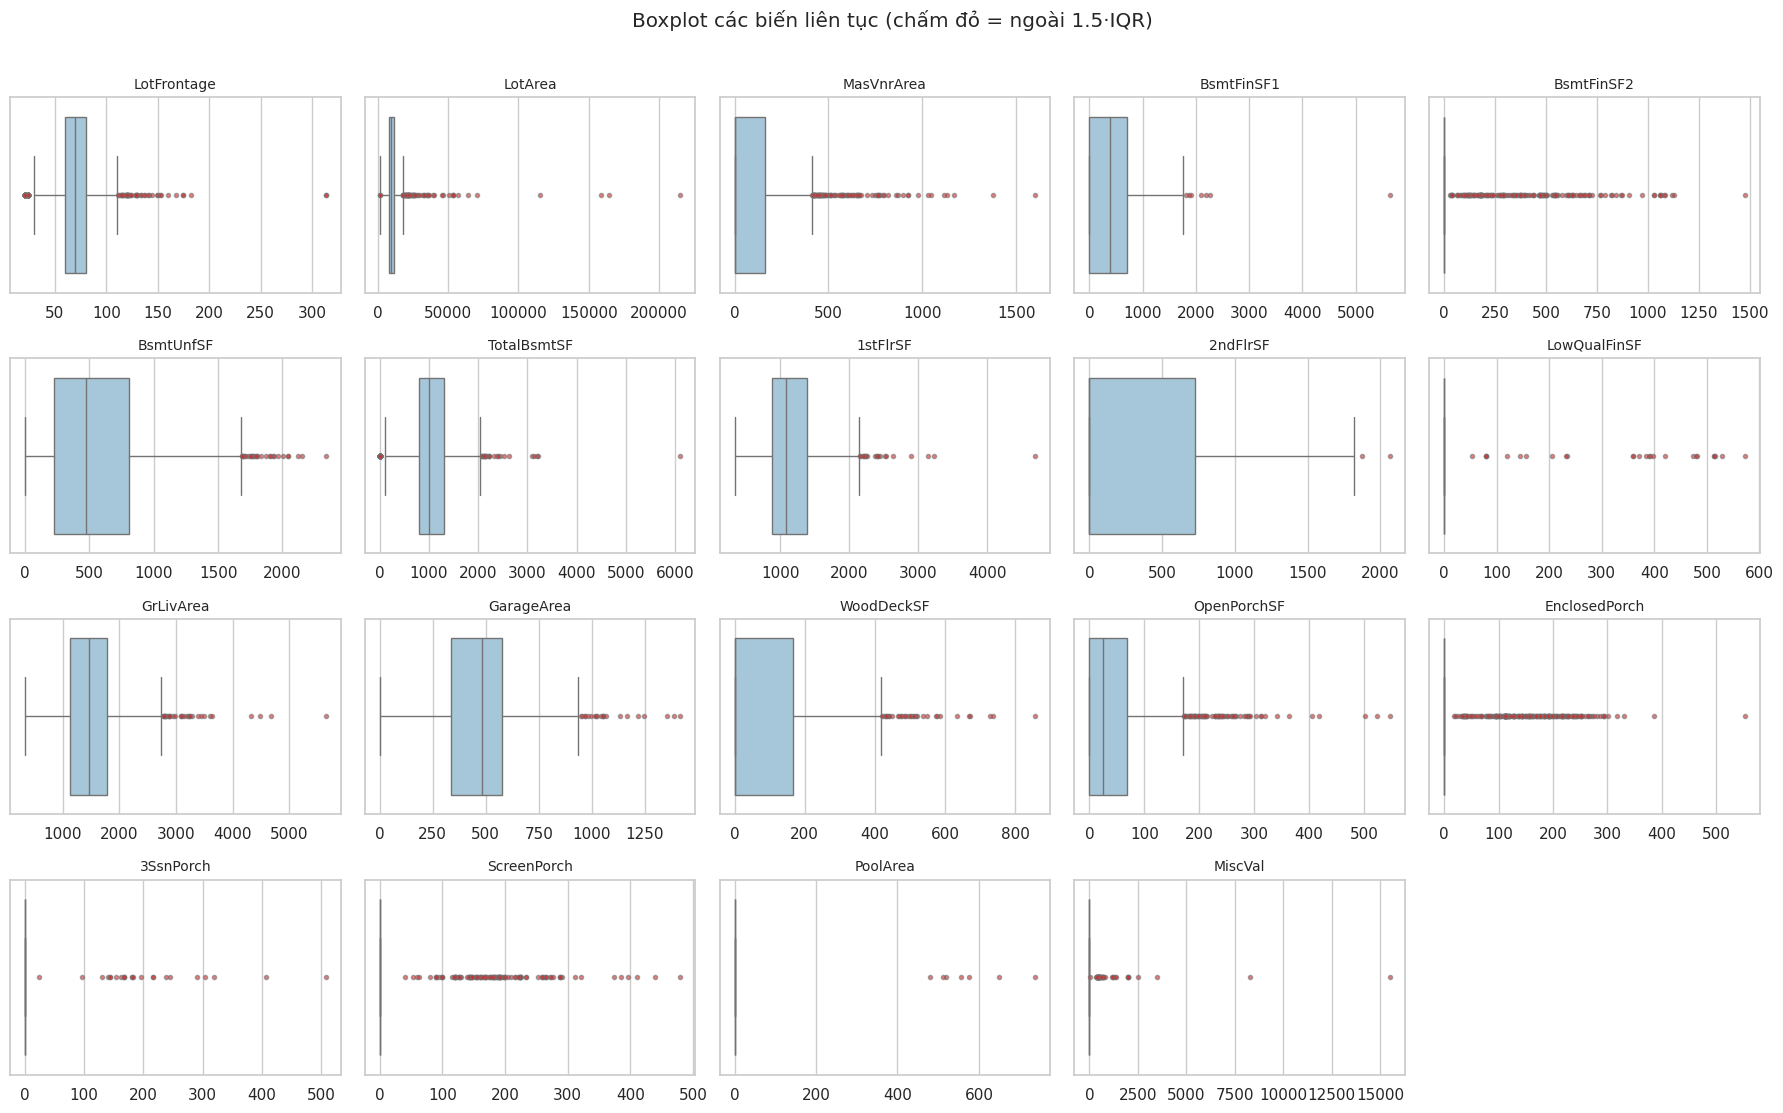

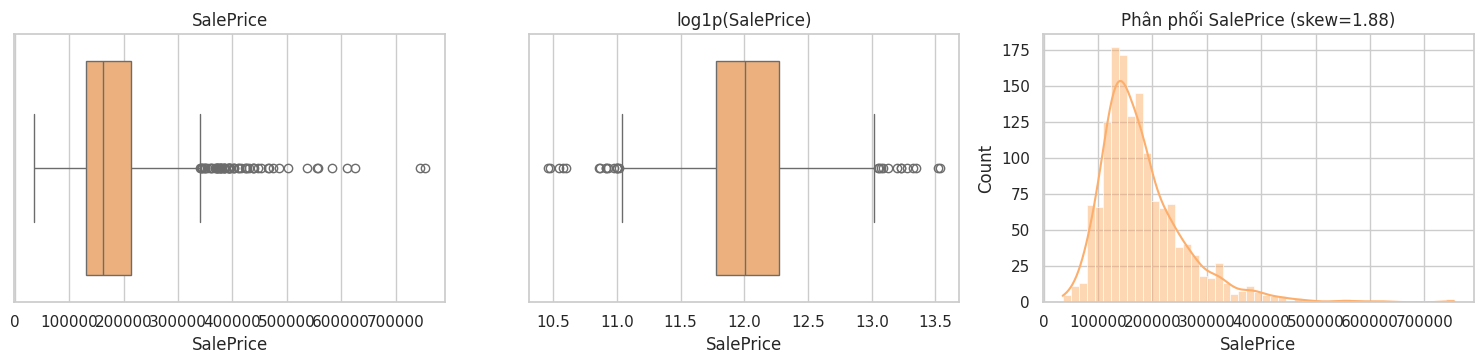

In [21]:
fig, axes = plt.subplots(4, 5, figsize=(18, 11))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(x=train[c], ax=ax, color='#9ecae1', flierprops=dict(marker='o', markersize=3, markerfacecolor='#d62728', alpha=.6))
    ax.set_title(c, fontsize=10); ax.set_xlabel('')
for ax in axes.ravel()[len(cont_cols):]: ax.axis('off')
plt.suptitle('Boxplot các biến liên tục (chấm đỏ = ngoài 1.5·IQR)', y=1.01); savefig('fig02_boxplots_features.png')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=train[TARGET], ax=axes[0], color='#fdae6b'); axes[0].set_title('SalePrice')
sns.boxplot(x=np.log1p(train[TARGET]), ax=axes[1], color='#fdae6b'); axes[1].set_title('log1p(SalePrice)')
sns.histplot(train[TARGET], kde=True, ax=axes[2], color='#fdae6b'); axes[2].set_title(f'Phân phối SalePrice (skew={train[TARGET].skew():.2f})')
savefig('fig03_boxplot_saleprice.png')

### 2.2.4 Xác định những mẫu bất thường
Mỗi mẫu được đếm số biến lõi bị gắn cờ theo IQR và theo Z-score; mẫu bị gắn cờ ở nhiều biến cùng lúc, hoặc có kết hợp (diện tích, giá) phi logic, là ứng viên bất thường.

In [22]:
iqr_flag = pd.DataFrame({c: (train[c] < out_tab.loc[c,'lower']) | (train[c] > out_tab.loc[c,'upper']) for c in core_cols})
z_flag = pd.DataFrame({c: ((train[c] - train[c].mean()) / train[c].std()).abs() > 3 for c in core_cols})
flags = train[['Id','GrLivArea','TotalBsmtSF','LotArea','GarageArea','SalePrice','SaleCondition']].copy()
flags['n_flag_IQR'] = iqr_flag.sum(axis=1); flags['n_flag_Z'] = z_flag.sum(axis=1)

print('Số mẫu có ít nhất 1 cờ IQR :', (flags.n_flag_IQR >= 1).sum())
print('Số mẫu có ít nhất 1 cờ Z   :', (flags.n_flag_Z >= 1).sum())
print('Số mẫu có >= 3 cờ Z        :', (flags.n_flag_Z >= 3).sum())
R['n_rows_any_iqr'] = int((flags.n_flag_IQR >= 1).sum()); R['n_rows_any_z'] = int((flags.n_flag_Z >= 1).sum())
top = flags.sort_values(['n_flag_Z','n_flag_IQR'], ascending=False).head(10)
R['top_anomalies'] = top.to_dict('records')
top

Số mẫu có ít nhất 1 cờ IQR : 377
Số mẫu có ít nhất 1 cờ Z   : 116
Số mẫu có >= 3 cờ Z        : 13


,Id,GrLivArea,TotalBsmtSF,LotArea,GarageArea,SalePrice,SaleCondition,n_flag_IQR,n_flag_Z
1298,1299,5642,6110,63887,1418,160000,Partial,9,9
523,524,4676,3138,40094,884,184750,Partial,8,6
1182,1183,4476,2396,15623,813,745000,Abnorml,6,6
691,692,4316,2444,21535,832,755000,Normal,6,5
224,225,2392,2392,13472,968,386250,Normal,5,4
496,497,3228,3200,12692,546,430000,Normal,4,4
178,179,2234,2216,17423,1166,501837,Partial,5,3
769,770,3279,1650,53504,841,538000,Normal,4,3
898,899,2364,2330,12919,820,611657,Partial,4,3
1169,1170,3627,1930,35760,807,625000,Normal,4,3


In [23]:
# Phân tích đa biến: diện tích sinh hoạt lớn bất thường so với giá
big = train.loc[train.GrLivArea > 4000, ['Id','GrLivArea','TotalBsmtSF','LotArea','OverallQual','SaleCondition','SalePrice']]
print(big.to_string(index=False))
anom_mask = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
print('\nMẫu bất thường thực sự (GrLivArea>4000 & SalePrice<300k): Id =', train.loc[anom_mask, 'Id'].tolist())
R['anom_ids'] = train.loc[anom_mask, 'Id'].tolist()
R['big_table'] = big.to_dict('records')

  Id  GrLivArea  TotalBsmtSF  LotArea  OverallQual SaleCondition  SalePrice
 524       4676         3138    40094           10       Partial     184750
 692       4316         2444    21535           10        Normal     755000
1183       4476         2396    15623           10       Abnorml     745000
1299       5642         6110    63887           10       Partial     160000

Mẫu bất thường thực sự (GrLivArea>4000 & SalePrice<300k): Id = [524, 1299]


**Nhận xét:** 4 căn có `GrLivArea > 4000`. Hai căn Id 692 và 1183 có `OverallQual` rất cao và giá ~750k → *cực đoan nhưng hợp lý* (nhà cao cấp). Hai căn Id 524 và 1299 diện tích 4676 và 5642 ft² nhưng chỉ bán 185k và 160k, đều thuộc `SaleCondition = Partial` (bán khi chưa hoàn thiện) → giá không phản ánh đúng diện tích, đây là **mẫu bất thường thực sự**. Tài liệu mô tả bộ dữ liệu Ames cũng khuyến nghị loại các căn này.

### 2.2.5 Đánh giá ảnh hưởng của outlier đến SalePrice
Bốn góc nhìn: (a) thay đổi hệ số tương quan khi bỏ outlier; (b) giá của nhóm outlier so với nhóm thường; (c) độ dốc/R² của hồi quy đơn biến; (d) thí nghiệm mô hình với các chiến lược xử lý khác nhau.

In [24]:
# (a) Tương quan Pearson với SalePrice: toàn bộ dữ liệu vs bỏ outlier IQR của chính biến đó
rows = []
for c in core_cols:
    m = ~iqr_flag[c]
    rows.append(dict(feature=c, corr_all=train[c].corr(train[TARGET]), corr_wo_outlier=train.loc[m, c].corr(train.loc[m, TARGET]), n_removed=int((~m).sum())))
corr_tab = pd.DataFrame(rows).set_index('feature')
corr_tab['delta'] = corr_tab.corr_wo_outlier - corr_tab.corr_all
R['corr_table'] = corr_tab.round(4).reset_index().to_dict('records')
corr_tab.round(3)

,corr_all,corr_wo_outlier,n_removed,delta
feature,,,,
LotFrontage,0.350,0.369,93,0.019
LotArea,0.264,0.430,69,0.167
MasVnrArea,0.473,0.346,98,-0.127
BsmtFinSF1,0.386,0.381,7,-0.006
BsmtUnfSF,0.214,0.135,29,-0.080
TotalBsmtSF,0.614,0.614,61,0.001
1stFlrSF,0.606,0.609,20,0.004
2ndFlrSF,0.319,0.296,2,-0.023
GrLivArea,0.709,0.696,31,-0.012


In [25]:
# (b) Giá của nhóm có outlier và nhóm bình thường
grp = np.where(flags.n_flag_Z >= 1, 'Có outlier (Z>3)', 'Bình thường')
cmp_price = train.groupby(grp)[TARGET].agg(['count','mean','median','std']).round(0)
R['price_by_group'] = cmp_price.reset_index().rename(columns={'index':'group'}).to_dict('records')
print(cmp_price)
print('\nOutlier của chính SalePrice (IQR):', int(((train[TARGET] > train[TARGET].quantile(.75) + 1.5*stats.iqr(train[TARGET]))).sum()), 'mẫu giá cao')

                  count      mean    median       std
Bình thường        1344  172149.0  158000.0   66164.0
Có outlier (Z>3)    116  282556.0  258500.0  132764.0

Outlier của chính SalePrice (IQR): 61 mẫu giá cao


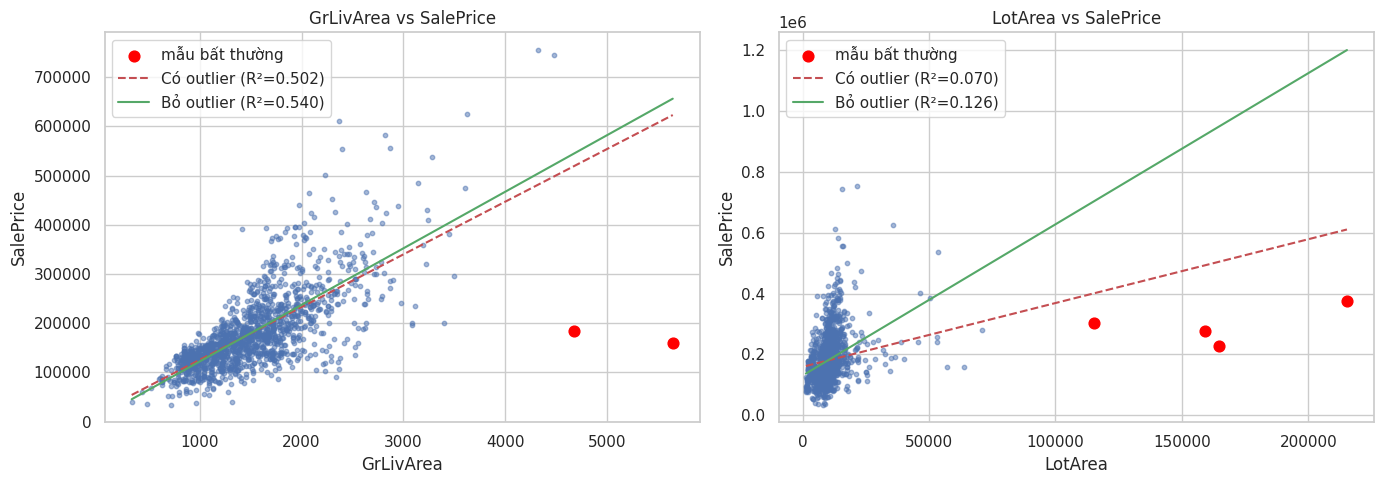

,slope_all,r2_all,slope_clean,r2_clean,n_out
GrLivArea,107.1304,0.5021,115.0400,0.5402,2.0
LotArea,2.1000,0.0696,4.9749,0.1257,4.0


In [26]:
# (c) Hồi quy đơn biến GrLivArea -> SalePrice và LotArea -> SalePrice
def fit_line(df, x):
    lr = LinearRegression().fit(df[[x]], df[TARGET]); return lr, lr.score(df[[x]], df[TARGET])

res = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, mask_out, title) in zip(axes, [('GrLivArea', anom_mask, 'GrLivArea'), ('LotArea', train.LotArea > 100000, 'LotArea')]):
    all_lr, all_r2 = fit_line(train, x)
    cl_lr, cl_r2 = fit_line(train[~mask_out], x)
    res[x] = dict(slope_all=all_lr.coef_[0], r2_all=all_r2, slope_clean=cl_lr.coef_[0], r2_clean=cl_r2, n_out=int(mask_out.sum()))
    ax.scatter(train.loc[~mask_out, x], train.loc[~mask_out, TARGET], s=10, alpha=.5)
    ax.scatter(train.loc[mask_out, x], train.loc[mask_out, TARGET], s=60, c='red', label='mẫu bất thường')
    xs = np.linspace(train[x].min(), train[x].max(), 100)
    ax.plot(xs, all_lr.predict(pd.DataFrame({x: xs})), 'r--', label=f'Có outlier (R²={all_r2:.3f})')
    ax.plot(xs, cl_lr.predict(pd.DataFrame({x: xs})), 'g-', label=f'Bỏ outlier (R²={cl_r2:.3f})')
    ax.set_title(f'{title} vs SalePrice'); ax.set_xlabel(x); ax.set_ylabel(TARGET); ax.legend()
savefig('fig04_impact_scatter.png')
R['regression_impact'] = res
pd.DataFrame(res).T.round(4)

In [27]:
# (d) Thí nghiệm mô hình: Ridge trên biến số (đã chuẩn hóa), mục tiêu log1p(SalePrice), CV 5 fold x 3 lần
num_all = [c for c in train.select_dtypes('number').columns if c not in ['Id', TARGET]]
y = np.log1p(train[TARGET])

def fit_caps(df, cols, k=3.0):
    q1, q3 = df[cols].quantile(.25), df[cols].quantile(.75); i = q3 - q1
    return q1 - k*i, q3 + k*i

def run_strategy(name):
    r_all, r_clean = [], []
    for tr_i, va_i in RepeatedKFold(n_splits=5, n_repeats=3, random_state=42).split(train):
        Xtr, ytr = train.iloc[tr_i][num_all].copy(), y.iloc[tr_i]
        Xva, yva = train.iloc[va_i][num_all].copy(), y.iloc[va_i]
        if name in ('B', 'C'):
            keep = ~anom_mask.iloc[tr_i].values; Xtr, ytr = Xtr[keep], ytr[keep]
        if name == 'C':
            lo, hi = fit_caps(Xtr, core_cols)
            Xtr[core_cols] = Xtr[core_cols].clip(lower=lo, upper=hi, axis=1)
            Xva[core_cols] = Xva[core_cols].clip(lower=lo, upper=hi, axis=1)
        if name == 'D':   # xóa mọi dòng có |z|>3 ở bất kỳ biến lõi nào
            z = ((Xtr[core_cols] - Xtr[core_cols].mean()) / Xtr[core_cols].std()).abs() > 3
            keep = ~z.any(axis=1).values; Xtr, ytr = Xtr[keep], ytr[keep]
        sc = StandardScaler().fit(Xtr); mdl = Ridge(alpha=10).fit(sc.transform(Xtr), ytr)
        pred = mdl.predict(sc.transform(Xva))
        r_all.append(np.sqrt(np.mean((pred - yva) ** 2)))
        ok = ~anom_mask.iloc[va_i].values
        r_clean.append(np.sqrt(np.mean((pred[ok] - yva.values[ok]) ** 2)))
    return np.mean(r_all), np.mean(r_clean)

names = {'A': 'A. Giữ nguyên', 'B': 'B. Xóa 2 mẫu bất thường', 'C': 'C. B + cắt ngưỡng (winsorize 3·IQR)', 'D': 'D. Xóa mọi dòng có |z|>3'}
exp = pd.DataFrame({names[k]: run_strategy(k) for k in names}, index=['RMSE(log) - mọi mẫu validation', 'RMSE(log) - bỏ 2 mẫu bất thường']).T.round(4)
# số dòng bị xóa bởi D (trên toàn train)
zD = ((train[core_cols] - train[core_cols].mean()) / train[core_cols].std()).abs() > 3
R['rows_removed_D'] = int(zD.any(axis=1).sum())
R['strategy_table'] = exp.reset_index().rename(columns={'index': 'strategy'}).to_dict('records')
print('Chiến lược D sẽ xóa', R['rows_removed_D'], 'dòng /', len(train))
exp

Chiến lược D sẽ xóa 116 dòng / 1460


,RMSE(log) - mọi mẫu validation,RMSE(log) - bỏ 2 mẫu bất thường
A. Giữ nguyên,0.1584,0.1376
B. Xóa 2 mẫu bất thường,0.1531,0.1291
C. B + cắt ngưỡng (winsorize 3·IQR),0.1407,0.1276
D. Xóa mọi dòng có |z|>3,0.1591,0.1326


### 2.2.6 Lựa chọn phương pháp xử lý và lý do
| Nhóm | Xử lý | Lý do |
|---|---|---|
| 2 mẫu Id 524, 1299 (diện tích cực lớn nhưng giá thấp, `Partial`) | **Xóa khỏi train** | Làm lệch đường hồi quy (xem hình 4), là mẫu có quan hệ diện tích–giá không đại diện cho thị trường. Chỉ 2/1460 mẫu nên mất mát thông tin không đáng kể. |
| Giá trị cực đoan còn lại ở các biến lõi (IQR > 0) | **Winsorize (cắt ngưỡng) ở `Q1 − 3·IQR` / `Q3 + 3·IQR`**, ngưỡng học từ train, áp dụng cho cả test | Giữ nguyên số mẫu, giảm ảnh hưởng của giá trị cực đoan lên mô hình tuyến tính và scaler. Dùng 3·IQR (ngưỡng "extreme") thay vì 1.5·IQR để chỉ chạm vào các điểm thật sự xa. |
| Biến zero-inflated (IQR = 0: `PoolArea`, `3SsnPorch`, `MiscVal`...) | **Giữ nguyên** | Giá trị khác 0 là thông tin thật (có hồ bơi, có hiên...), không phải lỗi. |
| Outlier của `SalePrice` (nhà giá cao) | **Giữ nguyên** | Là các căn cao cấp hợp lệ (Id 692, 1183...); xóa sẽ làm mô hình không dự đoán được phân khúc này. |
| Xóa mọi dòng có \|z\|>3 (chiến lược D) | **Không dùng** | Mất quá nhiều dòng và loại cả các mẫu hợp lệ. |

Kết quả thí nghiệm ở mục (d) được dùng để đối chiếu lựa chọn này.

In [28]:
# ÁP DỤNG XỬ LÝ OUTLIER
train_c = train.loc[~anom_mask].copy().reset_index(drop=True)
test_c = test.copy()
lo, hi = fit_caps(train_c, core_cols, k=3.0)
capped_train = ((train_c[core_cols] < lo) | (train_c[core_cols] > hi)).sum()
capped_test = ((test_c[core_cols] < lo) | (test_c[core_cols] > hi)).sum()
R['capped'] = pd.DataFrame({'train': capped_train, 'test': capped_test}).reset_index().rename(columns={'index': 'feature'}).to_dict('records')
before = train_c[core_cols].copy()
for df in (train_c, test_c):
    df[core_cols] = df[core_cols].clip(lower=lo, upper=hi, axis=1)
print('Train sau khi xóa:', train_c.shape, '| số giá trị bị cắt (train/test):', int(capped_train.sum()), '/', int(capped_test.sum()))
pd.DataFrame({'lower_cap': lo, 'upper_cap': hi, 'capped_train': capped_train, 'capped_test': capped_test}).round(1)

Train sau khi xóa: (1458, 81) | số giá trị bị cắt (train/test): 97 / 86


,lower_cap,upper_cap,capped_train,capped_test
LotFrontage,0.0,140.0,12,7
LotArea,-4622.0,23766.5,32,19
MasVnrArea,-491.2,655.0,26,28
BsmtFinSF1,-2133.0,2844.0,0,1
BsmtUnfSF,-1532.0,2563.0,0,0
TotalBsmtSF,-709.2,2801.2,3,2
1stFlrSF,-644.2,2917.0,1,2
2ndFlrSF,-2184.0,2912.0,0,0
GrLivArea,-814.0,3718.5,2,2
GarageArea,-402.0,1309.5,2,3


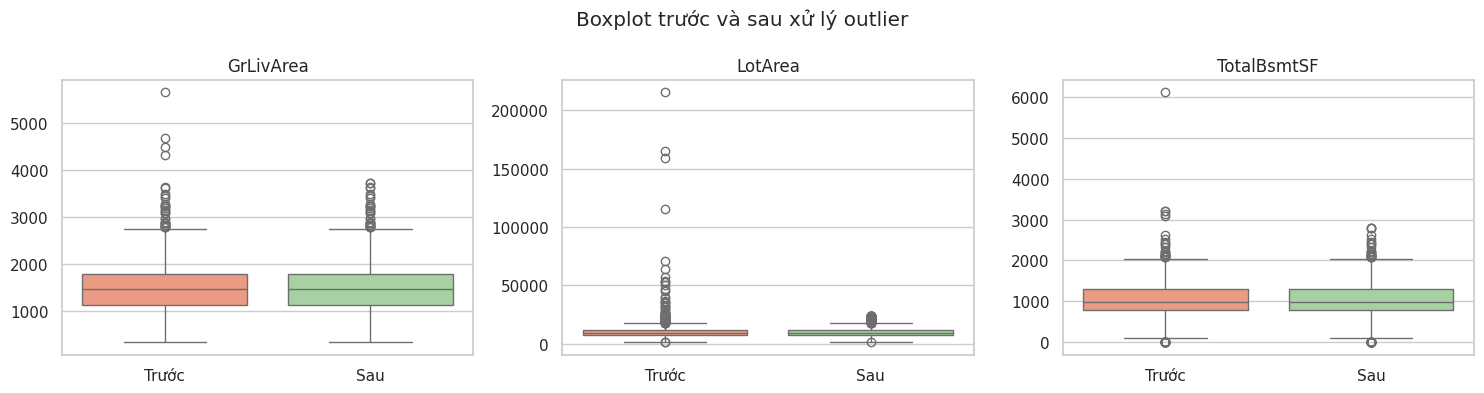

In [29]:
# So sánh trước/sau xử lý outlier
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['GrLivArea', 'LotArea', 'TotalBsmtSF']):
    d = pd.DataFrame({'Trước': train[c], 'Sau': train_c[c]})
    sns.boxplot(data=d, ax=ax, palette=['#fc9272', '#a1d99b']); ax.set_title(c)
plt.suptitle('Boxplot trước và sau xử lý outlier'); savefig('fig05_before_after_outlier.png')

---
## 2.3 Categorical Data
### 2.3.1 Phân loại Nominal và Ordinal
- **Ordinal:** các giá trị có thứ tự rõ ràng (chất lượng Ex > Gd > TA > Fa > Po, mức độ hoàn thiện, độ dốc...). Mã hóa thành số nguyên **giữ đúng thứ tự**.
- **Nominal:** không có thứ tự (khu phố, kiểu mái, loại móng...). Dùng One-Hot để không áp đặt thứ tự giả.
- `MSSubClass` và `MoSold` là số nhưng thực chất là **mã danh mục** → ép sang chuỗi và xử lý như nominal.
- `OverallQual`, `OverallCond` (1–10) đã là ordinal dạng số → giữ nguyên.

In [30]:
qual = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_maps = {
    'ExterQual': qual, 'ExterCond': qual, 'BsmtQual': qual, 'BsmtCond': qual, 'HeatingQC': qual,
    'KitchenQual': qual, 'FireplaceQu': qual, 'GarageQual': qual, 'GarageCond': qual, 'PoolQC': qual,
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'LotShape': {'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3},
    'LandSlope': {'Sev': 0, 'Mod': 1, 'Gtl': 2},
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},
    'Fence': {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'Utilities': {'ELO': 0, 'NoSeWa': 1, 'NoSeWr': 2, 'AllPub': 3},
}
for df in (train_c, test_c):
    df['MSSubClass'] = df['MSSubClass'].astype(str); df['MoSold'] = df['MoSold'].astype(str)

obj_cols = train_c.select_dtypes(exclude='number').columns.tolist()
nominal_cols = [c for c in obj_cols if c not in ordinal_maps]
ordinal_cols = list(ordinal_maps)
print(f'Ordinal: {len(ordinal_cols)} cột | Nominal: {len(nominal_cols)} cột')
cls = pd.DataFrame(
    [dict(column=c, type='Ordinal', n_categories=train_c[c].nunique(), order=' < '.join(ordinal_maps[c])) for c in ordinal_cols] +
    [dict(column=c, type='Nominal', n_categories=train_c[c].nunique(), order='-') for c in nominal_cols])
R['cat_classification'] = cls.to_dict('records')
cls

Ordinal: 20 cột | Nominal: 25 cột


,column,type,n_categories,order
0,ExterQual,Ordinal,4,None < Po < Fa < TA < Gd < Ex
1,ExterCond,Ordinal,5,None < Po < Fa < TA < Gd < Ex
2,BsmtQual,Ordinal,5,None < Po < Fa < TA < Gd < Ex
3,BsmtCond,Ordinal,5,None < Po < Fa < TA < Gd < Ex
4,HeatingQC,Ordinal,5,None < Po < Fa < TA < Gd < Ex
5,KitchenQual,Ordinal,4,None < Po < Fa < TA < Gd < Ex
6,FireplaceQu,Ordinal,6,None < Po < Fa < TA < Gd < Ex
7,GarageQual,Ordinal,6,None < Po < Fa < TA < Gd < Ex
8,GarageCond,Ordinal,6,None < Po < Fa < TA < Gd < Ex
9,PoolQC,Ordinal,4,None < Po < Fa < TA < Gd < Ex


### 2.3.2 Ordinal Encoding

In [31]:
def ordinal_encode(df):
    df = df.copy()
    for c, mp in ordinal_maps.items():
        df[c] = df[c].map(mp)
    return df

train_o, test_o = ordinal_encode(train_c), ordinal_encode(test_c)
print('NaN sau ordinal encoding (train/test):', train_o[ordinal_cols].isna().sum().sum(), '/', test_o[ordinal_cols].isna().sum().sum())

NaN sau ordinal encoding (train/test): 0 / 0


### 2.3.3 One-Hot Encoding

In [32]:
ohe = OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False).fit(train_o[nominal_cols])
def clean(n): return re.sub(r'[^0-9a-zA-Z]+', '_', n).strip('_')
ohe_names = [clean(n) for n in ohe.get_feature_names_out(nominal_cols)]
assert len(set(ohe_names)) == len(ohe_names)

def onehot(df):
    d = pd.DataFrame(ohe.transform(df[nominal_cols]), columns=ohe_names, index=df.index).astype('int8')
    return pd.concat([df.drop(columns=nominal_cols), d], axis=1)

train_e, test_e = onehot(train_o), onehot(test_o)
print('Số cột One-Hot tạo ra:', len(ohe_names))
print('Shape sau encoding -> train:', train_e.shape, '| test:', test_e.shape)
R['shape_encoded'] = {'train': list(train_e.shape), 'test': list(test_e.shape), 'n_ohe': len(ohe_names)}

Số cột One-Hot tạo ra: 193
Shape sau encoding -> train: (1458, 249) | test: (1459, 248)


### 2.3.4 Kiểm tra dữ liệu sau Encoding

In [33]:
checks = {}
feat_tr = train_e.drop(columns=TARGET)
checks['Không còn cột kiểu chữ (object)'] = int(feat_tr.select_dtypes(exclude='number').shape[1]) == 0
checks['Không còn NaN (train)'] = int(feat_tr.isna().sum().sum()) == 0
checks['Không còn NaN (test)'] = int(test_e.isna().sum().sum()) == 0
checks['Train và test cùng bộ cột'] = list(feat_tr.columns) == list(test_e.columns)
checks['Ordinal nằm trong miền hợp lệ'] = all(train_e[c].between(min(m.values()), max(m.values())).all() for c, m in ordinal_maps.items())

# Mỗi biến nominal (không nhị phân) phải có tổng các cột dummy = 1 trên mỗi dòng
ok_sum, unseen_test = True, {}
for c in nominal_cols:
    cols = [n for n in ohe_names if n.startswith(clean(c) + '_')]
    if train_c[c].nunique() > 2:
        ok_sum &= bool((train_e[cols].sum(axis=1) == 1).all())
        u = int((test_e[cols].sum(axis=1) == 0).sum())
        if u: unseen_test[c] = u
checks['Tổng dummy = 1 mỗi dòng (train)'] = ok_sum
R['checks'] = {k: bool(v) for k, v in checks.items()}; R['unseen_test'] = unseen_test
print(pd.Series(checks).to_string())
print('\nDòng test có nhãn lạ chưa thấy ở train (được mã hóa toàn 0):', unseen_test)

Không còn cột kiểu chữ (object)    True
Không còn NaN (train)              True
Không còn NaN (test)               True
Train và test cùng bộ cột          True
Ordinal nằm trong miền hợp lệ      True
Tổng dummy = 1 mỗi dòng (train)    True

Dòng test có nhãn lạ chưa thấy ở train (được mã hóa toàn 0): {'MSSubClass': 1}


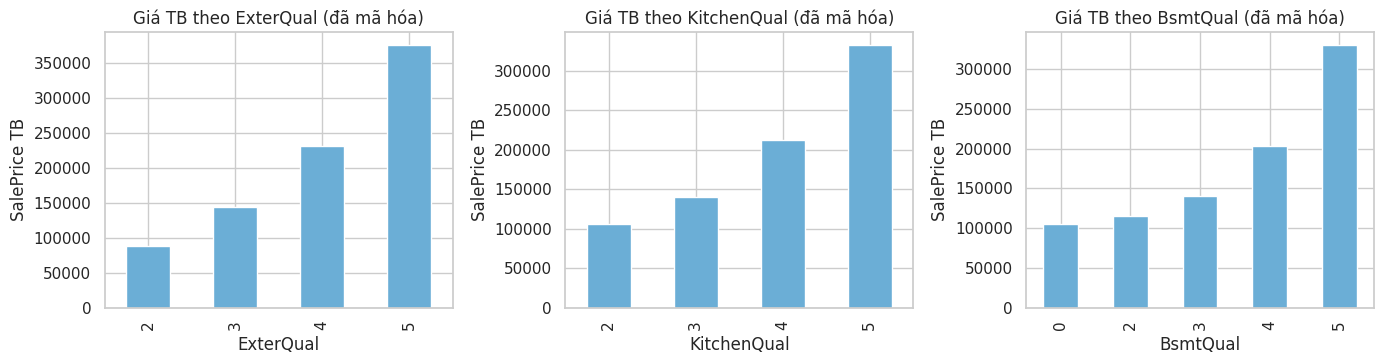

Các cột ordinal có giá TB tăng đơn điệu theo mã: ['ExterQual', 'BsmtQual', 'HeatingQC', 'KitchenQual', 'PoolQC', 'BsmtExposure', 'GarageFinish', 'PavedDrive', 'Utilities']
Các cột không đơn điệu (cần lưu ý): ['ExterCond', 'BsmtCond', 'FireplaceQu', 'GarageQual', 'GarageCond', 'BsmtFinType1', 'BsmtFinType2', 'Functional', 'LotShape', 'LandSlope', 'Fence']


In [34]:
# Kiểm tra thứ tự ordinal có hợp lý: giá trung bình phải tăng theo mức mã hóa
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, ['ExterQual', 'KitchenQual', 'BsmtQual']):
    train_e.groupby(c)[TARGET].mean().plot(kind='bar', ax=ax, color='#6baed6')
    ax.set_title(f'Giá TB theo {c} (đã mã hóa)'); ax.set_ylabel('SalePrice TB')
savefig('fig06_ordinal_check.png')
mono = {c: bool(train_e.groupby(c)[TARGET].mean().is_monotonic_increasing) for c in ordinal_cols}
R['ordinal_monotonic'] = mono
print('Các cột ordinal có giá TB tăng đơn điệu theo mã:', [c for c, v in mono.items() if v])
print('Các cột không đơn điệu (cần lưu ý):', [c for c, v in mono.items() if not v])

In [35]:
train_e.drop(columns='Id').head(3).T.head(12)

,0,1,2
LotFrontage,65.0,80.0,68.0
LotArea,8450.0,9600.0,11250.0
LotShape,3.0,3.0,2.0
Utilities,3.0,3.0,3.0
LandSlope,2.0,2.0,2.0
OverallQual,7.0,6.0,7.0
OverallCond,5.0,8.0,5.0
YearBuilt,2003.0,1976.0,2001.0
YearRemodAdd,2003.0,1976.0,2002.0
MasVnrArea,196.0,0.0,162.0


---
## 2.4 Numerical Data
### 2.4.1 Chọn scaler cho từng nhóm cột
| Nhóm | Scaler | Lý do |
|---|---|---|
| Biến liên tục, biến đếm, biến năm | **StandardScaler** | Đưa về mean=0, std=1; phù hợp mô hình tuyến tính/Ridge/Lasso, SVM, KNN, mạng nơ-ron. |
| Các cột ordinal đã mã hóa + `OverallQual/OverallCond` | **MinMaxScaler** (cần thiết) | Có miền giá trị hữu hạn, không phân phối chuẩn → đưa về [0, 1] giữ nguyên khoảng cách tương đối giữa các mức. |
| Cột One-Hot (0/1) | Không scale | Đã nằm trong [0, 1]. |
| `Id`, `SalePrice` | Không scale | Id không phải đặc trưng; SalePrice là biến mục tiêu (giữ giá trị gốc để dễ diễn giải). |

In [36]:
minmax_cols = ordinal_cols + ['OverallQual', 'OverallCond']
exclude = ['Id', TARGET] + ohe_names
standard_cols = [c for c in train_e.columns if c not in exclude + minmax_cols]
print('StandardScaler:', len(standard_cols), 'cột | MinMaxScaler:', len(minmax_cols), 'cột | One-Hot (giữ nguyên):', len(ohe_names))
R['n_scaled'] = {'standard': len(standard_cols), 'minmax': len(minmax_cols), 'ohe': len(ohe_names)}

std_sc = StandardScaler().fit(train_e[standard_cols])
mm_sc = MinMaxScaler().fit(train_e[minmax_cols])

def scale(df):
    df = df.copy()
    df[standard_cols] = std_sc.transform(df[standard_cols])
    df[minmax_cols] = mm_sc.transform(df[minmax_cols])
    return df

train_s, test_s = scale(train_e), scale(test_e)

StandardScaler: 32 cột | MinMaxScaler: 22 cột | One-Hot (giữ nguyên): 193


### 2.4.2 So sánh phân phối trước và sau chuẩn hóa

In [37]:
show = ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'YearBuilt', 'KitchenQual', 'OverallQual']
def stat(df, c): s = df[c]; return dict(mean=s.mean(), std=s.std(), min=s.min(), max=s.max(), skew=s.skew())
comp = pd.concat({'Trước': pd.DataFrame({c: stat(train_e, c) for c in show}).T,
                  'Sau (train)': pd.DataFrame({c: stat(train_s, c) for c in show}).T,
                  'Sau (test)': pd.DataFrame({c: stat(test_s, c) for c in show}).T}, axis=1).round(3)
R['scale_compare'] = {c: {k: {m: float(v) for m, v in comp.loc[c, k].items()} for k in ['Trước', 'Sau (train)', 'Sau (test)']} for c in show}
comp

Trước                                    Sau (train)                             Sau (test)                            
                 mean       std     min       max   skew        mean    std    min    max   skew       mean    std    min    max   skew
GrLivArea    1509.536   503.184   334.0   3718.50  0.901       0.000  1.000 -2.337  4.391  0.901     -0.049  0.953 -2.192  4.391  0.947
LotArea      9832.110  4124.712  1300.0  23766.50  0.980       0.000  1.000 -2.069  3.379  0.980     -0.045  0.976 -2.028  3.379  0.804
TotalBsmtSF  1051.785   411.458     0.0   2801.25  0.409      -0.000  1.000 -2.557  4.253  0.409     -0.019  1.053 -2.557  4.253  0.357
YearBuilt    1971.218    30.194  1872.0   2010.00 -0.612       0.000  1.000 -3.287  1.285 -0.612      0.005  1.007 -3.055  1.285 -0.588
KitchenQual     3.510     0.662     2.0      5.00  0.384       0.503  0.221  0.000  1.000  0.384      0.503  0.220  0.000  1.000  0.492
OverallQual     6.094     1.376     1.0     10.00  0.201       0.566  0.153  0.000  1.000  0.201      0.564  0.160  0.000  1.000  0.181

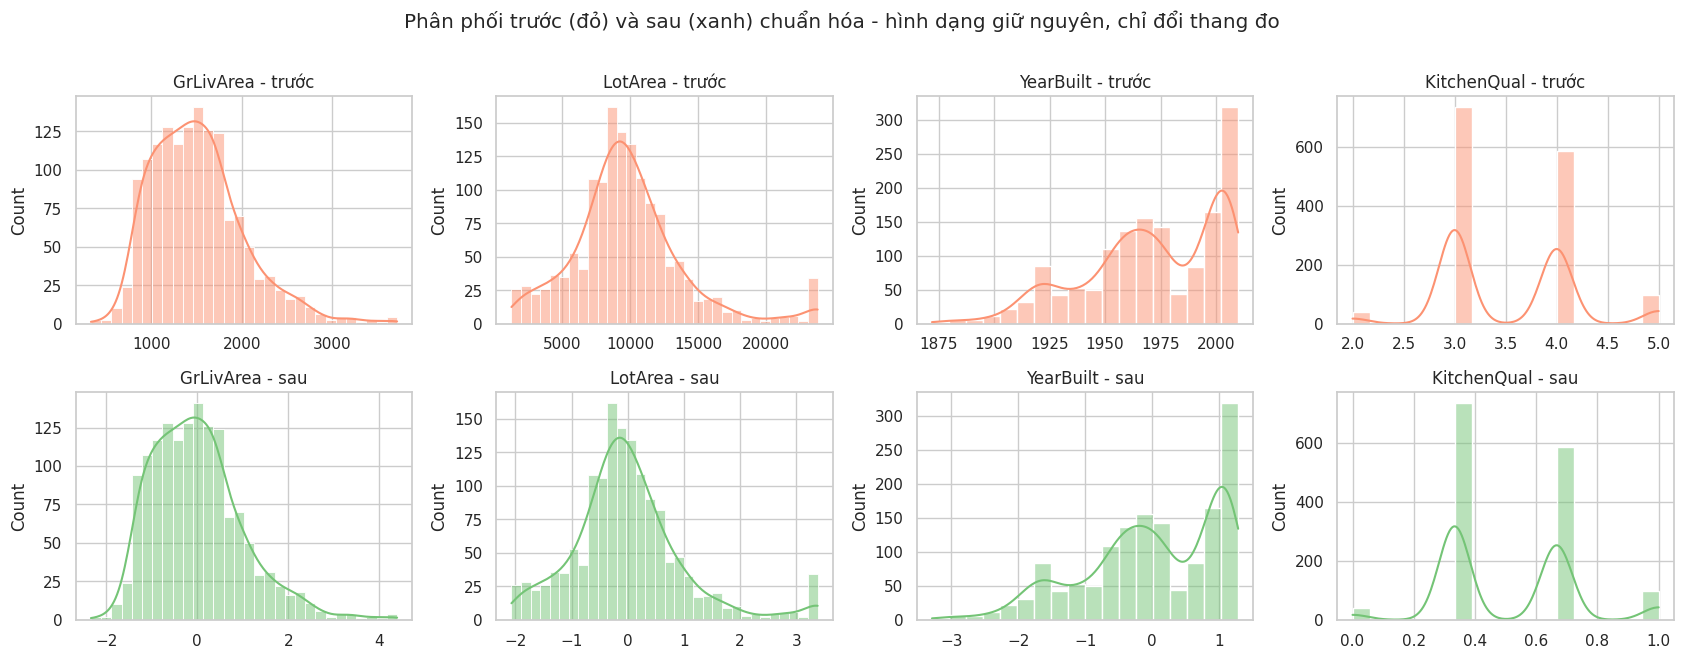

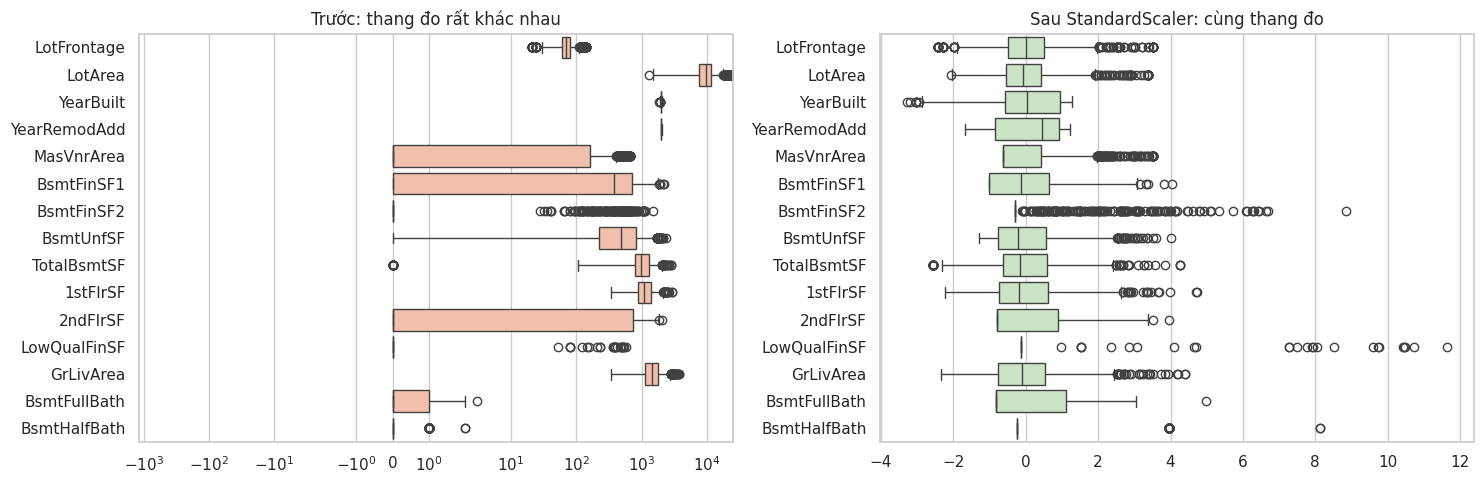

StandardScaler (train): |mean| max = 0.0 | std trong [ 1.0 , 1.0 ]
MinMax (train): min = 0.0 | max = 1.0
MinMax (test) : min = 0.0 | max = 1.0
Skew trung bình trước/sau: 2.862 / 2.862


In [38]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for j, c in enumerate(['GrLivArea', 'LotArea', 'YearBuilt', 'KitchenQual']):
    sns.histplot(train_e[c], kde=True, ax=axes[0, j], color='#fc9272'); axes[0, j].set_title(f'{c} - trước')
    sns.histplot(train_s[c], kde=True, ax=axes[1, j], color='#74c476'); axes[1, j].set_title(f'{c} - sau')
    axes[0, j].set_xlabel(''); axes[1, j].set_xlabel('')
plt.suptitle('Phân phối trước (đỏ) và sau (xanh) chuẩn hóa - hình dạng giữ nguyên, chỉ đổi thang đo', y=1.01)
savefig('fig07_scaling_hist.png')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=train_e[standard_cols[:15]], orient='h', ax=axes[0], color='#fcbba1'); axes[0].set_title('Trước: thang đo rất khác nhau'); axes[0].set_xscale('symlog')
sns.boxplot(data=train_s[standard_cols[:15]], orient='h', ax=axes[1], color='#c7e9c0'); axes[1].set_title('Sau StandardScaler: cùng thang đo')
savefig('fig08_scaling_box.png')

chk = pd.DataFrame({'mean': train_s[standard_cols].mean(), 'std': train_s[standard_cols].std(ddof=0)})
print('StandardScaler (train): |mean| max =', chk['mean'].abs().max().round(6), '| std trong [', chk['std'].min().round(3), ',', chk['std'].max().round(3), ']')
print('MinMax (train): min =', train_s[minmax_cols].min().min(), '| max =', train_s[minmax_cols].max().max())
print('MinMax (test) : min =', test_s[minmax_cols].min().min(), '| max =', test_s[minmax_cols].max().max())
print('Skew trung bình trước/sau:', round(train_e[standard_cols].skew().mean(), 3), '/', round(train_s[standard_cols].skew().mean(), 3))
R['scale_check'] = dict(mean_abs_max=float(chk['mean'].abs().max()), std_min=float(chk['std'].min()), std_max=float(chk['std'].max()),
                        mm_train=[float(train_s[minmax_cols].min().min()), float(train_s[minmax_cols].max().max())],
                        mm_test=[float(test_s[minmax_cols].min().min()), float(test_s[minmax_cols].max().max())],
                        skew_before=float(train_e[standard_cols].skew().mean()), skew_after=float(train_s[standard_cols].skew().mean()))

**Nhận xét:** chuẩn hóa chỉ thay đổi *thang đo* (mean, std, min, max), **không làm thay đổi hình dạng phân phối** — độ lệch (skewness) giữ nguyên. Nếu cần phân phối gần chuẩn hơn cho các biến lệch phải mạnh (`LotArea`, `GrLivArea`...), có thể bổ sung `log1p` hoặc `PowerTransformer` trước khi scale; ở đây chưa áp dụng vì ngoài phạm vi yêu cầu và các mô hình cây không cần.

---
## 3. Sản phẩm: dataset đã tiền xử lý
Xuất hai bản: **bản đã scale** (dùng cho mô hình tuyến tính, SVM, KNN, NN) và **bản chỉ encoding, chưa scale** (dùng cho mô hình cây).

In [39]:
train_s.to_csv(OUT_DIR / 'train_processed.csv', index=False)
test_s.to_csv(OUT_DIR / 'test_processed.csv', index=False)
train_e.to_csv(OUT_DIR / 'train_encoded_unscaled.csv', index=False)
test_e.to_csv(OUT_DIR / 'test_encoded_unscaled.csv', index=False)

feat = train_s.drop(columns=['Id', TARGET])
final = {
    'Không NaN/inf (train)': bool(np.isfinite(feat.values).all()),
    'Không NaN/inf (test)': bool(np.isfinite(test_s.drop(columns='Id').values).all()),
    'Toàn bộ cột là số': feat.select_dtypes(exclude='number').shape[1] == 0,
    'Train/test cùng bộ cột đặc trưng': list(feat.columns) == [c for c in test_s.columns if c != 'Id'],
}
print(pd.Series(final).to_string())
print('\ntrain_processed:', train_s.shape, '| test_processed:', test_s.shape, '| số đặc trưng:', feat.shape[1])
R['final_shape'] = {'train': list(train_s.shape), 'test': list(test_s.shape), 'n_features': feat.shape[1]}
R['final_checks'] = {k: bool(v) for k, v in final.items()}

# Smoke test: mô hình chạy trực tiếp trên dataset
yl = np.log1p(train_s[TARGET]); cv = KFold(5, shuffle=True, random_state=42)
smoke = {}
for name, mdl, X in [('Ridge (bản scale)', Ridge(alpha=10), feat),
                     ('RandomForest (bản chưa scale)', RandomForestRegressor(200, random_state=42, n_jobs=-1), train_e.drop(columns=['Id', TARGET]))]:
    smoke[name] = float(-cross_val_score(mdl, X, yl, cv=cv, scoring='neg_root_mean_squared_error').mean())
R['smoke_test'] = smoke
print('\nRMSE (log) CV 5-fold:', {k: round(v, 4) for k, v in smoke.items()})

Không NaN/inf (train)               True
Không NaN/inf (test)                True
Toàn bộ cột là số                   True
Train/test cùng bộ cột đặc trưng    True

train_processed: (1458, 249) | test_processed: (1459, 248) | số đặc trưng: 247



RMSE (log) CV 5-fold: {'Ridge (bản scale)': 0.1164, 'RandomForest (bản chưa scale)': 0.138}


In [40]:
R['n_train_removed'] = int(anom_mask.sum())
json.dump(R, open(OUT_DIR / 'results.json', 'w'), ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('Đã lưu:', sorted(p.name for p in OUT_DIR.glob('*.csv')))

Đã lưu: ['test_encoded_unscaled.csv', 'test_processed.csv', 'train_encoded_unscaled.csv', 'train_no_missing.csv', 'train_processed.csv']


# GIAI ĐOẠN 3–4 — Feature Selection, xây dựng và đánh giá mô hình
Quan hệ với Giai đoạn 2: Giai đoạn 2 xử lý toàn bộ `train.csv` và `test.csv` của Kaggle (file test **không có nhãn**) để tạo dataset dùng chung. Giai đoạn 3–4 cần một tập test **có nhãn** để đo sai số, nên tách 20% từ `train.csv`; vì vậy phần tiền xử lý ở đây được làm lại theo thứ tự *chia dữ liệu trước, fit imputation/one-hot chỉ trên training set* nhằm tránh data leakage khi chọn feature. Các quy tắc làm sạch dùng chung với Giai đoạn 2: `NA` nghĩa là "không có" → `None`, mã hoá ordinal cho các cột chất lượng, loại 2 nhà bất thường (`GrLivArea > 4000` và `SalePrice < 300000`, tức Id 524 và 1299), one-hot cho biến nominal. Khác biệt có chủ đích: ở đây `LotFrontage` và các cột thiếu còn lại dùng median/most-frequent fit trên training set (thay vì median theo `Neighborhood`), và chuẩn hoá chỉ áp dụng cho SVR bên trong pipeline.

## Lab04 — Feature Selection cho bài toán House Price Prediction

**Dataset:** Kaggle *House Prices — Advanced Regression Techniques* (`train.csv`, có nhãn `SalePrice`)  
**Models:** SVR · XGBoost · Random Forest  
**Feature Selection:** Filter (Pearson, Mutual Information) · Wrapper (RFE/RFECV) · Embedded (XGBoost importance)

Quy trình tổng quát:

```text
Dataset → Preprocessing → Train/Test Split → Baseline → Feature Selection → Train Model → Evaluate → Compare
```

**Nguyên tắc chống Data Leakage của notebook này**

- Mọi bộ chọn feature (Pearson, MI, RFE, XGBoost importance) chỉ được `fit` trên **training set**. Test set chỉ dùng để báo cáo kết quả cuối.
- Khi chọn số lượng feature K, notebook dùng **5-fold CV bên trong training set** và **tính lại ranking trong từng fold** (ranking chỉ nhìn thấy phần train của fold, không thấy phần validation của fold).
- K tốt nhất được chọn **chỉ dựa trên CV RMSE**. Các đường cong theo Test được vẽ để phân tích, không dùng để chọn.
- Tại sao fit selector trên toàn bộ dataset trước khi split là sai? Vì ranking khi đó đã "nhìn thấy" `SalePrice` của các mẫu test; tập feature được chọn thiên về những feature tình cờ tương quan với nhãn của test, nên sai số test bị đánh giá thấp hơn thực tế (optimistic bias) và không phản ánh khả năng tổng quát hoá.

### 1. Import Libraries

In [41]:
import time, warnings, json
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression, RFE, RFECV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
TOLERANCE = 0.01
MODEL_NAMES = ['SVR', 'XGBoost', 'Random Forest']

OUT_DIR = BASE_OUT / 'phase3_feature_selection'; FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

### 2. Load Dataset
Đọc `train.csv` (file duy nhất có nhãn `SalePrice`). `test.csv` của Kaggle không có nhãn nên không dùng để đánh giá; tập test của bài lab được tách từ `train.csv`.

In [42]:
DATA_PATH = DATA_DIR / 'train.csv'
raw = pd.read_csv(DATA_PATH)
print('Nguồn dữ liệu:', DATA_PATH)
print('Shape:', raw.shape)
raw.head()

Nguồn dữ liệu: /mnt/user-data/uploads/train.csv
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,...,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 3. Exploratory Data Analysis

In [43]:
print(raw.dtypes.value_counts().to_string())
num_raw = raw.select_dtypes(include='number').columns.drop(['Id', 'SalePrice'])
cat_raw = raw.select_dtypes(exclude='number').columns
print(f'\nNumerical features: {len(num_raw)} | Categorical features: {len(cat_raw)}')

missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
display(pd.DataFrame({'Missing': missing, 'Pct (%)': (missing / len(raw) * 100).round(2)}))
print('Duplicated rows:', raw.duplicated().sum(), '| Duplicated Id:', raw['Id'].duplicated().sum())

str        43
int64      35
float64     3

Numerical features: 36 | Categorical features: 43


,Missing,Pct (%)
PoolQC,1453,99.5200
MiscFeature,1406,96.3000
Alley,1369,93.7700
Fence,1179,80.7500
MasVnrType,872,59.7300
FireplaceQu,690,47.2600
LotFrontage,259,17.7400
GarageType,81,5.5500
GarageYrBlt,81,5.5500
GarageFinish,81,5.5500


Duplicated rows: 0 | Duplicated Id: 0


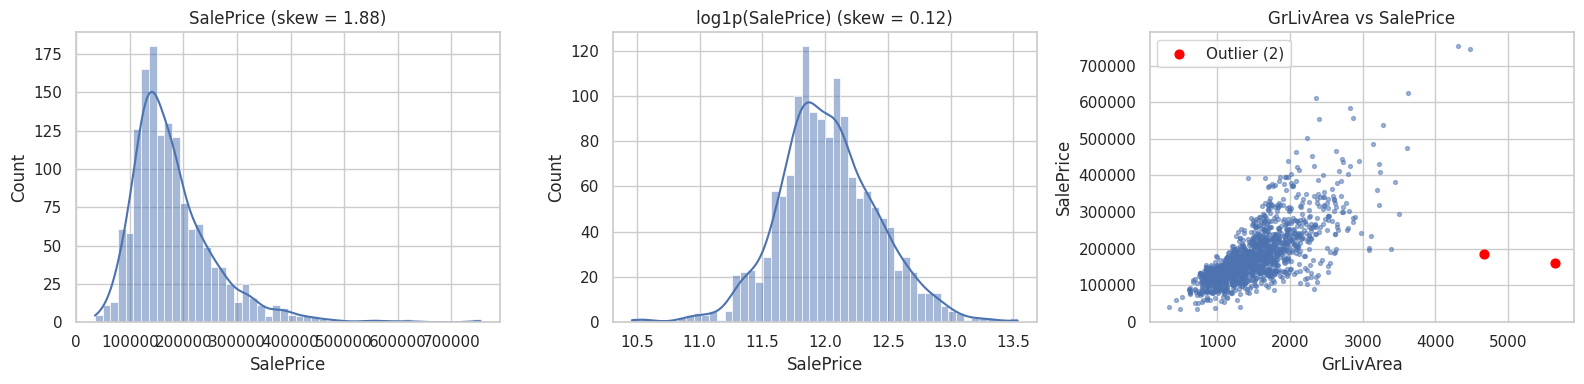

In [44]:
outlier_mask = (raw['GrLivArea'] > 4000) & (raw['SalePrice'] < 300000)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(raw['SalePrice'], bins=50, kde=True, ax=ax[0]); ax[0].set_title(f"SalePrice (skew = {raw['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(raw['SalePrice']), bins=50, kde=True, ax=ax[1]); ax[1].set_title(f"log1p(SalePrice) (skew = {np.log1p(raw['SalePrice']).skew():.2f})")
ax[2].scatter(raw['GrLivArea'], raw['SalePrice'], s=8, alpha=.5)
ax[2].scatter(raw.loc[outlier_mask, 'GrLivArea'], raw.loc[outlier_mask, 'SalePrice'], color='red', s=40, label=f'Outlier ({outlier_mask.sum()})')
ax[2].set_xlabel('GrLivArea'); ax[2].set_ylabel('SalePrice'); ax[2].legend(); ax[2].set_title('GrLivArea vs SalePrice')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_target_outliers.png', dpi=150); plt.show()

`SalePrice` lệch phải mạnh nên mô hình được huấn luyện trên `log1p(SalePrice)`; mọi metric (RMSE, MAE, R²) được tính lại trên thang giá gốc (USD) để dễ diễn giải. Hai điểm `GrLivArea > 4000` nhưng giá thấp là outlier đã được tác giả dataset khuyến nghị loại bỏ (quy tắc cố định, không phụ thuộc phân phối dữ liệu nên không gây leakage).

### 4. Data Preprocessing
Chia thành 2 bước: (a) làm sạch **xác định** (không học tham số từ dữ liệu) thực hiện trước split; (b) imputation và one-hot **có học tham số** được fit chỉ trên training set.

In [45]:
NONE_COLS = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']
QUAL = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ORDINAL_MAPS = {c: QUAL for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
                                  'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']}
ORDINAL_MAPS['BsmtExposure'] = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
ORDINAL_MAPS['BsmtFinType1'] = ORDINAL_MAPS['BsmtFinType2'] = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
ORDINAL_MAPS['GarageFinish'] = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}

def clean_raw(df):
    df = df.drop(columns='Id').copy()
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    df[NONE_COLS] = df[NONE_COLS].fillna('None')
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    for col, mapping in ORDINAL_MAPS.items():
        df[col] = df[col].map(mapping)
    return df

data = raw.loc[~outlier_mask].reset_index(drop=True)
X = clean_raw(data.drop(columns='SalePrice'))
y = np.log1p(data['SalePrice'])
print(f'Loại {outlier_mask.sum()} outlier -> {len(data)} mẫu | {X.shape[1]} cột trước encoding')
print('Missing còn lại (sẽ imputation trong preprocessor):', X.isna().sum()[X.isna().sum() > 0].to_dict())

Loại 2 outlier -> 1458 mẫu | 79 cột trước encoding
Missing còn lại (sẽ imputation trong preprocessor): {'LotFrontage': 259, 'Electrical': 1}


Quy ước xử lý: `NA` trong các cột như `PoolQC`, `Alley`, `BsmtQual`, `Garage*`... nghĩa là *không có hạng mục đó* (theo data description) nên điền `None`; các cột chất lượng có thứ bậc được mã hoá ordinal; `MSSubClass` là mã nhóm nên coi là categorical. Phần missing còn lại (ví dụ `LotFrontage`, `Electrical`) dùng median/most-frequent được fit trên training set.

### 5. Train/Test Split

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(exclude='number').columns
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
constant_cols = X_train.columns[X_train.nunique() <= 1]
X_train, X_test = X_train.drop(columns=constant_cols), X_test.drop(columns=constant_cols)
y_train_usd, y_test_usd = np.expm1(y_train), np.expm1(y_test)
N_FEATURES = X_train.shape[1]

print(f'Train: {X_train.shape} | Test: {X_test.shape} | Số feature sau preprocessing: {N_FEATURES}')
print(f'Numerical: {len(num_cols)} (gồm cột ordinal) | Categorical gốc: {len(cat_cols)} -> one-hot | Bỏ cột hằng số: {len(constant_cols)}')
print('Missing sau preprocessing (train/test):', int(X_train.isna().sum().sum()), '/', int(X_test.isna().sum().sum()))

Train: (1166, 253) | Test: (292, 253) | Số feature sau preprocessing: 253
Numerical: 49 (gồm cột ordinal) | Categorical gốc: 30 -> one-hot | Bỏ cột hằng số: 0
Missing sau preprocessing (train/test): 0 / 0


Preprocessor được `fit` chỉ trên `X_train` rồi `transform` cho `X_test`. `StandardScaler` **không** áp dụng ở đây mà nằm trong pipeline của SVR (xem mục 6), vì SVR dùng kernel RBF dựa trên khoảng cách nên nhạy với thang đo; XGBoost và Random Forest dựa trên ngưỡng chia cây, bất biến với phép biến đổi đơn điệu của feature nên không cần scale.

### 6. Baseline Models

- **SVR (RBF kernel):** hồi quy trong ống ε-insensitive; siêu tham số chính `C` (mức phạt sai số), `epsilon` (độ rộng ống không phạt), `gamma` (độ rộng kernel; giữ `'scale'` để tự co giãn theo số feature). Bắt buộc `StandardScaler` vì kernel RBF dùng khoảng cách Euclid.
- **XGBoost:** Gradient Boosting — cộng dần các cây quyết định nông, mỗi cây sửa phần dư (gradient của loss) của tổ hợp trước, có regularization.
- **Random Forest:** Bagging — nhiều cây sâu huấn luyện trên bootstrap và tập con feature ngẫu nhiên, dự đoán lấy trung bình.

Siêu tham số của mỗi model được **tune một lần bằng GridSearchCV 5-fold trên training set với toàn bộ feature** (tiêu chí RMSE trên `log1p(SalePrice)`), sau đó giữ **cố định** cho mọi thí nghiệm Top-K để so sánh công bằng. Các tham số phụ thuộc số feature được viết dạng tỉ lệ (`gamma='scale'`, `max_features` là phân số, `colsample_bytree` là phân số).

In [47]:
BASE_PARAMS = {
    'SVR': {},
    'XGBoost': dict(subsample=0.8, colsample_bytree=0.5),
    'Random Forest': dict(n_estimators=200),
}
GRIDS = {
    'SVR': {'svr__C': [1, 3, 10, 30, 100], 'svr__epsilon': [0.01, 0.05, 0.1]},
    'XGBoost': {'max_depth': [3, 4], 'learning_rate': [0.03, 0.06], 'n_estimators': [300, 600]},
    'Random Forest': {'max_features': [0.2, 0.33, 0.5], 'min_samples_leaf': [1, 2]},
}

def make_model(name, **params):
    params = {**BASE_PARAMS[name], **params}
    if name == 'SVR':
        return make_pipeline(StandardScaler(), SVR(kernel='rbf', gamma='scale', **params))
    if name == 'XGBoost':
        return XGBRegressor(random_state=RANDOM_STATE, n_jobs=1, tree_method='hist', **params)
    return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1, **params)

cv = KFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
best_params, tuning_rows = {}, []
for name in MODEL_NAMES:
    gs = GridSearchCV(make_model(name), GRIDS[name], cv=cv, scoring='neg_root_mean_squared_error')
    t0 = time.perf_counter(); gs.fit(X_train, y_train)
    best_params[name] = {k.split('__')[-1]: v for k, v in gs.best_params_.items()}
    tuning_rows.append({'Model': name, 'Best_Params': best_params[name], 'CV_RMSLE': -gs.best_score_,
                        'Grid_Size': len(gs.cv_results_['params']), 'Tuning_Time': time.perf_counter() - t0})
tuning_df = pd.DataFrame(tuning_rows)
tuning_df

,Model,Best_Params,CV_RMSLE,Grid_Size,Tuning_Time
0,SVR,"{'C': 1, 'epsilon': 0.01}",0.1867,15,7.4109
1,XGBoost,"{'learning_rate': 0.06, 'max_depth': 3, 'n_est...",0.1162,8,18.7804
2,Random Forest,"{'max_features': 0.33, 'min_samples_leaf': 1}",0.1331,6,40.9689


In [48]:
def calculate_metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {'RMSE': float(np.sqrt(mean_squared_error(yt, yp))), 'MAE': float(mean_absolute_error(yt, yp)),
            'R2': float(r2_score(yt, yp)), 'RMSLE': float(np.sqrt(mean_squared_error(y_true_log, y_pred_log)))}

def evaluate_model(name, X_tr, y_tr, X_te, y_te):
    model = make_model(name, **best_params[name])
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); train_time = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(X_te); infer_time = time.perf_counter() - t0
    return {**calculate_metrics(y_te, pred), 'Training_Time': train_time, 'Inference_Time': infer_time}

def cv_metrics(name, X_tr, y_tr):
    folds = [evaluate_model(name, X_tr.iloc[a], y_tr.iloc[a], X_tr.iloc[b], y_tr.iloc[b]) for a, b in cv.split(X_tr)]
    f = pd.DataFrame(folds)
    return {'CV_RMSE': f.RMSE.mean(), 'CV_RMSE_std': f.RMSE.std(), 'CV_MAE': f.MAE.mean(), 'CV_R2': f.R2.mean()}

### 7. Baseline Evaluation
Baseline dùng toàn bộ feature hợp lệ sau preprocessing, cùng siêu tham số đã tune bằng CV, đánh giá bằng CV (trên train) và một lần trên test.

In [49]:
baseline_rows = []
for name in MODEL_NAMES:
    res = evaluate_model(name, X_train, y_train, X_test, y_test)
    baseline_rows.append({'Model': name, 'Num_Features': N_FEATURES, **{k: res[k] for k in ['RMSE', 'MAE', 'R2', 'RMSLE', 'Training_Time', 'Inference_Time']},
                          **cv_metrics(name, X_train, y_train), 'Params': str(best_params[name])})
baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv(OUT_DIR / 'baseline_results.csv', index=False)
baseline_df.drop(columns='Params')

,Model,Num_Features,RMSE,MAE,R2,RMSLE,Training_Time,Inference_Time,CV_RMSE,CV_RMSE_std,CV_MAE,CV_R2
0,SVR,253,"33,133.7719","19,486.6295",0.8012,0.1934,0.1522,0.0578,"40,169.7863","10,195.4738","19,894.5337",0.7431
1,XGBoost,253,"19,930.4684","14,180.1996",0.9281,0.1138,0.5560,0.0118,"23,701.0603","3,063.4338","14,304.3557",0.9123
2,Random Forest,253,"22,670.0135","15,787.3105",0.9070,0.1378,1.6594,0.0221,"27,605.5414","3,669.2160","16,572.9859",0.8809


### 8. Feature Selection
Bốn bộ xếp hạng, mỗi bộ là một hàm nhận `(X, y)` của **dữ liệu train** và trả về danh sách feature từ quan trọng nhất đến kém nhất. Sau one-hot mọi feature đều là số nên Pearson/MI áp dụng trực tiếp; với dummy nhị phân, Pearson chính là point-biserial correlation, và MI được tính với `discrete_features=True` cho các cột nhị phân. Ranking dùng `y = log1p(SalePrice)`, cùng thang với mục tiêu huấn luyện.

In [50]:
def rank_pearson(X, y):
    return X.corrwith(y).fillna(0).abs().sort_values(ascending=False, kind='stable').index.tolist()

def rank_mi(X, y):
    mi = mutual_info_regression(X, y, discrete_features=(X.nunique() <= 2).values, random_state=RANDOM_STATE)
    return pd.Series(mi, index=X.columns).sort_values(ascending=False, kind='stable').index.tolist()

def rank_xgb_importance(X, y):
    model = make_model('XGBoost', **best_params['XGBoost'], importance_type='gain').fit(X, y)
    return pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False, kind='stable').index.tolist()

def rank_rfe(X, y):
    estimator = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                             random_state=RANDOM_STATE, n_jobs=1, tree_method='hist')
    rfe = RFE(estimator, n_features_to_select=1, step=3).fit(X, y)
    return pd.Series(rfe.ranking_, index=X.columns).sort_values(kind='stable').index.tolist()

RANKERS = {'Pearson': rank_pearson, 'Mutual Information': rank_mi, 'RFE (XGBoost)': rank_rfe, 'XGBoost Importance': rank_xgb_importance}

#### 8.1 Filter Methods
Filter chấm điểm từng feature độc lập với model, nhanh và không tốn huấn luyện; nhược điểm là bỏ qua tương tác giữa feature và sự dư thừa (hai feature tương quan cao đều có điểm cao).

In [51]:
final_order = {}
t0 = time.perf_counter(); final_order['Pearson'] = rank_pearson(X_train, y_train); t_p = time.perf_counter() - t0
t0 = time.perf_counter(); final_order['Mutual Information'] = rank_mi(X_train, y_train); t_m = time.perf_counter() - t0
print(f'Thời gian xếp hạng: Pearson {t_p:.2f}s | MI {t_m:.2f}s')

corr = X_train.corrwith(y_train).fillna(0)
pearson_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['Pearson']})
pearson_table['Correlation'] = corr[pearson_table.Feature].values
pearson_table['Absolute Correlation'] = pearson_table['Correlation'].abs()
mi_scores = pd.Series(mutual_info_regression(X_train, y_train, discrete_features=(X_train.nunique() <= 2).values, random_state=RANDOM_STATE), index=X_train.columns)
mi_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['Mutual Information']})
mi_table['MI Score'] = mi_scores[mi_table.Feature].values
display(pearson_table.head(15)); display(mi_table.head(15))

Thời gian xếp hạng: Pearson 0.04s | MI 0.94s


,Rank,Feature,Correlation,Absolute Correlation
0,1,OverallQual,0.8135,0.8135
1,2,GrLivArea,0.7310,0.7310
2,3,GarageCars,0.6882,0.6882
3,4,KitchenQual,0.6788,0.6788
4,5,ExterQual,0.6733,0.6733
5,6,GarageArea,0.6642,0.6642
6,7,TotalBsmtSF,0.6502,0.6502
7,8,1stFlrSF,0.6155,0.6155
8,9,GarageFinish,0.6116,0.6116
9,10,BsmtQual,0.6070,0.6070


,Rank,Feature,MI Score
0,1,OverallQual,0.5353
1,2,GrLivArea,0.4745
2,3,GarageArea,0.3819
3,4,TotalBsmtSF,0.3614
4,5,GarageCars,0.3610
5,6,YearBuilt,0.3435
6,7,KitchenQual,0.3176
7,8,ExterQual,0.3103
8,9,1stFlrSF,0.3091
9,10,BsmtQual,0.3044


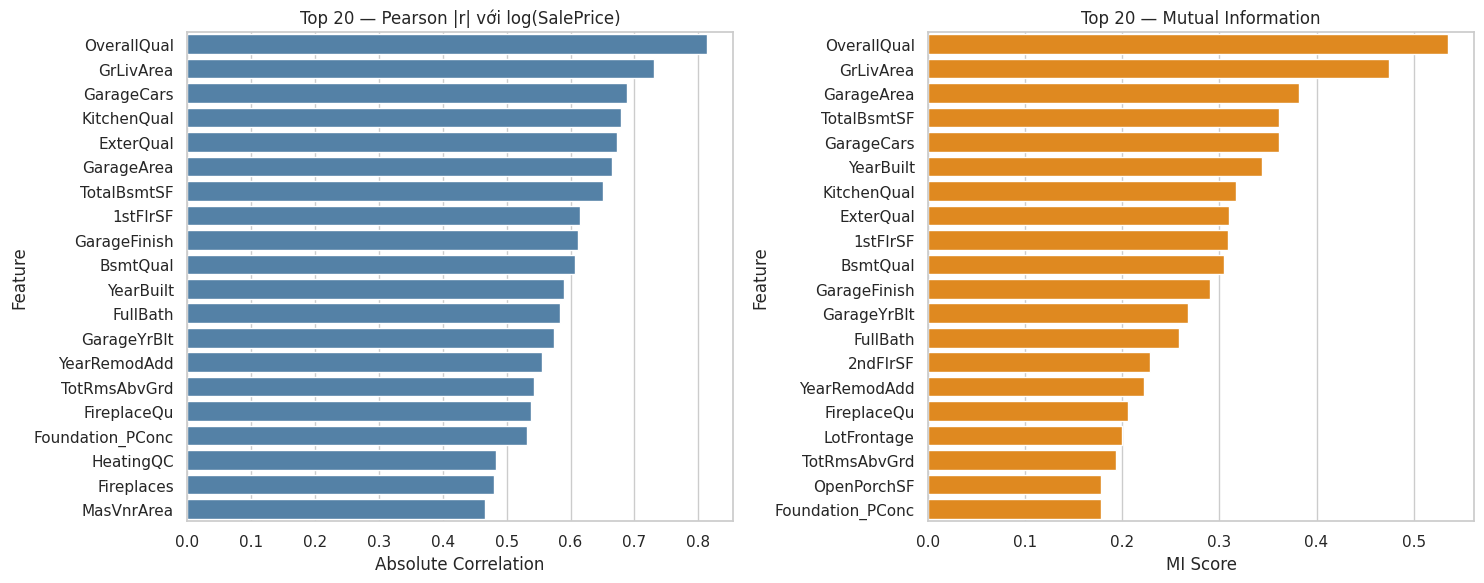

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=pearson_table.head(20), y='Feature', x='Absolute Correlation', color='steelblue', ax=ax[0]); ax[0].set_title('Top 20 — Pearson |r| với log(SalePrice)')
sns.barplot(data=mi_table.head(20), y='Feature', x='MI Score', color='darkorange', ax=ax[1]); ax[1].set_title('Top 20 — Mutual Information')
plt.tight_layout(); plt.savefig(FIG_DIR / 'chart6_filter_top_features.png', dpi=150); plt.show()

#### 8.2 Wrapper Methods
Wrapper dùng chính một model làm "hộp đen" để đánh giá tập feature: **RFE** huấn luyện estimator, loại dần các feature có importance thấp nhất (`step=3` feature mỗi vòng) cho đến còn 1, và thứ tự bị loại tạo ra ranking đầy đủ. Vì phải huấn luyện lại model nhiều lần nên tốn thời gian hơn Filter rất nhiều. Estimator là XGBoost nhẹ (100 cây, độ sâu 3) để giảm chi phí; tiêu chí xếp hạng là importance của estimator ở mỗi vòng. Ngoài ra **RFECV** (3-fold CV chỉ trên train, scoring RMSE trên log-target, `step=5`) được chạy một lần để tham khảo số feature tối ưu theo CV của chính wrapper.

In [53]:
t0 = time.perf_counter(); final_order['RFE (XGBoost)'] = rank_rfe(X_train, y_train); t_rfe = time.perf_counter() - t0
print(f'Thời gian RFE trên toàn bộ train: {t_rfe:.1f}s (so với Pearson {t_p:.2f}s, MI {t_m:.2f}s)')

rfecv_est = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                         random_state=RANDOM_STATE, n_jobs=1, tree_method='hist')
t0 = time.perf_counter()
rfecv = RFECV(rfecv_est, step=5, cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
              scoring='neg_root_mean_squared_error', min_features_to_select=5).fit(X_train, y_train)
t_rfecv = time.perf_counter() - t0
RFECV_N = int(rfecv.n_features_)
print(f'RFECV chọn {RFECV_N} feature (CV RMSLE = {-rfecv.cv_results_["mean_test_score"].max():.4f}, {t_rfecv:.1f}s)')
rfe_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['RFE (XGBoost)']})
rfe_table.head(15)

Thời gian RFE trên toàn bộ train: 4.6s (so với Pearson 0.04s, MI 0.94s)


RFECV chọn 118 feature (CV RMSLE = 0.1209, 9.0s)


,Rank,Feature
0,1,KitchenQual
1,2,OverallQual
2,3,GrLivArea
3,4,GarageCars
4,5,ExterQual
5,6,GarageFinish
6,7,CentralAir_N
7,8,BsmtQual
8,9,TotalBsmtSF
9,10,FireplaceQu


#### 8.3 Embedded Methods
Embedded: việc chọn/đánh giá feature diễn ra **ngay trong quá trình huấn luyện** model. Với XGBoost, mỗi lần chia nút cây chọn feature giảm loss nhiều nhất; tổng *gain* mà feature đóng góp qua toàn bộ các cây chính là importance. Tập feature được xếp hạng chỉ từ model huấn luyện trên train.

Số feature có importance > 0: 190 / 253


,Rank,Feature,Importance (gain)
0,1,ExterQual,0.1432
1,2,OverallQual,0.1144
2,3,GarageFinish,0.0550
3,4,MSZoning_RM,0.0401
4,5,GrLivArea,0.0395
5,6,BsmtQual,0.0368
6,7,KitchenQual,0.0362
7,8,FireplaceQu,0.0359
8,9,CentralAir_Y,0.0349
9,10,GarageCond,0.0223


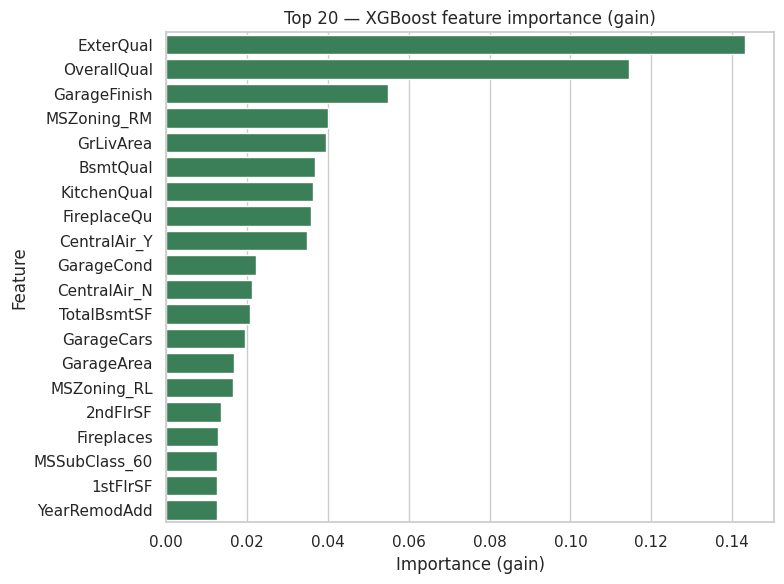

In [54]:
t0 = time.perf_counter(); final_order['XGBoost Importance'] = rank_xgb_importance(X_train, y_train); t_x = time.perf_counter() - t0
xgb_imp_model = make_model('XGBoost', **best_params['XGBoost'], importance_type='gain').fit(X_train, y_train)
xgb_imp = pd.Series(xgb_imp_model.feature_importances_, index=X_train.columns)
xgb_table = pd.DataFrame({'Rank': range(1, N_FEATURES + 1), 'Feature': final_order['XGBoost Importance']})
xgb_table['Importance (gain)'] = xgb_imp[xgb_table.Feature].values
print(f'Số feature có importance > 0: {(xgb_imp > 0).sum()} / {N_FEATURES}')
display(xgb_table.head(15))
plt.figure(figsize=(8, 6)); sns.barplot(data=xgb_table.head(20), y='Feature', x='Importance (gain)', color='seagreen')
plt.title('Top 20 — XGBoost feature importance (gain)'); plt.tight_layout()
plt.savefig(FIG_DIR / 'chart5_xgb_importance.png', dpi=150); plt.show()

### 9. Feature Ranking
Bảng tổng hợp thứ hạng (1 = quan trọng nhất) của 4 phương pháp. **Mean Rank** = trung bình cộng 4 thứ hạng (Borda count, trọng số bằng nhau). Đây chỉ là thước đo tham khảo để so sánh mức đồng thuận giữa các phương pháp: các thí nghiệm Top-K bên dưới dùng ranking riêng của từng phương pháp, **không** dùng Mean Rank.

In [55]:
rank_df = pd.DataFrame({'Feature': X_train.columns})
for name, order in final_order.items():
    rank_df[name + ' Rank'] = rank_df.Feature.map({f: i + 1 for i, f in enumerate(order)})
rank_df.insert(1, 'Pearson_Corr', corr[rank_df.Feature].values)
rank_df['MI_Score'] = mi_scores[rank_df.Feature].values
rank_df['XGB_Importance'] = xgb_imp[rank_df.Feature].values
rank_df['Mean_Rank'] = rank_df[[c for c in rank_df.columns if c.endswith(' Rank')]].mean(axis=1)
rank_df = rank_df.sort_values('Mean_Rank').reset_index(drop=True)
rank_df.to_csv(OUT_DIR / 'feature_rankings.csv', index=False)
display(rank_df.head(15))
rank_cols = [c for c in rank_df.columns if c.endswith(' Rank')]
print('Tương quan hạng Spearman giữa các phương pháp:')
display(rank_df[rank_cols].corr(method='spearman'))
top20 = {n: set(o[:20]) for n, o in final_order.items()}
overlap = pd.DataFrame({a: {b: len(top20[a] & top20[b]) for b in top20} for a in top20})
print('Số feature chung trong Top 20:'); display(overlap)

,Feature,Pearson_Corr,Pearson Rank,Mutual Information Rank,RFE (XGBoost) Rank,XGBoost Importance Rank,MI_Score,XGB_Importance,Mean_Rank
0,OverallQual,0.8135,1,1,2,2,0.5353,0.1144,1.5000
1,GrLivArea,0.7310,2,2,3,5,0.4745,0.0395,3.0000
2,KitchenQual,0.6788,4,7,1,7,0.3176,0.0362,4.7500
3,ExterQual,0.6733,5,8,5,1,0.3103,0.1432,4.7500
4,GarageCars,0.6882,3,5,4,13,0.3610,0.0195,6.2500
5,GarageFinish,0.6116,9,11,6,3,0.2905,0.0550,7.2500
6,TotalBsmtSF,0.6502,7,4,9,12,0.3614,0.0209,8.0000
7,BsmtQual,0.6070,10,10,8,6,0.3044,0.0368,8.5000
8,GarageArea,0.6642,6,3,11,14,0.3819,0.0168,8.5000
9,FireplaceQu,0.5378,16,16,10,8,0.2061,0.0359,12.5000


Tương quan hạng Spearman giữa các phương pháp:


,Pearson Rank,Mutual Information Rank,RFE (XGBoost) Rank,XGBoost Importance Rank
Pearson Rank,1.0000,0.8214,0.4536,0.6050
Mutual Information Rank,0.8214,1.0000,0.3165,0.6264
RFE (XGBoost) Rank,0.4536,0.3165,1.0000,0.4320
XGBoost Importance Rank,0.6050,0.6264,0.4320,1.0000


Số feature chung trong Top 20:


,Pearson,Mutual Information,RFE (XGBoost),XGBoost Importance
Pearson,20,17,13,13
Mutual Information,17,20,13,13
RFE (XGBoost),13,13,20,16
XGBoost Importance,13,13,16,20


### 10. Incremental Feature Experiments
Với mỗi phương pháp và mỗi `K` trong danh sách tăng dần (tính từ số feature thực tế `N_FEATURES`, kết thúc bằng toàn bộ feature):

1. **CV (để chọn K):** trong từng fold của training set, ranking được tính lại chỉ từ phần train của fold, lấy Top-K, huấn luyện và đo trên phần validation của fold.
2. **Test (để báo cáo):** ranking tính trên toàn bộ training set, lấy Top-K, huấn luyện trên train, đo trên test.

K tốt nhất của mỗi (phương pháp, model) = **K nhỏ nhất có CV RMSE ≤ (1 + 1%) × CV RMSE thấp nhất**. Ngưỡng 1% được chọn làm tolerance: chênh lệch dưới 1% nhỏ hơn độ lệch chuẩn giữa các fold nên coi là không có ý nghĩa, khi đó ưu tiên mô hình ít feature hơn. Test không tham gia vào việc chọn K.

In [56]:
K_LIST = sorted({k for k in [5, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200] if k < N_FEATURES} | {N_FEATURES})
print('K list:', K_LIST)

def run_feature_experiment(method, ranker, order, ks=K_LIST):
    cv_rows = []
    for fold, (a, b) in enumerate(cv.split(X_train)):
        Xa, Xb, ya, yb = X_train.iloc[a], X_train.iloc[b], y_train.iloc[a], y_train.iloc[b]
        fold_order = ranker(Xa, ya)
        for k in ks:
            for name in MODEL_NAMES:
                res = evaluate_model(name, Xa[fold_order[:k]], ya, Xb[fold_order[:k]], yb)
                cv_rows.append({'Model': name, 'Num_Features': k, **res})
    cv_df = (pd.DataFrame(cv_rows).groupby(['Model', 'Num_Features'])
             .agg(CV_RMSE=('RMSE', 'mean'), CV_RMSE_std=('RMSE', 'std'), CV_MAE=('MAE', 'mean'), CV_R2=('R2', 'mean')).reset_index())
    rows = []
    for k in ks:
        for name in MODEL_NAMES:
            cols = order[:k]
            res = evaluate_model(name, X_train[cols], y_train, X_test[cols], y_test)
            rows.append({'Method': method, 'Model': name, 'Num_Features': k, **res})
    return pd.DataFrame(rows).merge(cv_df, on=['Model', 'Num_Features'])

results = []
for method, ranker in RANKERS.items():
    t0 = time.perf_counter()
    results.append(run_feature_experiment(method, ranker, final_order[method]))
    print(f'{method}: xong sau {time.perf_counter() - t0:.0f}s')
fs_results = pd.concat(results, ignore_index=True)
FS_COLS = ['Method', 'Model', 'Num_Features', 'RMSE', 'MAE', 'R2', 'Training_Time', 'CV_RMSE', 'CV_RMSE_std', 'CV_MAE', 'CV_R2', 'RMSLE', 'Inference_Time']
fs_results = fs_results[FS_COLS]
fs_results.to_csv(OUT_DIR / 'feature_selection_results.csv', index=False)
print(fs_results.shape)

K list: [5, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200, 253]


Pearson: xong sau 89s


Mutual Information: xong sau 96s


RFE (XGBoost): xong sau 111s


XGBoost Importance: xong sau 91s
(156, 13)


### 11. SVR Experiments
Kết quả Top-K của SVR theo từng phương pháp (CV RMSE dùng để chọn; Test RMSE chỉ để tham chiếu).

In [57]:
def pivot_view(model, value):
    return fs_results[fs_results.Model == model].pivot(index='Num_Features', columns='Method', values=value)
for value in ['CV_RMSE', 'RMSE']:
    print(f'SVR — {value}'); display(pivot_view('SVR', value))

SVR — CV_RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"31,558.6169","37,815.3769","35,755.5084","41,319.1383"
10,"32,160.7061","32,197.5735","33,125.5754","33,743.3080"
15,"31,539.7913","31,179.5827","29,931.4224","32,852.7821"
20,"32,651.2901","34,324.4863","30,180.1157","32,270.2447"
25,"30,565.5863","32,700.2629","30,192.1742","30,355.9550"
30,"31,969.8777","31,680.6194","31,288.3753","29,681.1373"
40,"31,668.6533","31,447.1779","31,594.8099","33,175.3778"
50,"30,248.8948","31,364.2440","33,307.8021","32,765.6349"
75,"30,713.5996","32,578.8004","35,710.4296","33,471.3637"


SVR — RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"28,575.5383","30,124.5790","30,124.5790","29,232.9424"
10,"26,298.6612","28,199.8446","26,924.6822","29,446.1602"
15,"25,642.2881","26,010.6296","25,662.9187","27,430.4029"
20,"27,215.0100","26,594.3365","24,677.1141","25,996.4880"
25,"24,186.9437","27,189.0689","22,670.4478","24,198.2996"
30,"22,776.4163","26,374.3819","21,148.3114","22,878.4225"
40,"23,522.4392","25,088.7090","22,247.6702","20,631.0526"
50,"22,603.8122","26,440.2488","22,237.8229","20,539.1165"
75,"23,233.1982","23,929.2781","30,808.9344","24,993.2536"


### 12. XGBoost Experiments

In [58]:
for value in ['CV_RMSE', 'RMSE']:
    print(f'XGBoost — {value}'); display(pivot_view('XGBoost', value))

XGBoost — CV_RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"31,689.4454","34,537.8736","34,278.6561","39,935.4339"
10,"28,989.3838","29,554.8484","30,327.0813","31,574.5181"
15,"28,367.5456","27,956.7315","26,614.9849","30,012.1908"
20,"27,580.2530","27,304.3025","25,273.6159","27,930.3167"
25,"25,910.5381","27,014.6452","24,781.1909","27,330.2825"
30,"24,580.0820","26,062.1229","24,379.7155","26,492.5120"
40,"24,559.8692","25,666.7479","24,070.2155","23,989.7139"
50,"24,775.6443","25,716.2327","23,911.3112","23,368.7049"
75,"24,381.5509","25,159.1793","23,985.2807","23,009.7398"


XGBoost — RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"27,871.6632","29,223.9692","29,528.5204","29,543.0688"
10,"24,567.3425","27,197.7126","25,031.0828","27,132.0888"
15,"25,228.1335","25,384.5793","24,313.3578","25,860.3595"
20,"26,287.5683","25,294.8663","23,808.3831","23,857.1259"
25,"23,542.7549","24,280.0635","21,387.5153","22,701.6281"
30,"21,967.5464","24,278.9889","19,557.3211","21,313.0157"
40,"21,728.4319","22,077.1253","19,136.8267","19,089.2807"
50,"20,837.5421","21,738.3437","19,780.3543","18,452.1303"
75,"20,732.9828","21,170.9314","18,827.7763","19,329.1771"


### 13. Random Forest Experiments

In [59]:
for value in ['CV_RMSE', 'RMSE']:
    print(f'Random Forest — {value}'); display(pivot_view('Random Forest', value))

Random Forest — CV_RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"32,393.4157","36,602.5889","36,854.4025","42,440.1561"
10,"30,243.5400","30,941.2442","31,770.8760","33,492.7617"
15,"29,742.4379","29,361.2679","28,952.5757","31,201.0603"
20,"28,826.8186","29,222.3903","27,614.5016","29,583.7063"
25,"28,106.2332","28,567.6848","26,879.1988","28,530.8933"
30,"27,654.3231","28,236.1926","27,047.6678","27,822.2524"
40,"27,620.1664","28,124.4648","27,219.7742","27,175.1356"
50,"27,575.5291","27,762.9793","27,587.8599","27,193.1915"
75,"27,726.9415","27,763.7962","27,837.8158","27,129.2000"


Random Forest — RMSE


Method,Mutual Information,Pearson,RFE (XGBoost),XGBoost Importance
Num_Features,,,,
5,"29,104.7283","30,122.3183","30,085.5947","32,443.7779"
10,"25,967.0831","26,950.5104","25,610.0477","28,084.7458"
15,"25,733.6530","26,925.1062","24,467.7533","25,698.1415"
20,"25,578.4668","25,590.1543","23,683.9101","24,718.1289"
25,"23,961.2519","24,639.5535","22,918.5296","23,299.5880"
30,"23,165.1121","24,152.9764","22,227.1983","23,044.3933"
40,"22,985.7583","24,051.0339","22,300.6858","22,289.9000"
50,"22,843.9127","23,497.0198","22,309.8890","21,910.4762"
75,"22,553.8113","23,308.4643","22,601.0196","22,229.8801"


### 14. Loss/Error vs Number of Features
Trong hồi quy, loss/error có thể là MSE, RMSE hoặc MAE (càng thấp càng tốt). R² là thước đo mức độ giải thích phương sai, **không phải loss**, được vẽ riêng để tham khảo. Các biểu đồ dưới đây vẽ theo số feature K (trục log), mỗi đường là một model; đường nét đứt là Baseline (toàn bộ feature); ngôi sao đánh dấu K được chọn bằng CV.

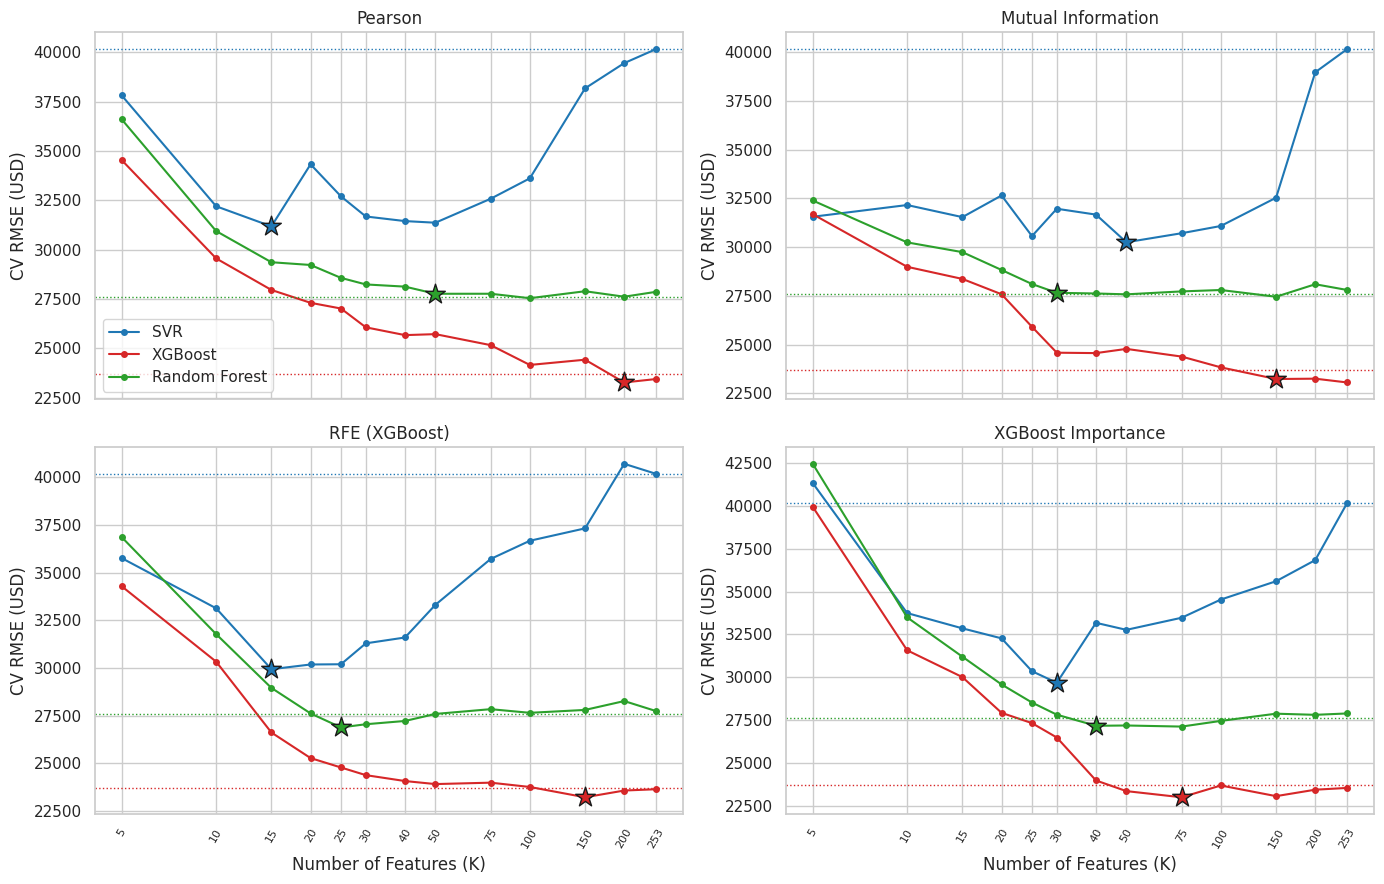

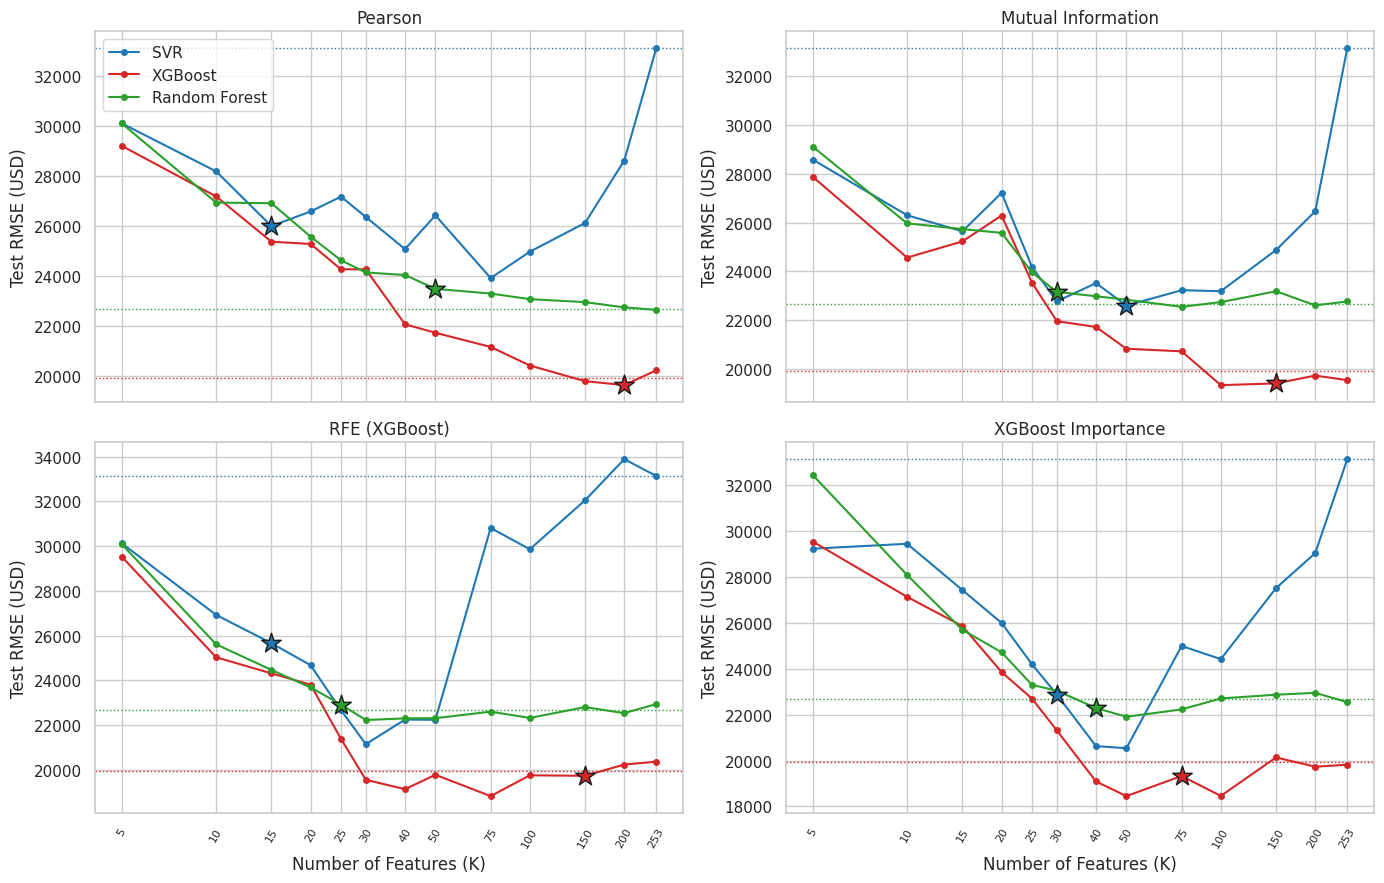

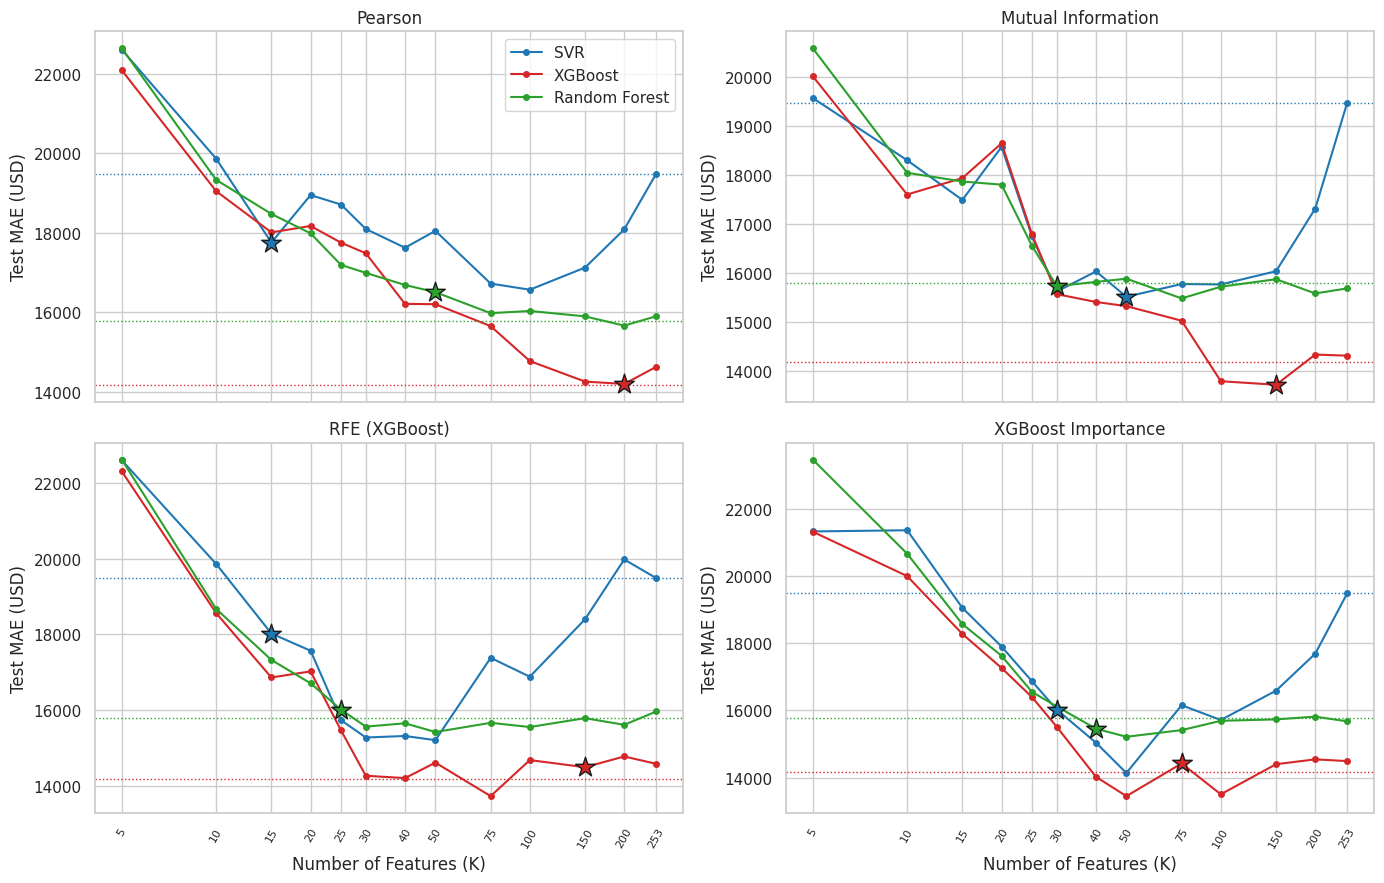

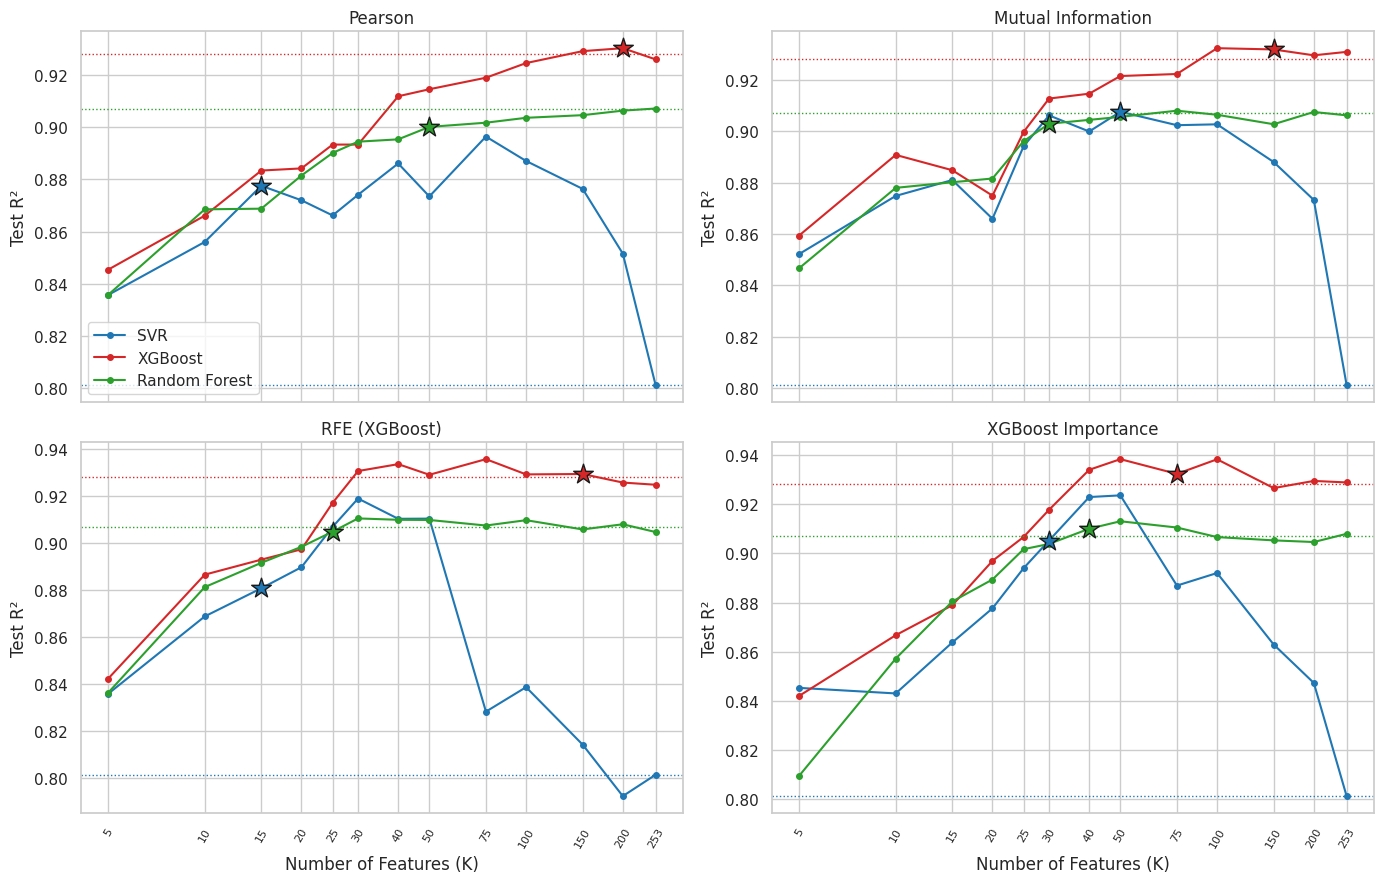

In [60]:
def select_best_k(df, tol=TOLERANCE):
    picks = []
    for (method, model), g in df.groupby(['Method', 'Model']):
        g = g.sort_values('Num_Features')
        row = g[g.CV_RMSE <= g.CV_RMSE.min() * (1 + tol)].iloc[0].copy()
        row['K_at_min_CV'] = g.loc[g.CV_RMSE.idxmin(), 'Num_Features']
        picks.append(row)
    return pd.DataFrame(picks).reset_index(drop=True)

best_by_method = select_best_k(fs_results)
COLORS = dict(zip(MODEL_NAMES, ['#1f77b4', '#d62728', '#2ca02c']))
base_idx = baseline_df.set_index('Model')

def plot_metric_vs_k(metric, ylabel, fname, baseline_col=None):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    for ax, method in zip(axes.ravel(), RANKERS):
        for name in MODEL_NAMES:
            g = fs_results[(fs_results.Method == method) & (fs_results.Model == name)].sort_values('Num_Features')
            ax.plot(g.Num_Features, g[metric], marker='o', ms=4, color=COLORS[name], label=name)
            if baseline_col: ax.axhline(base_idx.loc[name, baseline_col], color=COLORS[name], ls=':', lw=1)
            b = best_by_method[(best_by_method.Method == method) & (best_by_method.Model == name)].iloc[0]
            ax.scatter(b.Num_Features, g.loc[g.Num_Features == b.Num_Features, metric].iloc[0], marker='*', s=220, color=COLORS[name], edgecolor='k', zorder=5)
        ax.set_xscale('log'); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST, rotation=60, fontsize=8)
        ax.minorticks_off(); ax.set_title(method); ax.set_ylabel(ylabel)
    for ax in axes[1]: ax.set_xlabel('Number of Features (K)')
    axes[0, 0].legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

plot_metric_vs_k('CV_RMSE', 'CV RMSE (USD)', 'chart1a_cv_rmse_vs_k.png', baseline_col='CV_RMSE')
plot_metric_vs_k('RMSE', 'Test RMSE (USD)', 'chart1b_test_rmse_vs_k.png', baseline_col='RMSE')
plot_metric_vs_k('MAE', 'Test MAE (USD)', 'chart2_test_mae_vs_k.png', baseline_col='MAE')
plot_metric_vs_k('R2', 'Test R²', 'chart3_test_r2_vs_k.png', baseline_col='R2')

### 15. Best Feature Configuration
K tốt nhất theo CV (tolerance 1%) cho từng (phương pháp, model). Với mỗi model, cấu hình Feature Selection tốt nhất là phương pháp có CV RMSE thấp nhất trong các cấu hình đã chọn.

In [61]:
best_table = best_by_method[['Method', 'Model', 'Num_Features', 'K_at_min_CV', 'CV_RMSE', 'CV_RMSE_std', 'RMSE', 'MAE', 'R2', 'Training_Time']].rename(columns={'Num_Features': 'Best_K'})
display(best_table.sort_values(['Model', 'CV_RMSE']))
best_per_model = best_by_method.loc[best_by_method.groupby('Model').CV_RMSE.idxmin()].set_index('Model').loc[MODEL_NAMES]
best_per_model[['Method', 'Num_Features', 'CV_RMSE', 'RMSE', 'MAE', 'R2']]

,Method,Model,Best_K,K_at_min_CV,CV_RMSE,CV_RMSE_std,RMSE,MAE,R2,Training_Time
6,RFE (XGBoost),Random Forest,25,25,"26,879.1988","3,367.1388","22,918.5296","16,013.1905",0.9049,0.6397
9,XGBoost Importance,Random Forest,40,75,"27,175.1356","3,641.3737","22,289.9000","15,455.4690",0.9101,0.8296
0,Mutual Information,Random Forest,30,150,"27,654.3231","3,723.9606","23,165.1121","15,732.5110",0.9029,0.7841
3,Pearson,Random Forest,50,100,"27,762.9793","3,672.4617","23,497.0198","16,506.4391",0.9000,0.9588
10,XGBoost Importance,SVR,30,30,"29,681.1373","3,413.3086","22,878.4225","16,022.6652",0.9052,0.0849
7,RFE (XGBoost),SVR,15,15,"29,931.4224","3,862.4068","25,662.9187","18,023.8566",0.8808,0.0775
1,Mutual Information,SVR,50,50,"30,248.8948","7,462.6530","22,603.8122","15,515.4772",0.9075,0.0916
4,Pearson,SVR,15,15,"31,179.5827","5,245.0455","26,010.6296","17,753.1419",0.8775,0.0728
11,XGBoost Importance,XGBoost,75,75,"23,009.7398","3,055.5474","19,329.1771","14,421.8092",0.9324,0.2459
8,RFE (XGBoost),XGBoost,150,150,"23,219.1906","3,441.5785","19,734.8465","14,492.5578",0.9295,0.3575


,Method,Num_Features,CV_RMSE,RMSE,MAE,R2
Model,,,,,,
SVR,XGBoost Importance,30,"29,681.1373","22,878.4225","16,022.6652",0.9052
XGBoost,XGBoost Importance,75,"23,009.7398","19,329.1771","14,421.8092",0.9324
Random Forest,RFE (XGBoost),25,"26,879.1988","22,918.5296","16,013.1905",0.9049


### 16. Baseline vs Feature Selection

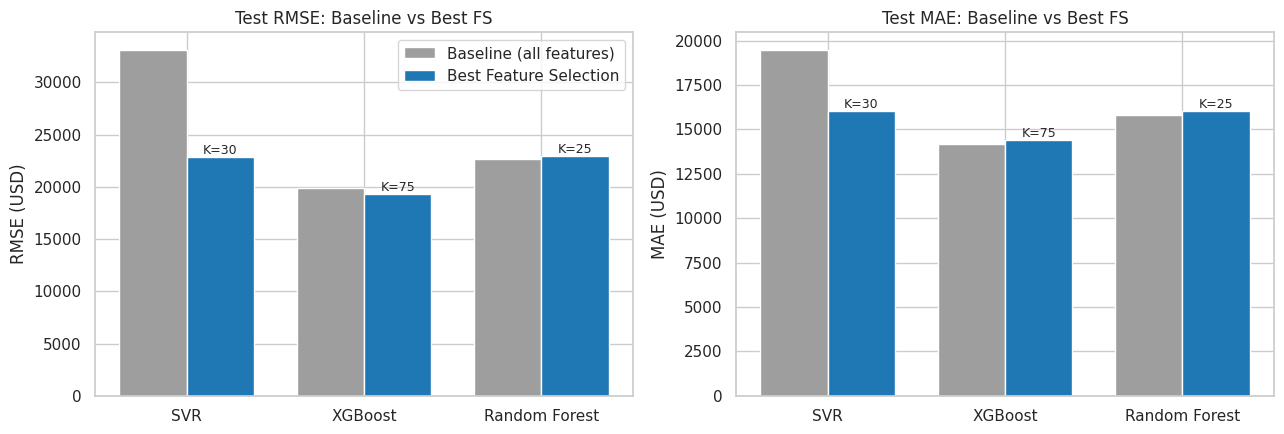

,Model,FS_Method,Best_K,Baseline_RMSE,FS_RMSE,RMSE_Improvement_%,Baseline_MAE,FS_MAE,MAE_Improvement_%,Baseline_R2,FS_R2,R2_Improvement_%,Baseline_CV_RMSE,FS_CV_RMSE,CV_RMSE_Improvement_%,FS_CV_RMSE_std,Baseline_Time,FS_Time,Time_Change_%
0,SVR,XGBoost Importance,30,"33,133.7719","22,878.4225",30.9513,"19,486.6295","16,022.6652",17.7761,0.8012,0.9052,12.9788,"40,169.7863","29,681.1373",26.1108,"3,413.3086",0.1522,0.0849,44.2688
1,XGBoost,XGBoost Importance,75,"19,930.4684","19,329.1771",3.0169,"14,180.1996","14,421.8092",-1.7039,0.9281,0.9324,0.4605,"23,701.0603","23,009.7398",2.9168,"3,055.5474",0.5560,0.2459,55.7770
2,Random Forest,RFE (XGBoost),25,"22,670.0135","22,918.5296",-1.0962,"15,787.3105","16,013.1905",-1.4308,0.9070,0.9049,-0.2261,"27,605.5414","26,879.1988",2.6311,"3,367.1388",1.6594,0.6397,61.4523


In [62]:
def improvement(base, fs, higher_is_better=False):
    return (fs - base) / abs(base) * 100 if higher_is_better else (base - fs) / base * 100

final_rows = []
for name in MODEL_NAMES:
    b, f = base_idx.loc[name], best_per_model.loc[name]
    final_rows.append({
        'Model': name, 'FS_Method': f.Method, 'Best_K': int(f.Num_Features),
        'Baseline_RMSE': b.RMSE, 'FS_RMSE': f.RMSE, 'RMSE_Improvement_%': improvement(b.RMSE, f.RMSE),
        'Baseline_MAE': b.MAE, 'FS_MAE': f.MAE, 'MAE_Improvement_%': improvement(b.MAE, f.MAE),
        'Baseline_R2': b.R2, 'FS_R2': f.R2, 'R2_Improvement_%': improvement(b.R2, f.R2, True),
        'Baseline_CV_RMSE': b.CV_RMSE, 'FS_CV_RMSE': f.CV_RMSE, 'CV_RMSE_Improvement_%': improvement(b.CV_RMSE, f.CV_RMSE),
        'FS_CV_RMSE_std': f.CV_RMSE_std,
        'Baseline_Time': b.Training_Time, 'FS_Time': f.Training_Time, 'Time_Change_%': improvement(b.Training_Time, f.Training_Time)})
final_df = pd.DataFrame(final_rows)
final_df.to_csv(OUT_DIR / 'final_results.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); w = 0.38; xs = np.arange(len(MODEL_NAMES))
for a, (bc, fc, lab) in zip(ax, [('Baseline_RMSE', 'FS_RMSE', 'RMSE (USD)'), ('Baseline_MAE', 'FS_MAE', 'MAE (USD)')]):
    a.bar(xs - w / 2, final_df[bc], w, label='Baseline (all features)', color='#9e9e9e')
    bars = a.bar(xs + w / 2, final_df[fc], w, label='Best Feature Selection', color='#1f77b4')
    for r, k in zip(bars, final_df.Best_K): a.text(r.get_x() + r.get_width() / 2, r.get_height(), f'K={k}', ha='center', va='bottom', fontsize=9)
    a.set_xticks(xs); a.set_xticklabels(MODEL_NAMES); a.set_ylabel(lab); a.set_title(f'Test {lab.split()[0]}: Baseline vs Best FS')
ax[0].legend(); plt.tight_layout(); plt.savefig(FIG_DIR / 'chart4_baseline_vs_best_fs.png', dpi=150); plt.show()
final_df

### 17. Final Comparison

In [63]:
summary_methods = best_table.assign(Group=best_table.Method.map({'Pearson': 'Filter', 'Mutual Information': 'Filter', 'RFE (XGBoost)': 'Wrapper', 'XGBoost Importance': 'Embedded'}))
summary_methods = summary_methods[['Group', 'Method', 'Model', 'Best_K', 'RMSE', 'MAE', 'R2', 'CV_RMSE']].sort_values(['Model', 'CV_RMSE'])
display(summary_methods)
print('Trung bình theo nhóm Feature Selection (CV RMSE, Test RMSE, Best K):')
display(summary_methods.groupby('Group')[['CV_RMSE', 'RMSE', 'Best_K']].mean())
print('Trung bình theo phương pháp:')
display(summary_methods.groupby('Method')[['CV_RMSE', 'RMSE', 'Best_K']].mean().sort_values('CV_RMSE'))
display(final_df[['Model', 'Baseline_RMSE', 'FS_RMSE', 'RMSE_Improvement_%', 'Baseline_MAE', 'FS_MAE', 'Baseline_R2', 'FS_R2', 'Best_K']])

,Group,Method,Model,Best_K,RMSE,MAE,R2,CV_RMSE
6,Wrapper,RFE (XGBoost),Random Forest,25,"22,918.5296","16,013.1905",0.9049,"26,879.1988"
9,Embedded,XGBoost Importance,Random Forest,40,"22,289.9000","15,455.4690",0.9101,"27,175.1356"
0,Filter,Mutual Information,Random Forest,30,"23,165.1121","15,732.5110",0.9029,"27,654.3231"
3,Filter,Pearson,Random Forest,50,"23,497.0198","16,506.4391",0.9000,"27,762.9793"
10,Embedded,XGBoost Importance,SVR,30,"22,878.4225","16,022.6652",0.9052,"29,681.1373"
7,Wrapper,RFE (XGBoost),SVR,15,"25,662.9187","18,023.8566",0.8808,"29,931.4224"
1,Filter,Mutual Information,SVR,50,"22,603.8122","15,515.4772",0.9075,"30,248.8948"
4,Filter,Pearson,SVR,15,"26,010.6296","17,753.1419",0.8775,"31,179.5827"
11,Embedded,XGBoost Importance,XGBoost,75,"19,329.1771","14,421.8092",0.9324,"23,009.7398"
8,Wrapper,RFE (XGBoost),XGBoost,150,"19,734.8465","14,492.5578",0.9295,"23,219.1906"


Trung bình theo nhóm Feature Selection (CV RMSE, Test RMSE, Best K):


,CV_RMSE,RMSE,Best_K
Group,,,
Embedded,"26,622.0042","21,499.1665",48.3333
Filter,"27,223.6423","22,389.7280",82.5000
Wrapper,"26,676.6039","22,772.0983",63.3333


Trung bình theo phương pháp:


,CV_RMSE,RMSE,Best_K
Method,,,
XGBoost Importance,"26,622.0042","21,499.1665",48.3333
RFE (XGBoost),"26,676.6039","22,772.0983",63.3333
Mutual Information,"27,044.2189","21,729.7551",76.6667
Pearson,"27,403.0656","23,049.7009",88.3333


,Model,Baseline_RMSE,FS_RMSE,RMSE_Improvement_%,Baseline_MAE,FS_MAE,Baseline_R2,FS_R2,Best_K
0,SVR,"33,133.7719","22,878.4225",30.9513,"19,486.6295","16,022.6652",0.8012,0.9052,30
1,XGBoost,"19,930.4684","19,329.1771",3.0169,"14,180.1996","14,421.8092",0.9281,0.9324,75
2,Random Forest,"22,670.0135","22,918.5296",-1.0962,"15,787.3105","16,013.1905",0.9070,0.9049,25


### 18. Conclusions
Các nhận xét được sinh trực tiếp từ DataFrame kết quả (không nhập tay số liệu) và lưu vào `findings.json` để báo cáo Word dùng lại.

In [64]:
def curve_summary():
    rows = []
    for (method, name), g in fs_results.groupby(['Method', 'Model']):
        g = g.sort_values('Num_Features').reset_index(drop=True)
        mn, k_min = g.CV_RMSE.min(), g.loc[g.CV_RMSE.idxmin(), 'Num_Features']
        gains = (g.CV_RMSE.shift(1) - g.CV_RMSE) / g.CV_RMSE.shift(1)
        flat = [int(k) for k, gn in zip(g.Num_Features, gains) if pd.notna(gn) and gn < TOLERANCE]
        rows.append({'Method': method, 'Model': name, 'CV_RMSE_K5': g.CV_RMSE.iloc[0], 'CV_RMSE_All': g.CV_RMSE.iloc[-1],
                     'CV_RMSE_Min': mn, 'K_at_Min': int(k_min), 'Gap_All_vs_Min_%': (g.CV_RMSE.iloc[-1] / mn - 1) * 100,
                     'Gap_K5_vs_Min_%': (g.CV_RMSE.iloc[0] / mn - 1) * 100, 'Steps_without_gain': len(flat),
                     'U_shape': bool(k_min < g.Num_Features.max() and g.CV_RMSE.iloc[-1] > mn * (1 + TOLERANCE))})
    return pd.DataFrame(rows)
curve_df = curve_summary()
display(curve_df)

def build_findings():
    f = {}
    chg = lambda v: f'sai số giảm {v:.2f}%' if v > 0 else f'sai số tăng {-v:.2f}%'
    tchg = lambda v: f'giảm {v:.0f}%' if v > 0 else f'tăng {-v:.0f}%'
    n_imp = int((final_df['RMSE_Improvement_%'] > 0).sum())
    f['q8_fs_vs_baseline'] = (f'Theo Test RMSE, Feature Selection tốt nhất (chọn bằng CV) cải thiện Baseline ở {n_imp}/{len(final_df)} model: ' +
        '; '.join(f"{r.Model} {chg(r['RMSE_Improvement_%'])} (K={r.Best_K}, {r.FS_Method})" for _, r in final_df.iterrows()) +
        '. Theo CV RMSE: ' + '; '.join(f"{r.Model} {chg(r['CV_RMSE_Improvement_%'])}" for _, r in final_df.iterrows()) + '.')
    g_model = summary_methods.groupby('Model')
    f['q_best_model'] = 'Model có Test RMSE thấp nhất sau FS: ' + final_df.loc[final_df.FS_RMSE.idxmin(), 'Model'] + f" (RMSE = {final_df.FS_RMSE.min():,.0f} USD, R² = {final_df.loc[final_df.FS_RMSE.idxmin(), 'FS_R2']:.4f}); Baseline tốt nhất: " + baseline_df.loc[baseline_df.RMSE.idxmin(), 'Model'] + f" (RMSE = {baseline_df.RMSE.min():,.0f} USD)."
    by_method = summary_methods.groupby('Method')[['CV_RMSE', 'RMSE', 'Best_K']].mean().sort_values('CV_RMSE')
    f['q_best_method'] = 'Xếp theo CV RMSE trung bình trên 3 model: ' + '; '.join(f"{m} (CV RMSE {r.CV_RMSE:,.0f}, Test RMSE {r.RMSE:,.0f}, K trung bình {r.Best_K:.0f})" for m, r in by_method.iterrows()) + '.'
    f['q_best_k'] = '; '.join(f"{r.Model}: K={r.Best_K} ({r.FS_Method})" for _, r in final_df.iterrows())
    sens = curve_df.groupby('Model')['Gap_K5_vs_Min_%'].median().sort_values(ascending=False)
    f['q_sensitivity'] = 'Mức tăng CV RMSE khi chỉ giữ 5 feature so với điểm tốt nhất (trung vị 4 phương pháp): ' + '; '.join(f'{m} +{v:.1f}%' for m, v in sens.items()) + f'. Model nhạy nhất: {sens.index[0]}; ít nhạy nhất: {sens.index[-1]}.'
    f['q_stability'] = 'Độ biến thiên CV RMSE giữa các fold ở cấu hình chọn (std/mean): ' + '; '.join(f"{r.Model} {r.FS_CV_RMSE_std / r.FS_CV_RMSE * 100:.1f}%" for _, r in final_df.iterrows()) + '.'
    u = curve_df[curve_df.U_shape]
    f['q_u_shape'] = (f'Có {len(u)}/{len(curve_df)} cặp (phương pháp, model) mà CV RMSE ở toàn bộ feature cao hơn mức thấp nhất hơn {TOLERANCE:.0%} (dạng giảm rồi tăng): ' +
        '; '.join(f"{r.Model}/{r.Method} (tốt nhất tại K={r.K_at_Min}, toàn bộ feature kém {r['Gap_All_vs_Min_%']:.1f}%)" for _, r in u.iterrows()) + '.') if len(u) else 'Không có cặp nào có CV RMSE ở toàn bộ feature cao hơn mức thấp nhất quá tolerance.'
    f['q_noise'] = ('Các cặp trên cho thấy bỏ bớt feature giúp giảm sai số, tức có dấu hiệu feature nhiễu/dư thừa với model đó.' if len(u) else 'Chưa thấy bằng chứng rõ về feature nhiễu: thêm feature không làm CV RMSE xấu đi quá tolerance.')
    f['q_no_gain'] = '; '.join(f"{n}: {int(g.Steps_without_gain.sum())}/{len(g) * (len(K_LIST) - 1)} bước tăng K có mức cải thiện CV RMSE < {TOLERANCE:.0%}" for n, g in curve_df.groupby('Model')) + '.'
    near = final_df[final_df['CV_RMSE_Improvement_%'] > -TOLERANCE * 100].copy()
    f['q_same_perf'] = '; '.join(f"{r.Model}: giảm từ {N_FEATURES} xuống {r.Best_K} feature (-{(1 - r.Best_K / N_FEATURES) * 100:.0f}%) với CV RMSE {chg(r['CV_RMSE_Improvement_%'])}, Test RMSE {chg(r['RMSE_Improvement_%'])} so với baseline" for _, r in final_df.iterrows()) + '.'
    f['q_time'] = '; '.join(f"{r.Model}: {r.Baseline_Time:.3f}s -> {r.FS_Time:.3f}s ({tchg(r['Time_Change_%'])})" for _, r in final_df.iterrows()) + ' (thời gian fit một lần trên toàn bộ train, đo trong notebook; có nhiễu do tải máy).'
    f['q_complexity'] = f'Số feature giảm từ {N_FEATURES} xuống ' + ', '.join(f"{r.Best_K} ({r.Model})" for _, r in final_df.iterrows()) + '; mô hình dùng ít đầu vào hơn, dễ diễn giải hơn.'
    f['rfecv'] = f'RFECV (XGBoost, 3-fold CV trên train) tự chọn {RFECV_N} feature, so với K của đường cong RFE ở bảng best_K.'
    f['timing_rank'] = f'Thời gian xếp hạng trên train: Pearson {t_p:.2f}s, MI {t_m:.2f}s, XGBoost importance {t_x:.2f}s, RFE {t_rfe:.1f}s.'
    return f
findings = build_findings()
json.dump({'findings': findings, 'n_features': N_FEATURES, 'k_list': K_LIST, 'rfecv_n': RFECV_N, 'tolerance': TOLERANCE,
           'n_train': len(X_train), 'n_test': len(X_test), 'n_outliers_removed': int(outlier_mask.sum()),
           'rank_time': {'Pearson': t_p, 'Mutual Information': t_m, 'XGBoost Importance': t_x, 'RFE (XGBoost)': t_rfe, 'RFECV': t_rfecv},
           'best_params': {k: {a: (float(b) if hasattr(b, 'item') else b) for a, b in v.items()} for k, v in best_params.items()}},
          open(OUT_DIR / 'findings.json', 'w'), ensure_ascii=False, indent=1)
curve_df.to_csv(OUT_DIR / 'curve_summary.csv', index=False)
display(Markdown('\n'.join(f'- **{k}**: {v}' for k, v in findings.items())))

,Method,Model,CV_RMSE_K5,CV_RMSE_All,CV_RMSE_Min,K_at_Min,Gap_All_vs_Min_%,Gap_K5_vs_Min_%,Steps_without_gain,U_shape
0,Mutual Information,Random Forest,"32,393.4157","27,799.0263","27,452.3300",150,1.2629,17.9988,5,True
1,Mutual Information,SVR,"31,558.6169","40,169.7863","30,248.8948",50,32.7975,4.3298,9,True
2,Mutual Information,XGBoost,"31,689.4454","23,052.2774","23,052.2774",253,0.0000,37.4677,4,False
3,Pearson,Random Forest,"36,602.5889","27,862.8662","27,537.8463",100,1.1803,32.9174,7,True
4,Pearson,SVR,"37,815.3769","40,169.7863","31,179.5827",15,28.8336,21.2825,8,True
5,Pearson,XGBoost,"34,537.8736","23,442.0706","23,266.6349",200,0.7540,48.4438,3,False
6,RFE (XGBoost),Random Forest,"36,854.4025","27,734.9279","26,879.1988",25,3.1836,37.1112,7,True
7,RFE (XGBoost),SVR,"35,755.5084","40,169.7863","29,931.4224",15,34.2061,19.4581,9,True
8,RFE (XGBoost),XGBoost,"34,278.6561","23,641.5569","23,219.1906",150,1.8190,47.6307,5,True
9,XGBoost Importance,Random Forest,"42,440.1561","27,894.8086","27,129.2000",75,2.8221,56.4372,6,True


- **q8_fs_vs_baseline**: Theo Test RMSE, Feature Selection tốt nhất (chọn bằng CV) cải thiện Baseline ở 2/3 model: SVR sai số giảm 30.95% (K=30, XGBoost Importance); XGBoost sai số giảm 3.02% (K=75, XGBoost Importance); Random Forest sai số tăng 1.10% (K=25, RFE (XGBoost)). Theo CV RMSE: SVR sai số giảm 26.11%; XGBoost sai số giảm 2.92%; Random Forest sai số giảm 2.63%.
- **q_best_model**: Model có Test RMSE thấp nhất sau FS: XGBoost (RMSE = 19,329 USD, R² = 0.9324); Baseline tốt nhất: XGBoost (RMSE = 19,930 USD).
- **q_best_method**: Xếp theo CV RMSE trung bình trên 3 model: XGBoost Importance (CV RMSE 26,622, Test RMSE 21,499, K trung bình 48); RFE (XGBoost) (CV RMSE 26,677, Test RMSE 22,772, K trung bình 63); Mutual Information (CV RMSE 27,044, Test RMSE 21,730, K trung bình 77); Pearson (CV RMSE 27,403, Test RMSE 23,050, K trung bình 88).
- **q_best_k**: SVR: K=30 (XGBoost Importance); XGBoost: K=75 (XGBoost Importance); Random Forest: K=25 (RFE (XGBoost))
- **q_sensitivity**: Mức tăng CV RMSE khi chỉ giữ 5 feature so với điểm tốt nhất (trung vị 4 phương pháp): XGBoost +48.0%; Random Forest +35.0%; SVR +20.4%. Model nhạy nhất: XGBoost; ít nhạy nhất: SVR.
- **q_stability**: Độ biến thiên CV RMSE giữa các fold ở cấu hình chọn (std/mean): SVR 11.5%; XGBoost 13.3%; Random Forest 12.5%.
- **q_u_shape**: Có 10/12 cặp (phương pháp, model) mà CV RMSE ở toàn bộ feature cao hơn mức thấp nhất hơn 1% (dạng giảm rồi tăng): Random Forest/Mutual Information (tốt nhất tại K=150, toàn bộ feature kém 1.3%); SVR/Mutual Information (tốt nhất tại K=50, toàn bộ feature kém 32.8%); Random Forest/Pearson (tốt nhất tại K=100, toàn bộ feature kém 1.2%); SVR/Pearson (tốt nhất tại K=15, toàn bộ feature kém 28.8%); Random Forest/RFE (XGBoost) (tốt nhất tại K=25, toàn bộ feature kém 3.2%); SVR/RFE (XGBoost) (tốt nhất tại K=15, toàn bộ feature kém 34.2%); XGBoost/RFE (XGBoost) (tốt nhất tại K=150, toàn bộ feature kém 1.8%); Random Forest/XGBoost Importance (tốt nhất tại K=75, toàn bộ feature kém 2.8%); SVR/XGBoost Importance (tốt nhất tại K=30, toàn bộ feature kém 35.3%); XGBoost/XGBoost Importance (tốt nhất tại K=75, toàn bộ feature kém 2.4%).
- **q_noise**: Các cặp trên cho thấy bỏ bớt feature giúp giảm sai số, tức có dấu hiệu feature nhiễu/dư thừa với model đó.
- **q_no_gain**: Random Forest: 25/48 bước tăng K có mức cải thiện CV RMSE < 1%; SVR: 32/48 bước tăng K có mức cải thiện CV RMSE < 1%; XGBoost: 15/48 bước tăng K có mức cải thiện CV RMSE < 1%.
- **q_same_perf**: SVR: giảm từ 253 xuống 30 feature (-88%) với CV RMSE sai số giảm 26.11%, Test RMSE sai số giảm 30.95% so với baseline; XGBoost: giảm từ 253 xuống 75 feature (-70%) với CV RMSE sai số giảm 2.92%, Test RMSE sai số giảm 3.02% so với baseline; Random Forest: giảm từ 253 xuống 25 feature (-90%) với CV RMSE sai số giảm 2.63%, Test RMSE sai số tăng 1.10% so với baseline.
- **q_time**: SVR: 0.152s -> 0.085s (giảm 44%); XGBoost: 0.556s -> 0.246s (giảm 56%); Random Forest: 1.659s -> 0.640s (giảm 61%) (thời gian fit một lần trên toàn bộ train, đo trong notebook; có nhiễu do tải máy).
- **q_complexity**: Số feature giảm từ 253 xuống 30 (SVR), 75 (XGBoost), 25 (Random Forest); mô hình dùng ít đầu vào hơn, dễ diễn giải hơn.
- **rfecv**: RFECV (XGBoost, 3-fold CV trên train) tự chọn 118 feature, so với K của đường cong RFE ở bảng best_K.
- **timing_rank**: Thời gian xếp hạng trên train: Pearson 0.04s, MI 0.94s, XGBoost importance 0.48s, RFE 4.6s.

### 19. Export Experiment Log
Mỗi dòng nhật ký là một thí nghiệm thực tế đã chạy trong notebook; cột `Decision` được gán theo quy tắc dựa trên CV (xem sheet `Decision_Rules` trong file Excel).

In [65]:
def save_experiment_log():
    today = datetime.now().strftime('%Y-%m-%d')
    rows = []
    def add(stage, method, model, k, feats, m=None, status='Hoàn thành', obs='', decision='Giữ', cv_m=None, params=''):
        m = {} if m is None else m
        cv_m = {} if cv_m is None else cv_m
        rows.append({'Date': today, 'Stage': stage, 'Method': method, 'Model': model, 'Num_Features': k, 'Features': feats,
                     'RMSE': m['RMSE'] if 'RMSE' in m else None, 'MAE': m['MAE'] if 'MAE' in m else None, 'R2': m['R2'] if 'R2' in m else None, 'Training_Time': m['Training_Time'] if 'Training_Time' in m else None,
                     'Status': status, 'Observation': obs, 'Decision': decision,
                     'CV_RMSE': cv_m['CV_RMSE'] if 'CV_RMSE' in cv_m else None, 'CV_MAE': cv_m['CV_MAE'] if 'CV_MAE' in cv_m else None, 'CV_R2': cv_m['CV_R2'] if 'CV_R2' in cv_m else None, 'Params': params})
    add('Preprocessing', 'Clean + Impute + One-hot', '-', N_FEATURES, 'All',
        obs=f'{len(X_train)} train / {len(X_test)} test; loại {int(outlier_mask.sum())} outlier; {N_FEATURES} feature sau encoding; preprocessor fit trên train')
    for _, r in tuning_df.iterrows():
        add('Hyperparameter Tuning', 'GridSearchCV 5-fold (All features)', r.Model, N_FEATURES, 'All',
            obs=f'Best params {r.Best_Params}; CV RMSLE = {r.CV_RMSLE:.4f}', params=str(r.Best_Params))
    for _, r in baseline_df.iterrows():
        add('Baseline', 'All features', r.Model, N_FEATURES, 'All', m=r, cv_m=r,
            obs=f'Baseline; CV RMSE = {r.CV_RMSE:,.0f}; Test R2 = {r.R2:.4f}', decision='Giữ', params=r.Params)
    for method, order in final_order.items():
        add('Feature Ranking', method, '-' if 'Pearson' in method or 'Mutual' in method else 'XGBoost', N_FEATURES, ', '.join(order[:10]),
            obs=f'Top 10 feature theo {method}; ranking tính chỉ trên train')
    add('Feature Ranking', 'RFECV (XGBoost, 3-fold)', 'XGBoost', RFECV_N, ', '.join(X_train.columns[rfecv.support_][:10]) + ' ...',
        obs=f'RFECV tự chọn {RFECV_N} feature (tham khảo); {t_rfecv:.0f}s', decision='Giữ')
    chosen = best_by_method.set_index(['Method', 'Model']).Num_Features.to_dict()
    overall = {(r.FS_Method, r.Model) for _, r in final_df.iterrows()}
    base_rmse = base_idx.RMSE.to_dict()
    for _, r in fs_results.iterrows():
        bk = chosen[(r.Method, r.Model)]
        cv_min = fs_results[(fs_results.Method == r.Method) & (fs_results.Model == r.Model)].CV_RMSE.min()
        within = r.CV_RMSE <= cv_min * (1 + TOLERANCE)
        if r.Num_Features == bk:
            decision = 'Chọn làm best configuration' if (r.Method, r.Model) in overall else 'Giữ'
            note = 'K nhỏ nhất trong tolerance 1% của CV RMSE tốt nhất'
        elif r.Num_Features < bk:
            decision, note = 'Tiếp tục thử', 'CV RMSE chưa nằm trong tolerance 1%'
        elif within:
            decision, note = 'Loại', 'Tương đương trong tolerance nhưng nhiều feature hơn'
        else:
            decision, note = 'Loại', 'CV RMSE kém hơn mức tốt nhất quá tolerance'
        k = int(r.Num_Features)
        feats = f'All ({N_FEATURES})' if k == N_FEATURES else ', '.join(final_order[r.Method][:k])
        add('Feature Selection', r.Method, r.Model, k, feats, m=r, cv_m=r,
            obs=f'{note}; CV RMSE = {r.CV_RMSE:,.0f}; Test RMSE {(r.RMSE / base_rmse[r.Model] - 1) * 100:+.2f}% so với baseline', decision=decision,
            params=str(best_params[r.Model]))
    for _, r in final_df.iterrows():
        add('Final Comparison', r.FS_Method, r.Model, r.Best_K, f'Top {r.Best_K} theo {r.FS_Method}',
            m={'RMSE': r.FS_RMSE, 'MAE': r.FS_MAE, 'R2': r.FS_R2, 'Training_Time': r.FS_Time},
            cv_m={'CV_RMSE': r.FS_CV_RMSE}, obs=f"RMSE {r['RMSE_Improvement_%']:+.2f}%, MAE {r['MAE_Improvement_%']:+.2f}%, R2 {r['R2_Improvement_%']:+.2f}% so với baseline",
            decision='Chọn làm best configuration')
    log = pd.DataFrame(rows)
    log.insert(0, 'Experiment_ID', [f'EXP{i:03d}' for i in range(1, len(log) + 1)])
    log.to_csv(OUT_DIR / 'experiment_log.csv', index=False)

    rules = pd.DataFrame({'Decision': ['Chọn làm best configuration', 'Giữ', 'Tiếp tục thử', 'Loại'], 'Quy tắc': [
        'Cấu hình có K nhỏ nhất trong tolerance 1% của CV RMSE tốt nhất, và là cấu hình có CV RMSE thấp nhất của model đó giữa các phương pháp FS',
        'Mốc/phiên bản được giữ lại (baseline, tuning, ranking) hoặc K tốt nhất của một phương pháp nhưng không phải tốt nhất của model',
        'K nhỏ hơn K được chọn: CV RMSE chưa vào tolerance 1%, phải tăng K',
        'K lớn hơn K được chọn: tương đương trong tolerance nhưng phức tạp hơn, hoặc kém hơn quá tolerance']})
    with pd.ExcelWriter(OUT_DIR / 'Experiment_Log.xlsx', engine='openpyxl') as xw:
        log.to_excel(xw, sheet_name='Experiment_Log', index=False); rules.to_excel(xw, sheet_name='Decision_Rules', index=False)
        from openpyxl.styles import Font, PatternFill, Alignment
        for ws in xw.book.worksheets:
            for c in ws[1]:
                c.font = Font(name='Arial', bold=True, color='FFFFFF'); c.fill = PatternFill('solid', fgColor='1F4E78')
                c.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
            for row in ws.iter_rows(min_row=2):
                for c in row: c.font = Font(name='Arial', size=10)
            ws.freeze_panes = 'A2'; ws.auto_filter.ref = ws.dimensions
        ws = xw.sheets['Experiment_Log']
        widths = dict(A=12, B=11, C=20, D=26, E=14, F=13, G=36, H=12, I=12, J=9, K=13, L=11, M=55, N=26, O=12, P=12, Q=9, R=30)
        for col, w in widths.items(): ws.column_dimensions[col].width = w
        for row in ws.iter_rows(min_row=2):
            for c in row:
                if c.column_letter in 'HIL' and c.value is not None: c.number_format = '#,##0.00' if c.column_letter != 'L' else '0.000'
                if c.column_letter in 'OP' and c.value is not None: c.number_format = '#,##0.00'
                if c.column_letter == 'J' and c.value is not None: c.number_format = '0.0000'
                if c.column_letter == 'Q' and c.value is not None: c.number_format = '0.0000'
        xw.sheets['Decision_Rules'].column_dimensions['A'].width = 30; xw.sheets['Decision_Rules'].column_dimensions['B'].width = 120
    return log

experiment_log = save_experiment_log()
best_feats = best_by_method[['Method', 'Model', 'Num_Features']].copy()
best_feats['Features'] = [', '.join(final_order[m][:k]) for m, k in zip(best_feats.Method, best_feats.Num_Features)]
best_feats.to_csv(OUT_DIR / 'best_features.csv', index=False)
print(experiment_log.shape); print(experiment_log.Decision.value_counts().to_string())
print(sorted(p.name for p in OUT_DIR.iterdir()))

(171, 18)
Decision
Tiếp tục thử                   77
Loại                           67
Giữ                            21
Chọn làm best configuration     6
['Experiment_Log.xlsx', 'baseline_results.csv', 'best_features.csv', 'curve_summary.csv', 'experiment_log.csv', 'feature_rankings.csv', 'feature_selection_results.csv', 'figures', 'final_results.csv', 'findings.json']
